# Home Credit Default Risk Dataset Project

# Part 2 - Analysis of Supplementary Data

This is Part 2 of the Home Credit Project for Machine Learning Capstone Project project of Machine Learning module sprint 4. In this part, additional data provided will be explored. That is the additional csv which are included in this project: 

- Bureau
- Bureau balance
- Pos cash balance
- Credit card balance
- Previous application
- Installments payments

## Importing Dataset and Packages

In [1]:
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt
from matplotlib.ticker import FuncFormatter
import missingno as msno
import duckdb as db
from sklearn.preprocessing import OneHotEncoder
from scipy import stats
from scripts import *

pd.set_option('display.max_rows', 300)

### Importing Data

In [2]:
bureau_balance = pd.read_csv('home-credit-default-risk/bureau_balance.csv')
bureau_balance.head()

,SK_ID_BUREAU,MONTHS_BALANCE,STATUS
0,5715448,0,C
1,5715448,-1,C
2,5715448,-2,C
3,5715448,-3,C
4,5715448,-4,C


In [3]:
bureau = pd.read_csv('home-credit-default-risk/bureau.csv')
bureau.head()

,SK_ID_CURR,SK_ID_BUREAU,CREDIT_ACTIVE,CREDIT_CURRENCY,DAYS_CREDIT,CREDIT_DAY_OVERDUE,DAYS_CREDIT_ENDDATE,DAYS_ENDDATE_FACT,AMT_CREDIT_MAX_OVERDUE,CNT_CREDIT_PROLONG,AMT_CREDIT_SUM,AMT_CREDIT_SUM_DEBT,AMT_CREDIT_SUM_LIMIT,AMT_CREDIT_SUM_OVERDUE,CREDIT_TYPE,DAYS_CREDIT_UPDATE,AMT_ANNUITY
0,215354,5714462,Closed,currency 1,-497,0,-153.0,-153.0,NaN,0,91323.0,0.0,NaN,0.0,Consumer credit,-131,NaN
1,215354,5714463,Active,currency 1,-208,0,1075.0,NaN,NaN,0,225000.0,171342.0,NaN,0.0,Credit card,-20,NaN
2,215354,5714464,Active,currency 1,-203,0,528.0,NaN,NaN,0,464323.5,NaN,NaN,0.0,Consumer credit,-16,NaN
3,215354,5714465,Active,currency 1,-203,0,NaN,NaN,NaN,0,90000.0,NaN,NaN,0.0,Credit card,-16,NaN
4,215354,5714466,Active,currency 1,-629,0,1197.0,NaN,77674.5,0,2700000.0,NaN,NaN,0.0,Consumer credit,-21,NaN


In [4]:
credit_card_balance = pd.read_csv('home-credit-default-risk/credit_card_balance.csv')
credit_card_balance.head()

,SK_ID_PREV,SK_ID_CURR,MONTHS_BALANCE,AMT_BALANCE,AMT_CREDIT_LIMIT_ACTUAL,AMT_DRAWINGS_ATM_CURRENT,AMT_DRAWINGS_CURRENT,AMT_DRAWINGS_OTHER_CURRENT,AMT_DRAWINGS_POS_CURRENT,AMT_INST_MIN_REGULARITY,...,AMT_RECIVABLE,AMT_TOTAL_RECEIVABLE,CNT_DRAWINGS_ATM_CURRENT,CNT_DRAWINGS_CURRENT,CNT_DRAWINGS_OTHER_CURRENT,CNT_DRAWINGS_POS_CURRENT,CNT_INSTALMENT_MATURE_CUM,NAME_CONTRACT_STATUS,SK_DPD,SK_DPD_DEF
0,2562384,378907,-6,56.970,135000,0.0,877.5,0.0,877.5,1700.325,...,0.000,0.000,0.0,1,0.0,1.0,35.0,Active,0,0
1,2582071,363914,-1,63975.555,45000,2250.0,2250.0,0.0,0.0,2250.000,...,64875.555,64875.555,1.0,1,0.0,0.0,69.0,Active,0,0
2,1740877,371185,-7,31815.225,450000,0.0,0.0,0.0,0.0,2250.000,...,31460.085,31460.085,0.0,0,0.0,0.0,30.0,Active,0,0
3,1389973,337855,-4,236572.110,225000,2250.0,2250.0,0.0,0.0,11795.760,...,233048.970,233048.970,1.0,1,0.0,0.0,10.0,Active,0,0
4,1891521,126868,-1,453919.455,450000,0.0,11547.0,0.0,11547.0,22924.890,...,453919.455,453919.455,0.0,1,0.0,1.0,101.0,Active,0,0


In [5]:
installments_payments = pd.read_csv('home-credit-default-risk/installments_payments.csv')
installments_payments.head()

,SK_ID_PREV,SK_ID_CURR,NUM_INSTALMENT_VERSION,NUM_INSTALMENT_NUMBER,DAYS_INSTALMENT,DAYS_ENTRY_PAYMENT,AMT_INSTALMENT,AMT_PAYMENT
0,1054186,161674,1.0,6,-1180.0,-1187.0,6948.360,6948.360
1,1330831,151639,0.0,34,-2156.0,-2156.0,1716.525,1716.525
2,2085231,193053,2.0,1,-63.0,-63.0,25425.000,25425.000
3,2452527,199697,1.0,3,-2418.0,-2426.0,24350.130,24350.130
4,2714724,167756,1.0,2,-1383.0,-1366.0,2165.040,2160.585


In [6]:
pos_cash = pd.read_csv('home-credit-default-risk/POS_CASH_balance.csv')
pos_cash.head()

,SK_ID_PREV,SK_ID_CURR,MONTHS_BALANCE,CNT_INSTALMENT,CNT_INSTALMENT_FUTURE,NAME_CONTRACT_STATUS,SK_DPD,SK_DPD_DEF
0,1803195,182943,-31,48.0,45.0,Active,0,0
1,1715348,367990,-33,36.0,35.0,Active,0,0
2,1784872,397406,-32,12.0,9.0,Active,0,0
3,1903291,269225,-35,48.0,42.0,Active,0,0
4,2341044,334279,-35,36.0,35.0,Active,0,0


In [7]:
previous_application = pd.read_csv('home-credit-default-risk/previous_application.csv')
previous_application.head()

,SK_ID_PREV,SK_ID_CURR,NAME_CONTRACT_TYPE,AMT_ANNUITY,AMT_APPLICATION,AMT_CREDIT,AMT_DOWN_PAYMENT,AMT_GOODS_PRICE,WEEKDAY_APPR_PROCESS_START,HOUR_APPR_PROCESS_START,...,NAME_SELLER_INDUSTRY,CNT_PAYMENT,NAME_YIELD_GROUP,PRODUCT_COMBINATION,DAYS_FIRST_DRAWING,DAYS_FIRST_DUE,DAYS_LAST_DUE_1ST_VERSION,DAYS_LAST_DUE,DAYS_TERMINATION,NFLAG_INSURED_ON_APPROVAL
0,2030495,271877,Consumer loans,1730.430,17145.0,17145.0,0.0,17145.0,SATURDAY,15,...,Connectivity,12.0,middle,POS mobile with interest,365243.0,-42.0,300.0,-42.0,-37.0,0.0
1,2802425,108129,Cash loans,25188.615,607500.0,679671.0,NaN,607500.0,THURSDAY,11,...,XNA,36.0,low_action,Cash X-Sell: low,365243.0,-134.0,916.0,365243.0,365243.0,1.0
2,2523466,122040,Cash loans,15060.735,112500.0,136444.5,NaN,112500.0,TUESDAY,11,...,XNA,12.0,high,Cash X-Sell: high,365243.0,-271.0,59.0,365243.0,365243.0,1.0
3,2819243,176158,Cash loans,47041.335,450000.0,470790.0,NaN,450000.0,MONDAY,7,...,XNA,12.0,middle,Cash X-Sell: middle,365243.0,-482.0,-152.0,-182.0,-177.0,1.0
4,1784265,202054,Cash loans,31924.395,337500.0,404055.0,NaN,337500.0,THURSDAY,9,...,XNA,24.0,high,Cash Street: high,NaN,NaN,NaN,NaN,NaN,NaN


In [8]:
HomeCredit_columns_description = pd.read_csv(
    'home-credit-default-risk/HomeCredit_columns_description.csv', encoding="ISO-8859-1", index_col=0
)
HomeCredit_columns_description.head()

,Table,Row,Description,Special
1,application_{train|test}.csv,SK_ID_CURR,ID of loan in our sample,NaN
2,application_{train|test}.csv,TARGET,Target variable (1 - client with payment diffi...,NaN
5,application_{train|test}.csv,NAME_CONTRACT_TYPE,Identification if loan is cash or revolving,NaN
6,application_{train|test}.csv,CODE_GENDER,Gender of the client,NaN
7,application_{train|test}.csv,FLAG_OWN_CAR,Flag if the client owns a car,NaN


# Bureau

## Checking For Nulls and Duplicates

### Duplicates

In [9]:
bureau.duplicated().any()

np.False_

In [10]:
bureau.columns.duplicated().any()

np.False_

### Missing Values

In [11]:
bureaunullresults = bureau.isnull().sum()
rows_nr = bureau.shape[0]
for item in bureau.columns:
    missing_nr = bureaunullresults[item]
    if missing_nr > 0:
        missing_perc = count_percentage(missing_nr, rows_nr, round_value=4)
        print(f'The percentage of missing {item} values is {missing_perc}%.')

The percentage of missing DAYS_CREDIT_ENDDATE values is 6.1496%.
The percentage of missing DAYS_ENDDATE_FACT values is 36.917%.
The percentage of missing AMT_CREDIT_MAX_OVERDUE values is 65.5133%.
The percentage of missing AMT_CREDIT_SUM values is 0.0008%.
The percentage of missing AMT_CREDIT_SUM_DEBT values is 15.0119%.
The percentage of missing AMT_CREDIT_SUM_LIMIT values is 34.4774%.
The percentage of missing AMT_ANNUITY values is 71.4735%.


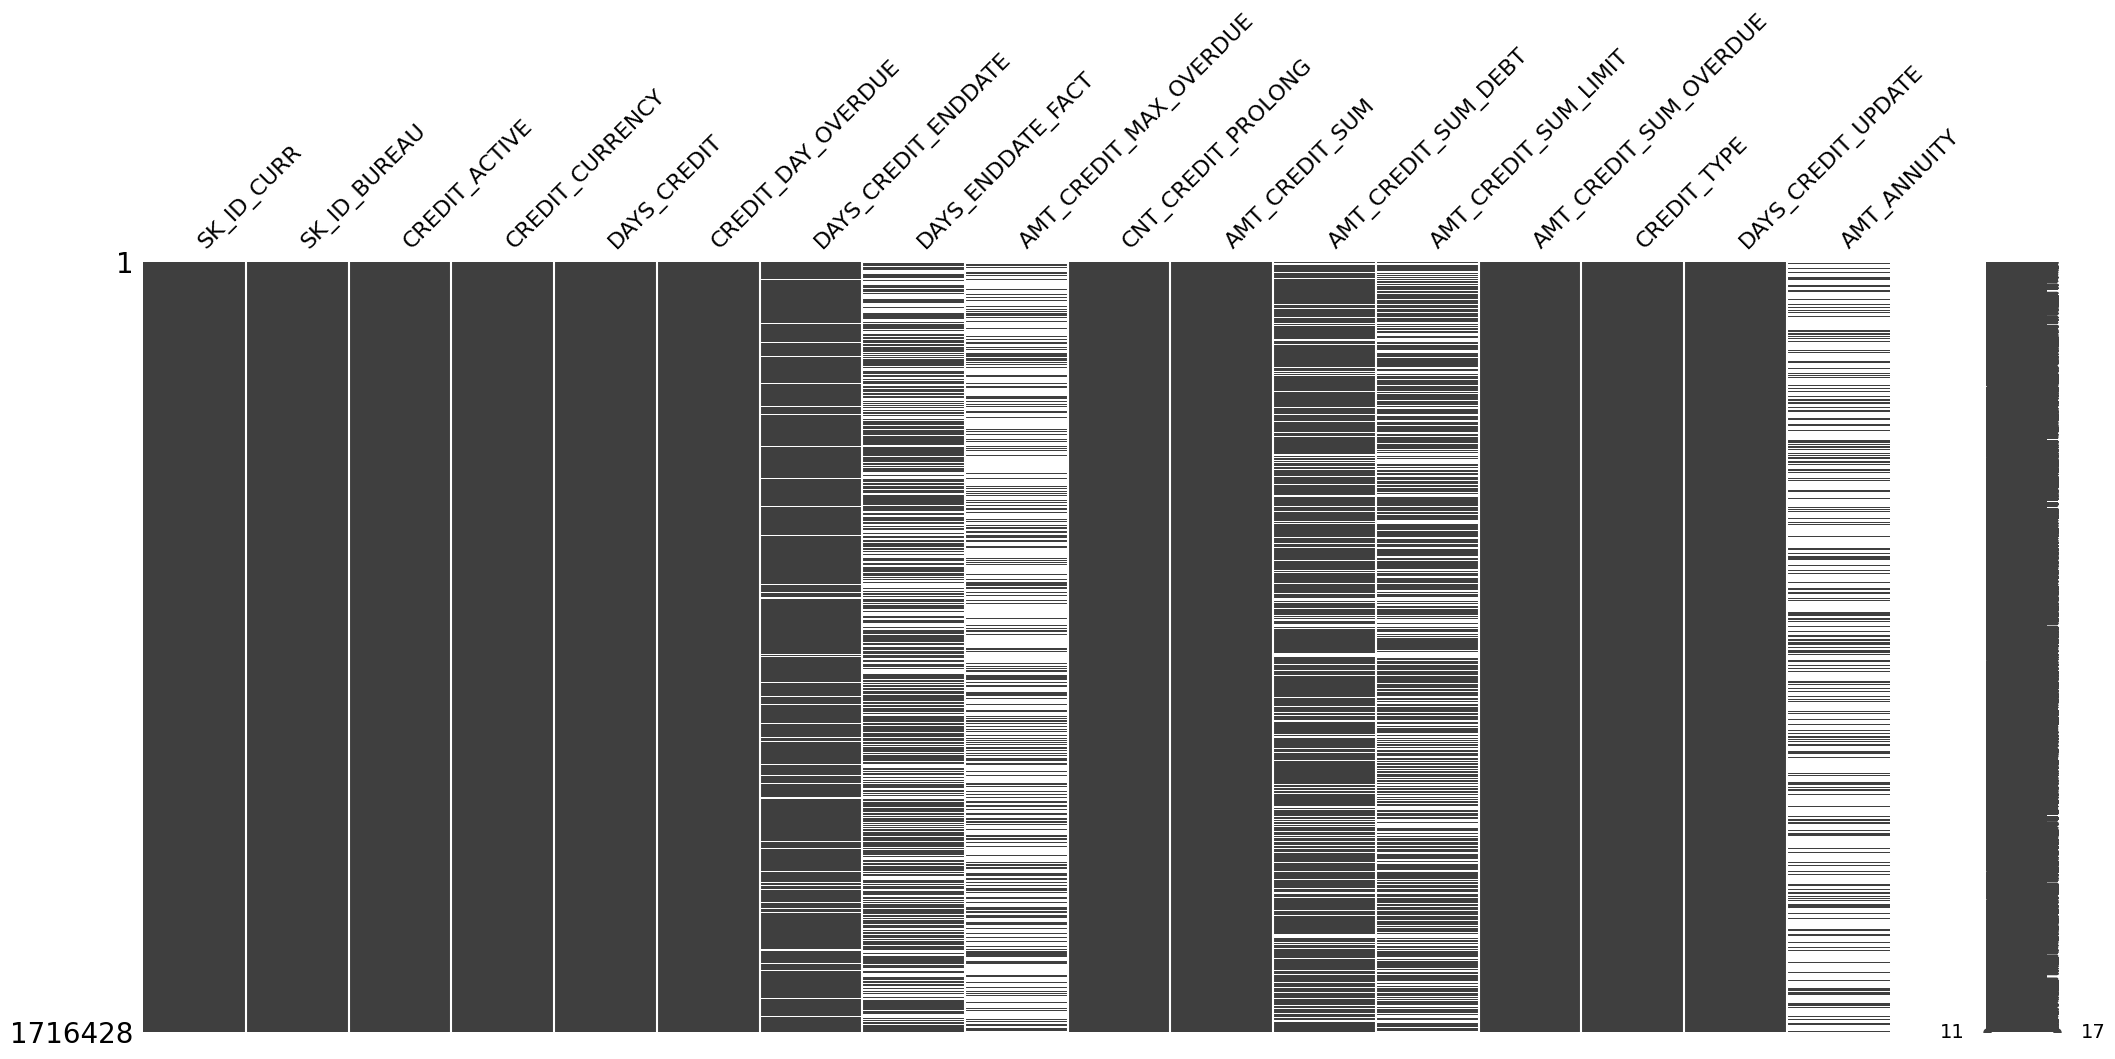

In [12]:
%matplotlib inline

msno.matrix(bureau);

In [13]:
bureau[bureau['DAYS_CREDIT_ENDDATE'].isnull()]['CREDIT_ACTIVE'].value_counts()

CREDIT_ACTIVE
Active      72496
Closed      32430
Sold          626
Bad debt        1
Name: count, dtype: int64

In [14]:
bureau[bureau['DAYS_ENDDATE_FACT'].isnull()]['CREDIT_ACTIVE'].value_counts()

CREDIT_ACTIVE
Active      628638
Sold          4879
Closed         125
Bad debt        11
Name: count, dtype: int64

Majority of the missing DAYS_CREDIT_ENDDATE values come from credits marked as "Active" — this is expected, because active credits don’t have an end date yet. A significant amount of them are from "Closed" credits — this is less expected and could be due to some data quality issues. 

Majority of missing values of DAYS_ENDDATE_FACT come from credits marked as "Active" and this is expected, as active credits don't have an end date. "Sold" credits to another institution could lack end date due to to data not being transferred or tracked after sale. "Closed" credits should have end date, this can indicate some data or recording errors.

A placeholder for missing values will be made. Missing values will be filled later on for modelling with placeholder value of 0.

In [15]:
bureau['CREDIT_ENDDATE_MISSING_FLAG'] = bureau['DAYS_CREDIT_ENDDATE'].isnull().astype(int)
bureau['ENDDATE_FACT_MISSING_FLAG'] = bureau['DAYS_ENDDATE_FACT'].isnull().astype(int)

In [16]:
mask = bureau['AMT_CREDIT_MAX_OVERDUE'].isnull()
bureau[mask]['CNT_CREDIT_PROLONG'].value_counts()

CNT_CREDIT_PROLONG
0    1124488
Name: count, dtype: int64

In [17]:
bureau['AMT_CREDIT_MAX_OVERDUE'].value_counts().head(3)

AMT_CREDIT_MAX_OVERDUE
0.0       470650
1440.0       688
225.0        405
Name: count, dtype: int64

AMT_CREDIT_MAX_OVERDUE likely records the maximum amount a client has ever been overdue on a given credit. Since the value is missing most likelly the client wasn't overdue on a credit. Therefore, the missing values will be filled with 0. Since AMT_CREDIT_MAX_OVERDUE also has separate value for 0, a flag marking original missing values will be made as well.

In [18]:
bureau['AMT_CREDIT_MAX_OVERDUE_MISSING_FLAG'] = bureau['AMT_CREDIT_MAX_OVERDUE'].isnull().astype(int)

Missing values in AMT_CREDIT_SUM will be filled with medium, since there is very little percentage missing, which is likelly due to some data errors. 

In [19]:
bureau[bureau['AMT_CREDIT_SUM_DEBT'].isnull()]['CREDIT_ACTIVE'].value_counts()

CREDIT_ACTIVE
Closed      180543
Active       73547
Sold          3573
Bad debt         6
Name: count, dtype: int64

In [20]:
bureau[bureau['AMT_CREDIT_SUM_DEBT'].isnull()]['AMT_CREDIT_SUM_OVERDUE'].value_counts(normalize=True).head(3)

AMT_CREDIT_SUM_OVERDUE
0.0    0.998129
4.5    0.000120
9.0    0.000058
Name: proportion, dtype: float64

In [21]:
bureau[bureau['AMT_CREDIT_SUM_LIMIT'].isnull()]['CREDIT_ACTIVE'].value_counts()

CREDIT_ACTIVE
Closed      413524
Active      173318
Sold          4929
Bad debt         9
Name: count, dtype: int64

In [22]:
bureau[bureau['AMT_CREDIT_SUM_LIMIT'].isnull()]['AMT_CREDIT_SUM_OVERDUE'].value_counts(normalize=True).head(3)

AMT_CREDIT_SUM_OVERDUE
0.0    0.997063
4.5    0.000301
9.0    0.000091
Name: proportion, dtype: float64

Missing values values in AMT_CREDIT_SUM_DEBT with closed credits most are most likelly paid off and it would be same to fill it with 0. Active  credits should normally have a debt amount, so missing values here may reflect poor reporting. For sold ones it could be due to the original lender stoping updating debt data. For bad debt it is likelly due to data errors. Also majority of missing data has 0 on AMT_CREDIT_SUM_OVERDUE.

In [24]:
bureau[bureau['AMT_ANNUITY'].isnull()]['CREDIT_TYPE'].value_counts(normalize=True).head(3)

CREDIT_TYPE
Consumer credit    0.728941
Credit card        0.238599
Car loan           0.015242
Name: proportion, dtype: float64

In [25]:
bureau['AMT_ANNUITY'].value_counts().head(3)

AMT_ANNUITY
0.0        256915
4500.0       5182
13500.0      3147
Name: count, dtype: int64

A high missing rate of 71.47% for AMT_ANNUITY suggests that this field is only populated for certain types of credits. 
What we can see that for certain credit types it is more common than others. Consumer credit can refer to various short-term or flexible loans that may not have clearly defined annuity structures, especially if they are revolving or promotional products. Credit cards inherently don’t have annuity payments, which explains their strong presence in the missing data. Car loans, more structured installment products, have much fewer missing annuity values, as expected. A flag will be added which captures if whether annuity info is relevant for a record.

In [26]:
bureau['HAS_ANNUITY_INFO'] = bureau['AMT_ANNUITY'].notnull().astype(int)

## Exploring Data

### Features

In [27]:
query = '''
SELECT * 
FROM HomeCredit_columns_description
WHERE "Table" = 'bureau.csv'
'''

bureau_info = db.sql(query).df()
bureau_info

,Table,Row,Description,Special
0,bureau.csv,SK_ID_CURR,ID of loan in our sample - one loan in our sam...,hashed
1,bureau.csv,SK_BUREAU_ID,Recoded ID of previous Credit Bureau credit re...,hashed
2,bureau.csv,CREDIT_ACTIVE,Status of the Credit Bureau (CB) reported credits,None
3,bureau.csv,CREDIT_CURRENCY,Recoded currency of the Credit Bureau credit,recoded
4,bureau.csv,DAYS_CREDIT,How many days before current application did c...,time only relative to the application
5,bureau.csv,CREDIT_DAY_OVERDUE,Number of days past due on CB credit at the ti...,None
6,bureau.csv,DAYS_CREDIT_ENDDATE,Remaining duration of CB credit (in days) at t...,time only relative to the application
7,bureau.csv,DAYS_ENDDATE_FACT,Days since CB credit ended at the time of appl...,time only relative to the application
8,bureau.csv,AMT_CREDIT_MAX_OVERDUE,Maximal amount overdue on the Credit Bureau cr...,None
9,bureau.csv,CNT_CREDIT_PROLONG,How many times was the Credit Bureau credit pr...,None


In [28]:
bureau.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1716428 entries, 0 to 1716427
Data columns (total 23 columns):
 #   Column                               Dtype  
---  ------                               -----  
 0   SK_ID_CURR                           int64  
 1   SK_ID_BUREAU                         int64  
 2   CREDIT_ACTIVE                        object 
 3   CREDIT_CURRENCY                      object 
 4   DAYS_CREDIT                          int64  
 5   CREDIT_DAY_OVERDUE                   int64  
 6   DAYS_CREDIT_ENDDATE                  float64
 7   DAYS_ENDDATE_FACT                    float64
 8   AMT_CREDIT_MAX_OVERDUE               float64
 9   CNT_CREDIT_PROLONG                   int64  
 10  AMT_CREDIT_SUM                       float64
 11  AMT_CREDIT_SUM_DEBT                  float64
 12  AMT_CREDIT_SUM_LIMIT                 float64
 13  AMT_CREDIT_SUM_OVERDUE               float64
 14  CREDIT_TYPE                          object 
 15  DAYS_CREDIT_UPDATE              

In [29]:
bureau.iloc[:, 2:].describe()

,DAYS_CREDIT,CREDIT_DAY_OVERDUE,DAYS_CREDIT_ENDDATE,DAYS_ENDDATE_FACT,AMT_CREDIT_MAX_OVERDUE,CNT_CREDIT_PROLONG,AMT_CREDIT_SUM,AMT_CREDIT_SUM_DEBT,AMT_CREDIT_SUM_LIMIT,AMT_CREDIT_SUM_OVERDUE,DAYS_CREDIT_UPDATE,AMT_ANNUITY,CREDIT_ENDDATE_MISSING_FLAG,ENDDATE_FACT_MISSING_FLAG,AMT_CREDIT_MAX_OVERDUE_MISSING_FLAG,MISSING_SUM_DEBT_FLAG,MISSING_CREDIT_LIMIT_FLAG,HAS_ANNUITY_INFO
count,1.716428e+06,1.716428e+06,1.610875e+06,1.082775e+06,5.919400e+05,1.716428e+06,1.716415e+06,1.458759e+06,1.124648e+06,1.716428e+06,1.716428e+06,4.896370e+05,1.716428e+06,1.716428e+06,1.716428e+06,1.716428e+06,1.716428e+06,1.716428e+06
mean,-1.142108e+03,8.181666e-01,5.105174e+02,-1.017437e+03,3.825418e+03,6.410406e-03,3.549946e+05,1.370851e+05,6.229515e+03,3.791276e+01,-5.937483e+02,1.571276e+04,6.149573e-02,3.691696e-01,6.551326e-01,1.501193e-01,3.447741e-01,2.852651e-01
std,7.951649e+02,3.654443e+01,4.994220e+03,7.140106e+02,2.060316e+05,9.622391e-02,1.149811e+06,6.774011e+05,4.503203e+04,5.937650e+03,7.207473e+02,3.258269e+05,2.402375e-01,4.825801e-01,4.753251e-01,3.571884e-01,4.752947e-01,4.515407e-01
min,-2.922000e+03,0.000000e+00,-4.206000e+04,-4.202300e+04,0.000000e+00,0.000000e+00,0.000000e+00,-4.705600e+06,-5.864061e+05,0.000000e+00,-4.194700e+04,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00
25%,-1.666000e+03,0.000000e+00,-1.138000e+03,-1.489000e+03,0.000000e+00,0.000000e+00,5.130000e+04,0.000000e+00,0.000000e+00,0.000000e+00,-9.080000e+02,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00
50%,-9.870000e+02,0.000000e+00,-3.300000e+02,-8.970000e+02,0.000000e+00,0.000000e+00,1.255185e+05,0.000000e+00,0.000000e+00,0.000000e+00,-3.950000e+02,0.000000e+00,0.000000e+00,0.000000e+00,1.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00
75%,-4.740000e+02,0.000000e+00,4.740000e+02,-4.250000e+02,0.000000e+00,0.000000e+00,3.150000e+05,4.015350e+04,0.000000e+00,0.000000e+00,-3.300000e+01,1.350000e+04,0.000000e+00,1.000000e+00,1.000000e+00,0.000000e+00,1.000000e+00,1.000000e+00
max,0.000000e+00,2.792000e+03,3.119900e+04,0.000000e+00,1.159872e+08,9.000000e+00,5.850000e+08,1.701000e+08,4.705600e+06,3.756681e+06,3.720000e+02,1.184534e+08,1.000000e+00,1.000000e+00,1.000000e+00,1.000000e+00,1.000000e+00,1.000000e+00


In [30]:
for i in bureau.columns:
    print(i, "column's total unique values are:", bureau[i].nunique())

SK_ID_CURR column's total unique values are: 305811
SK_ID_BUREAU column's total unique values are: 1716428
CREDIT_ACTIVE column's total unique values are: 4
CREDIT_CURRENCY column's total unique values are: 4
DAYS_CREDIT column's total unique values are: 2923
CREDIT_DAY_OVERDUE column's total unique values are: 942
DAYS_CREDIT_ENDDATE column's total unique values are: 14096
DAYS_ENDDATE_FACT column's total unique values are: 2917
AMT_CREDIT_MAX_OVERDUE column's total unique values are: 68251
CNT_CREDIT_PROLONG column's total unique values are: 10
AMT_CREDIT_SUM column's total unique values are: 236708
AMT_CREDIT_SUM_DEBT column's total unique values are: 226537
AMT_CREDIT_SUM_LIMIT column's total unique values are: 51726
AMT_CREDIT_SUM_OVERDUE column's total unique values are: 1616
CREDIT_TYPE column's total unique values are: 15
DAYS_CREDIT_UPDATE column's total unique values are: 2982
AMT_ANNUITY column's total unique values are: 40321
CREDIT_ENDDATE_MISSING_FLAG column's total uniqu

In [31]:
features_cat = bureau.select_dtypes(include=['object', 'bool']).columns

for i in features_cat:
    print(i, "column's unique values are:", bureau[i].unique())

CREDIT_ACTIVE column's unique values are: ['Closed' 'Active' 'Sold' 'Bad debt']
CREDIT_CURRENCY column's unique values are: ['currency 1' 'currency 2' 'currency 4' 'currency 3']
CREDIT_TYPE column's unique values are: ['Consumer credit' 'Credit card' 'Mortgage' 'Car loan' 'Microloan'
 'Loan for working capital replenishment' 'Loan for business development'
 'Real estate loan' 'Unknown type of loan' 'Another type of loan'
 'Cash loan (non-earmarked)' 'Loan for the purchase of equipment'
 'Mobile operator loan' 'Interbank credit'
 'Loan for purchase of shares (margin lending)']


### Charts

#### Categorical Values

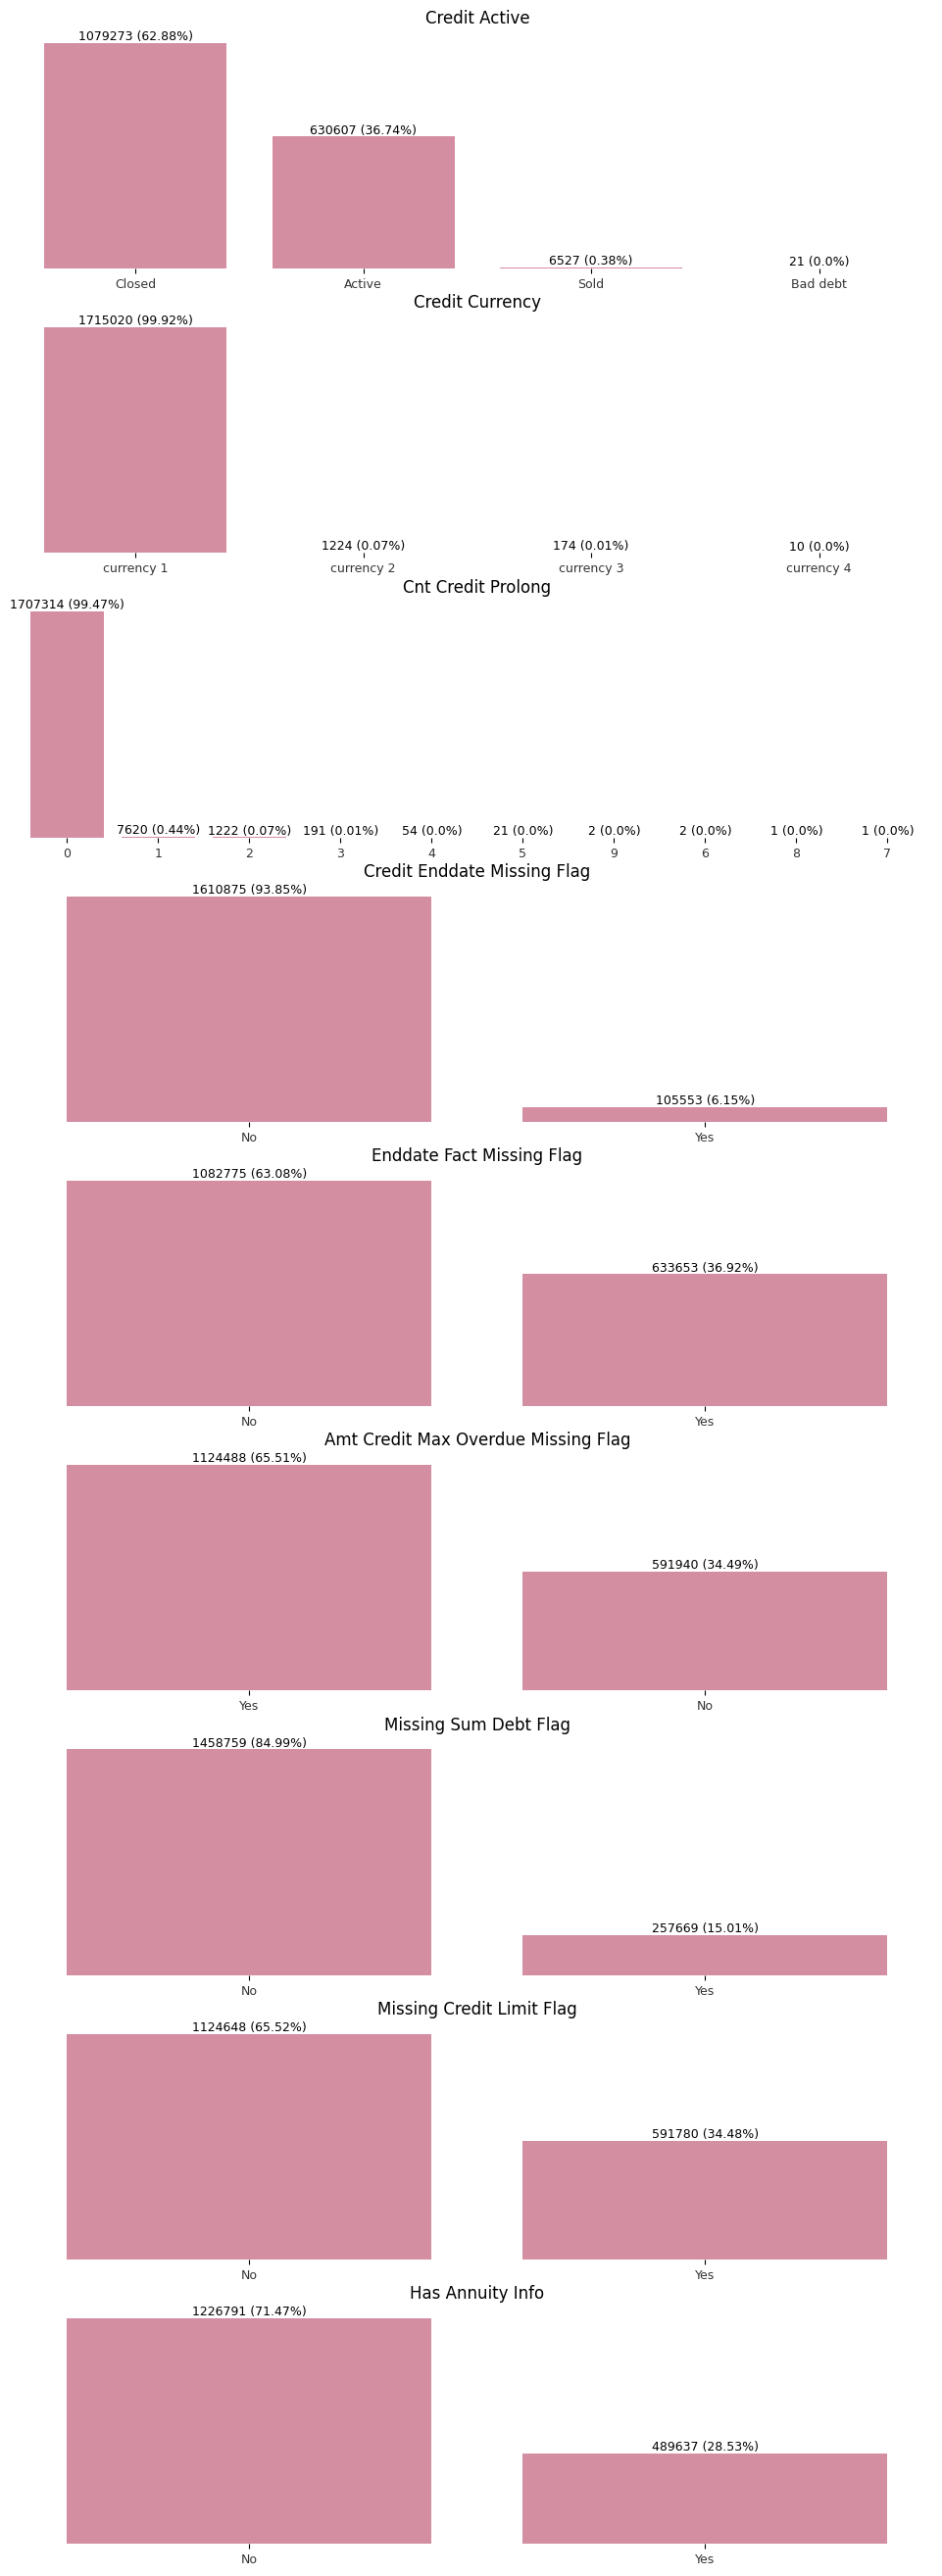

In [32]:
features_cat = bureau.select_dtypes(include=['object', 'int64', 'bool']).columns

cat_cols = []
for item in features_cat:
    nr_unique_values = bureau[item].nunique()
    if nr_unique_values < 11:
        cat_cols.append(item)

fig, axs = plt.subplots(len(cat_cols), 1, figsize=(12, (3.7 * len(cat_cols))))

i = 0
for item in cat_cols:
    temp = bureau[item].value_counts()
    title = item.replace("_", " ").title()
    ax1 = bar_plot_f_perc(temp, title, color='#e0829d', ax=axs[i])

    ind = temp.index
    if ind[0] == 0 and ind[1] == 1 and len(ind) == 2:
        ax1.set_xticklabels(['No', 'Yes'])
    if ind[0] == 1 and ind[1] == 0 and len(ind) == 2:
        ax1.set_xticklabels(['Yes', 'No'])

    i += 1

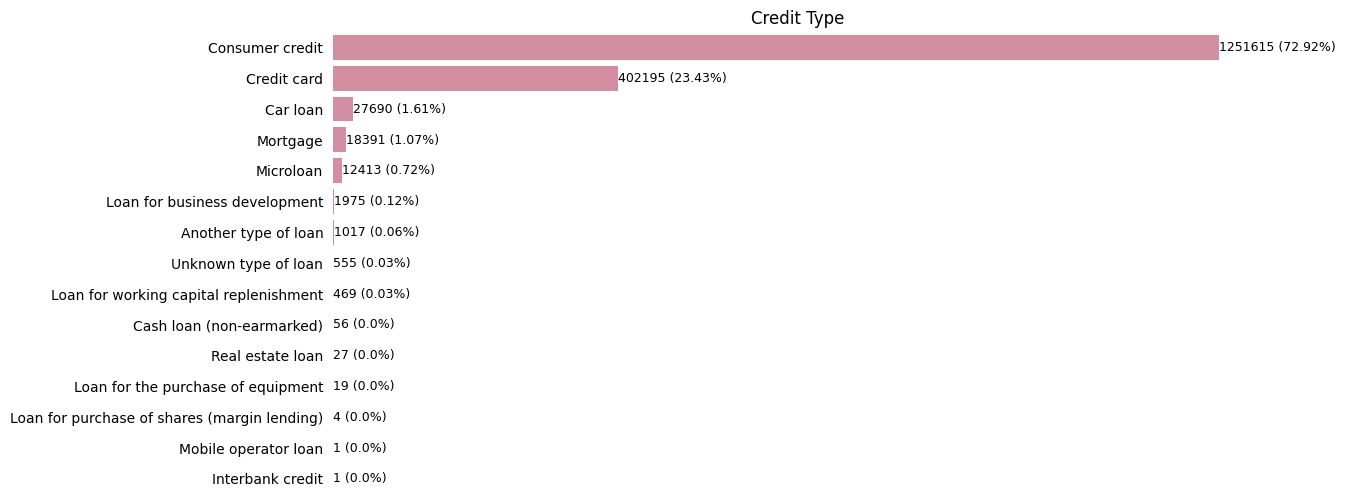

In [33]:
fig = plt.figure(figsize=(12, 6))

credit_t_counts = bureau['CREDIT_TYPE'].value_counts()

ax = bar_plot_f_perc_horizontal(credit_t_counts, 'Credit Type', color='#e0829d')

There are some of categories which are very rare and therefore not informative. There are very little other currencies than currency 1, 99.47% of CNT_CREDIT_PROLONG is 0, and majority of Credit types are either consumer credit or credit card. There are also some Car loans and Morgages with more numbers.

#### Collapsing Rare Categories and Adding Flags

In [34]:
def simplify_credit_type(x: str) -> str:
    """
    Helper function to simplify credit type into broader categories.
    Keeps 'Consumer credit', 'Credit card', 'Car loan', and 'Mortgage' as-is.

    Parameters: x (str): original credit type.
    Returns: str: Simplified credit type.
    """
    if x in ['Consumer credit', 'Credit card', 'Car loan', 'Mortgage']:
        return x
    else:
        return 'Other'


def simplify_credit_active(x: str) -> str:
    """
    Helper function to simplify credit active into broader categories.
    Keeps 'Closed' and 'Active' as-is.

    Parameters: x (str): original credit type.
    Returns: str: Simplified credit category.
    """
    if x in ['Closed', 'Active']:
        return x
    else:
        return 'Other'


bureau['CREDIT_TYPE_GROUPED'] = bureau['CREDIT_TYPE'].apply(simplify_credit_type)
bureau['CREDIT_ACTIVE_GROUPED'] = bureau['CREDIT_ACTIVE'].apply(simplify_credit_active)
bureau['CREDIT_CURRENCY_GROUPED'] = bureau['CREDIT_CURRENCY'].apply(
    lambda x: 'currency 1' if x == 'currency 1' else 'other currency'
)
bureau['WAS_CREDIT_PROLONGED'] = (bureau['CNT_CREDIT_PROLONG'] != 0).astype(int)

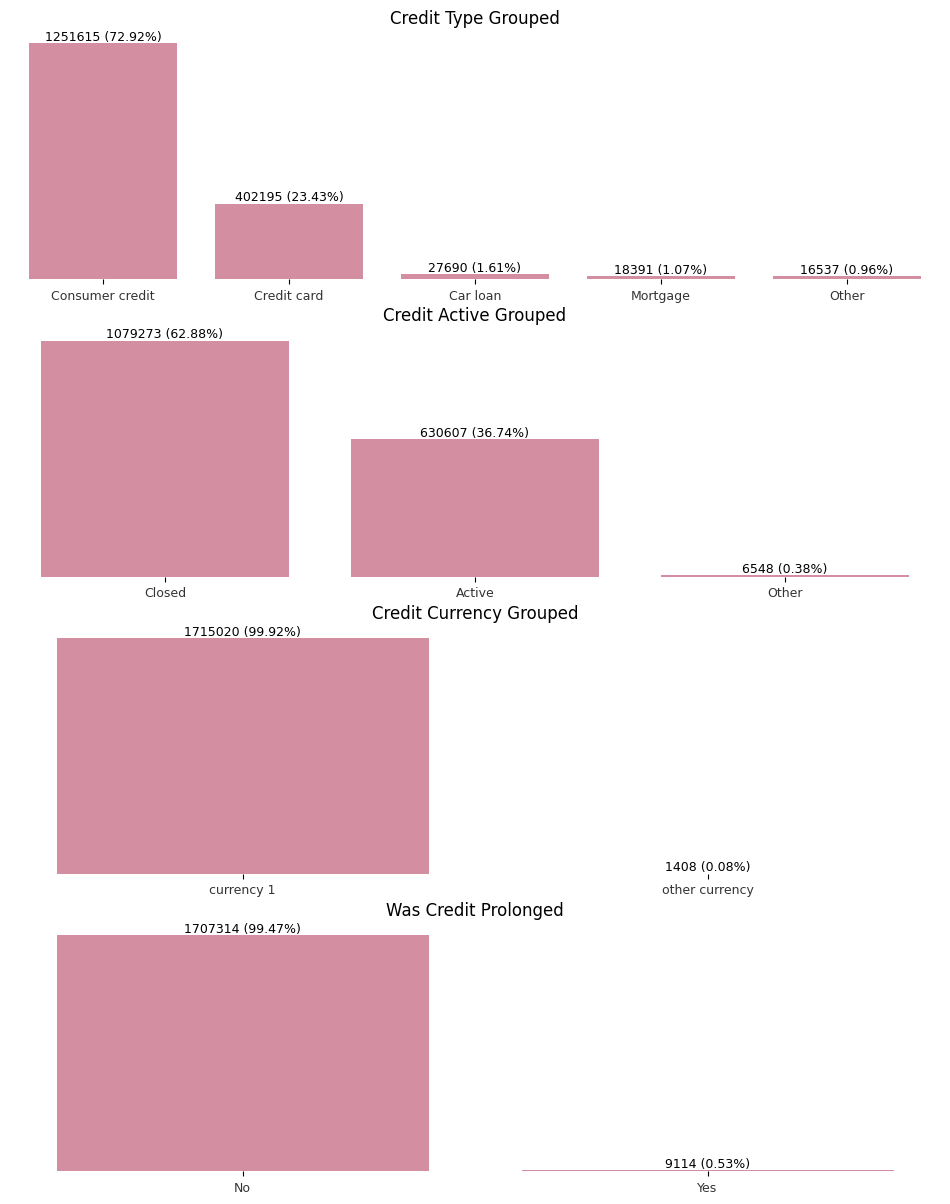

In [35]:
features = ['CREDIT_TYPE_GROUPED', 'CREDIT_ACTIVE_GROUPED', 'CREDIT_CURRENCY_GROUPED', 'WAS_CREDIT_PROLONGED']
fig, axs = plt.subplots(len(features), 1, figsize=(12, (3.7 * len(features))))

i = 0
for item in features:
    temp = bureau[item].value_counts()
    title = item.replace("_", " ").title()
    ax1 = bar_plot_f_perc(temp, title, color='#e0829d', ax=axs[i])

    ind = temp.index
    if ind[0] == 0 and ind[1] == 1 and len(ind) == 2:
        ax1.set_xticklabels(['No', 'Yes'])
    if ind[0] == 1 and ind[1] == 0 and len(ind) == 2:
        ax1.set_xticklabels(['Yes', 'No'])

    i += 1

Even after grouping, the dataset is rather imbalanced.

#### Numerical Values

In [36]:
num_feat_float = bureau.select_dtypes(include=['float']).columns
num_feat_float

Index(['DAYS_CREDIT_ENDDATE', 'DAYS_ENDDATE_FACT', 'AMT_CREDIT_MAX_OVERDUE',
       'AMT_CREDIT_SUM', 'AMT_CREDIT_SUM_DEBT', 'AMT_CREDIT_SUM_LIMIT',
       'AMT_CREDIT_SUM_OVERDUE', 'AMT_ANNUITY'],
      dtype='object')

In [37]:
ch = '#036264'
cmed = '#e0829d'
cmean = '#dac4d0'

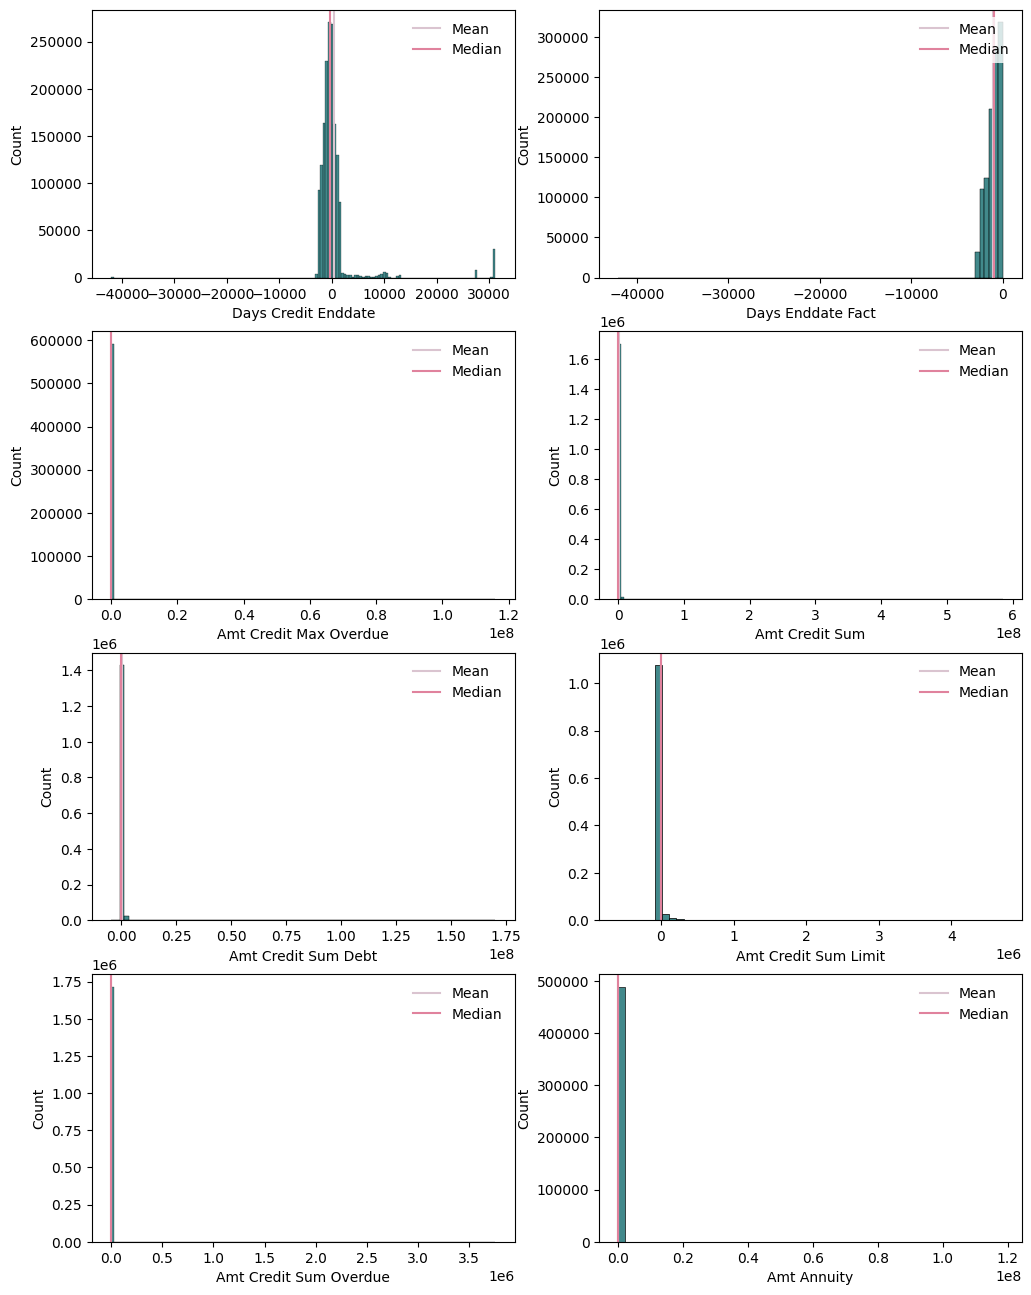

In [38]:
size = round(len(num_feat_float) / 2)

fig, axs = plt.subplots(size, 2, figsize=(12, size * 4))

i = 0
j = 0
for item in num_feat_float:
    if item in ['DAYS_CREDIT_ENDDATE', 'DAYS_ENDDATE_FACT']:
        binw = 500
    elif item in ['AMT_CREDIT_MAX_OVERDUE']:
        binw = 1000000
    elif item in ['AMT_CREDIT_SUM']:
        binw = 4000000
    elif item in ['AMT_ANNUITY', 'AMT_CREDIT_SUM_DEBT']:
        binw = 2000000
    elif item in ['AMT_CREDIT_SUM_LIMIT']:
        binw = 100000
    elif item in ['AMT_CREDIT_SUM_OVERDUE']:
        binw = 25000
    else:
        binw = None

    title = item.replace("_", " ").title()
    if j == 0:
        ax00 = histplot_f(
            bureau[item], color=ch, color_median=cmed, color_mean=cmean, xlabel=title, binwidth=binw, ax=axs[i, 0]
        )
        j += 1

    else:
        ax01 = histplot_f(
            bureau[item], color=ch, color_median=cmed, color_mean=cmean, xlabel=title, binwidth=binw, ax=axs[i, 1]
        )
        j = 0
        i += 1

Many features exhibit strong skewness, with a large concentration of values around zero and a long tail of extreme outliers. This distribution makes some charts less informative, as the bulk of the data is compressed within a narrow range.

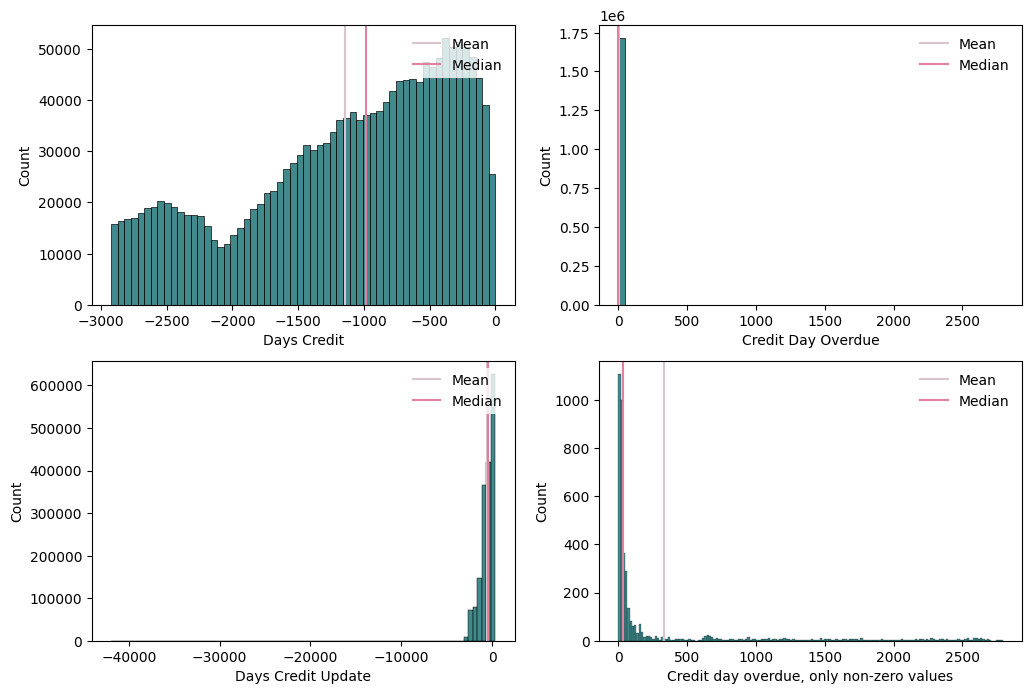

In [39]:
features_int = bureau.select_dtypes(include=['int']).columns

num_feat_int = []
for item in features_int[2:]:
    nr_unique_values = bureau[item].nunique()
    if nr_unique_values >= 11:
        num_feat_int.append(item)

size = round(len(num_feat_int) / 2)

fig, axs = plt.subplots(size, 2, figsize=(12, size * 4))

i = 0
j = 0
for item in num_feat_int:
    if item in ['DAYS_CREDIT', 'CREDIT_DAY_OVERDUE']:
        binw = 50
    elif item in ['DAYS_CREDIT_UPDATE']:
        binw = 500
    else:
        binw = None

    title = item.replace("_", " ").title()
    if j == 0:
        ax00 = histplot_f(
            bureau[item], color=ch, color_median=cmed, color_mean=cmean, xlabel=title, binwidth=binw, ax=axs[i, 0]
        )
        j += 1

    else:
        ax01 = histplot_f(
            bureau[item], color=ch, color_median=cmed, color_mean=cmean, xlabel=title, binwidth=binw, ax=axs[i, 1]
        )
        j = 0
        i += 1

query = '''
SELECT CREDIT_DAY_OVERDUE 
FROM bureau
WHERE CREDIT_DAY_OVERDUE != 0
'''
temp = db.sql(query).df()
ax11 = histplot_f(
    temp['CREDIT_DAY_OVERDUE'],
    color=ch,
    color_median=cmed,
    color_mean=cmean,
    xlabel='Credit day overdue, only non-zero values',
    ax=axs[1, 1],
);

Days credit has a maximum at around -450, is skewed to the left and has a smalled maximum at -2500, also there are cut offs at 0 and around -2800.
Days credit update is has maximum at 0, and is highly skewed to the left, with some extreme values.
Majority of Credit day overdue values at at 0. When 0 values are removed, we can see that maximum is slightly higher than 0 and distribution is skewed to the right.

#### Closer Look

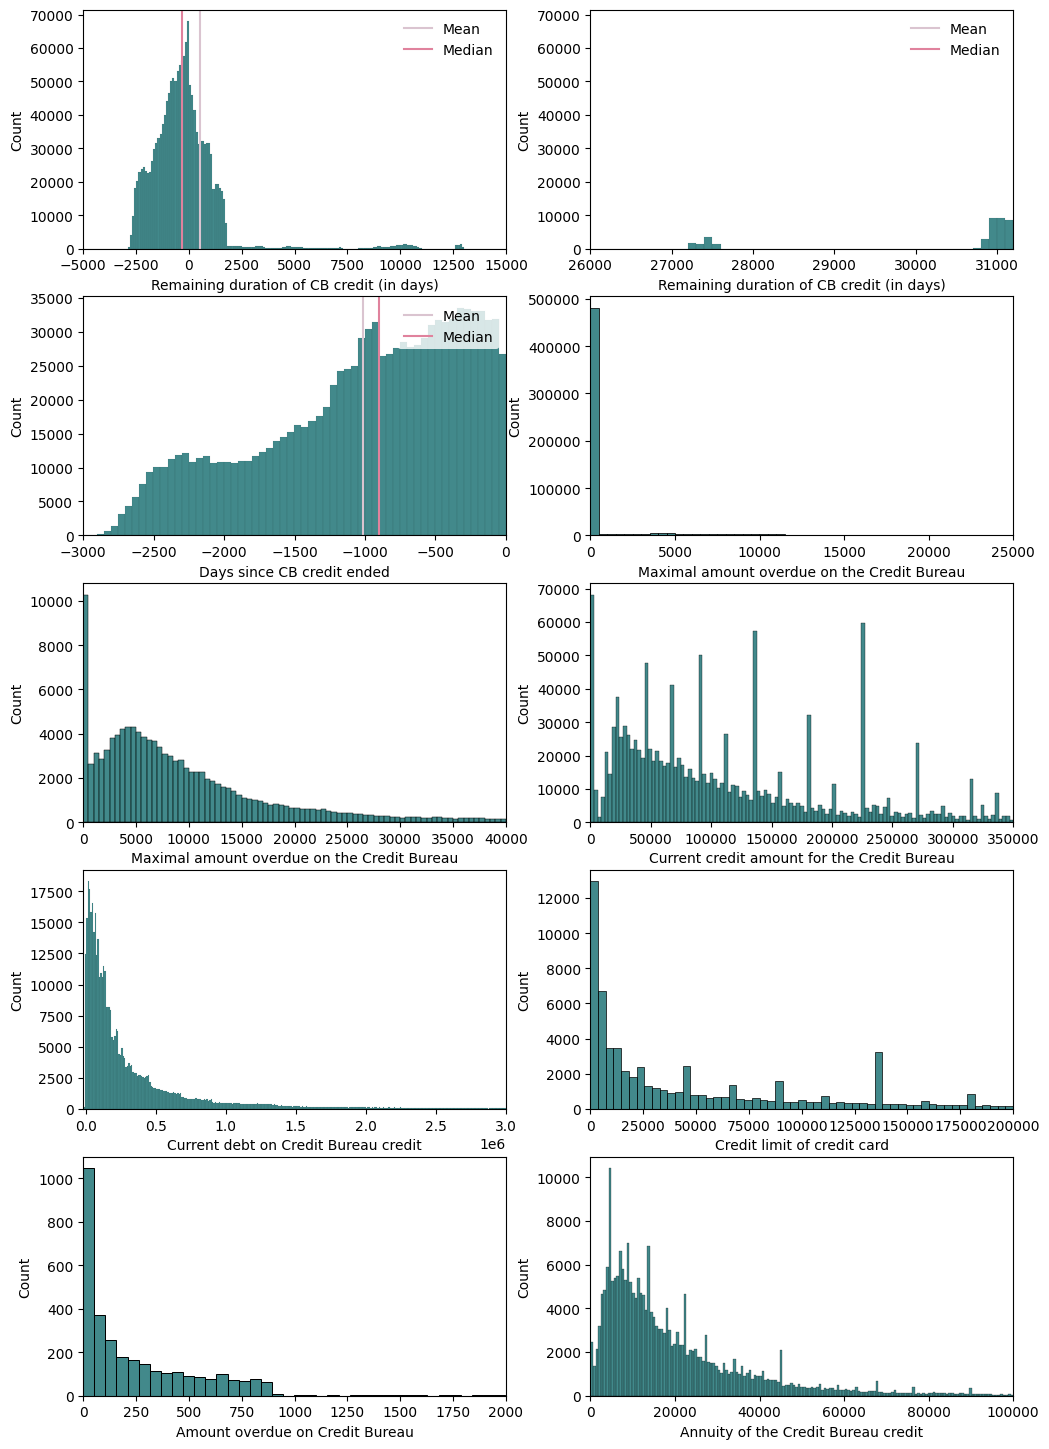

In [40]:
fig, axs = plt.subplots(5, 2, figsize=(12, 18))

ax00 = histplot_f(bureau.DAYS_CREDIT_ENDDATE, color=ch, color_median=cmed, color_mean=cmean, binwidth=100, ax=axs[0, 0])
ax00.set(xlabel='Remaining duration of CB credit (in days)', xlim=(-5000, 15000))

ax01 = histplot_f(bureau.DAYS_CREDIT_ENDDATE, color=ch, color_median=cmed, color_mean=cmean, binwidth=100, ax=axs[0, 1])
higher_lim = bureau.DAYS_CREDIT_ENDDATE.max()
ax01.set(xlabel='Remaining duration of CB credit (in days)', xlim=(26000, higher_lim))

ax10 = histplot_f(bureau.DAYS_ENDDATE_FACT, color=ch, color_median=cmed, color_mean=cmean, binwidth=50, ax=axs[1, 0])
higher_lim = bureau.DAYS_ENDDATE_FACT.max()
ax10.set(xlabel='Days since CB credit ended', xlim=(-3000, higher_lim))

query = '''
SELECT AMT_CREDIT_MAX_OVERDUE 
FROM bureau
WHERE AMT_CREDIT_MAX_OVERDUE < 25000
'''
temp = db.sql(query).df()
ax11 = histplot_f(temp.AMT_CREDIT_MAX_OVERDUE, color=ch, mean_meadian=False, binwidth=500, ax=axs[1, 1])
ax11.set(xlabel='Maximal amount overdue on the Credit Bureau', xlim=(0, 25000))

query = '''
SELECT AMT_CREDIT_MAX_OVERDUE 
FROM bureau
WHERE AMT_CREDIT_MAX_OVERDUE > 0 AND AMT_CREDIT_MAX_OVERDUE < 40000 
'''
temp = db.sql(query).df()
ax20 = histplot_f(temp.AMT_CREDIT_MAX_OVERDUE, color=ch, mean_meadian=False, binwidth=500, ax=axs[2, 0])
ax20.set(xlabel='Maximal amount overdue on the Credit Bureau', xlim=(0, 40000))

query = '''
SELECT AMT_CREDIT_SUM 
FROM bureau
WHERE AMT_CREDIT_SUM < 350000
'''
temp = db.sql(query).df()
ax21 = histplot_f(temp.AMT_CREDIT_SUM, color=ch, mean_meadian=False, binwidth=3000, ax=axs[2, 1])
ax21.set(xlabel='Current credit amount for the Credit Bureau', xlim=(0, 350000))

query = '''
SELECT AMT_CREDIT_SUM_DEBT 
FROM bureau
WHERE AMT_CREDIT_SUM_DEBT != 0 AND AMT_CREDIT_SUM_DEBT < 3000000
'''
temp = db.sql(query).df()
ax30 = histplot_f(temp.AMT_CREDIT_SUM_DEBT, color=ch, mean_meadian=False, binwidth=10000, ax=axs[3, 0])
ax30.set(xlabel='Current debt on Credit Bureau credit', xlim=(-20000, 3000000))

query = '''
SELECT AMT_CREDIT_SUM_LIMIT 
FROM bureau
WHERE AMT_CREDIT_SUM_LIMIT > 0 AND AMT_CREDIT_SUM_LIMIT < 200000
'''
temp = db.sql(query).df()
ax31 = histplot_f(temp.AMT_CREDIT_SUM_LIMIT, color=ch, mean_meadian=False, ax=axs[3, 1])
ax31.set(xlabel='Credit limit of credit card', xlim=(0, 200000))

query = '''
SELECT AMT_CREDIT_SUM_OVERDUE 
FROM bureau
WHERE AMT_CREDIT_SUM_OVERDUE >0 AND AMT_CREDIT_SUM_OVERDUE < 2000
'''
temp = db.sql(query).df()
ax40 = histplot_f(temp.AMT_CREDIT_SUM_OVERDUE, color=ch, mean_meadian=False, ax=axs[4, 0])
ax40.set(xlabel='Amount overdue on Credit Bureau', xlim=(0, 2000))

query = '''
SELECT AMT_ANNUITY 
FROM bureau
WHERE AMT_ANNUITY > 0 AND AMT_ANNUITY < 100000
'''
temp = db.sql(query).df()
ax41 = histplot_f(temp.AMT_ANNUITY, color=ch, mean_meadian=False, ax=axs[4, 1])
ax41.set(xlabel='Annuity of the Credit Bureau credit', xlim=(0, 100000));

Some clusters at the end of DAYS_CREDIT_ENDDATE (Remaining duration of CB credit) might be due to fixed terms like 12, 24, 36, 60 months, etc., leading to visible clusters.
Distributions are mostly skewed to the right.

#### Investigating Odd Values

In [41]:
mask = bureau['AMT_CREDIT_SUM_DEBT'] < 0
print(f'There are {mask.sum()} negative values of credit sum debt.')
neg_debt = bureau[mask]
pd.crosstab(neg_debt['CREDIT_TYPE'], neg_debt['CREDIT_ACTIVE'], normalize='index')

There are 8418 negative values of credit sum debt.


CREDIT_ACTIVE,Active,Closed
CREDIT_TYPE,,
Credit card,0.73913,0.26087


These values are only linked to credit cards and most likelly intentional. Credit cards can have negative balances, that's why they are left.

#### Feature Engineering

In [42]:
bureau['CREDIT_LENGTH'] = bureau['DAYS_ENDDATE_FACT'] - bureau['DAYS_CREDIT']
bureau['DEBT_CREDIT_RATIO'] = bureau.apply(
    lambda row: row['AMT_CREDIT_SUM_DEBT'] / row['AMT_CREDIT_SUM'] if row['AMT_CREDIT_SUM'] != 0 else np.nan, axis=1
)
bureau['OVERDUE_TO_DEBT_RATIO'] = bureau.apply(
    lambda row: (
        row['AMT_CREDIT_SUM_OVERDUE'] / row['AMT_CREDIT_SUM_DEBT'] if row['AMT_CREDIT_SUM_DEBT'] != 0 else np.nan
    ),
    axis=1,
)
bureau['HAS_OVERDUE'] = (bureau['AMT_CREDIT_SUM_OVERDUE'] > 0).astype(int)
bureau['CREDIT_ACTIVE_FLAG'] = bureau['CREDIT_ACTIVE'].isin(['Active']).astype(int)

In [43]:
bureau['OVERDUE_WITH_NO_DEBT_FLAG'] = (
    (bureau['AMT_CREDIT_SUM_DEBT'] == 0) & (bureau['AMT_CREDIT_SUM_OVERDUE'] > 0)
).astype(int)
bureau['OVERDUE_WITH_NO_DEBT_FLAG'].value_counts()

OVERDUE_WITH_NO_DEBT_FLAG
0    1715688
1        740
Name: count, dtype: int64

In [44]:
print(bureau.CREDIT_LENGTH.min())
mask = bureau['CREDIT_LENGTH'] < 0
bureau.loc[mask, 'CREDIT_LENGTH'] = np.nan
print(bureau.CREDIT_LENGTH.min())

-39683.0
0.0


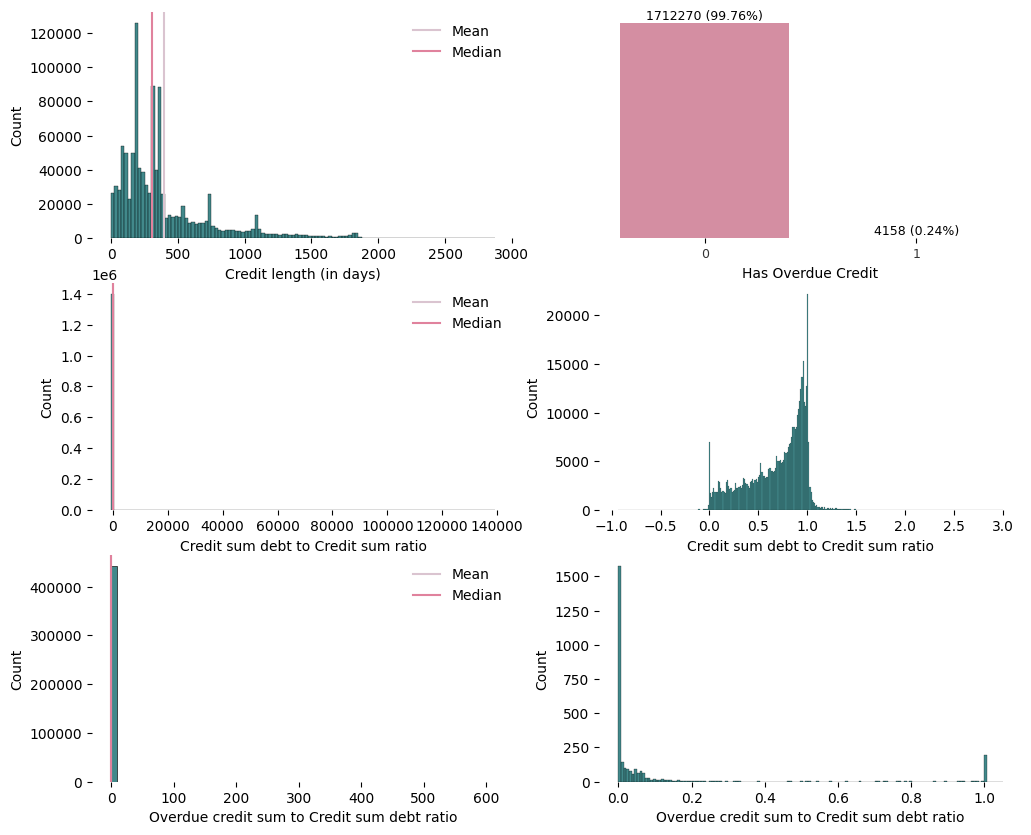

In [45]:
fig, axs = plt.subplots(3, 2, figsize=(12, 10))

ax00 = histplot_f(
    bureau.CREDIT_LENGTH,
    color=ch,
    color_median=cmed,
    color_mean=cmean,
    binwidth=25,
    xlabel='Credit length (in days)',
    ax=axs[0, 0],
)

temp = bureau.HAS_OVERDUE.value_counts()
ax01 = bar_plot_f_perc(temp, '', color='#e0829d', ax=axs[0, 1])
ax01.set(xlabel='Has Overdue Credit')

ax10 = histplot_f(
    bureau.DEBT_CREDIT_RATIO,
    color=ch,
    color_median=cmed,
    color_mean=cmean,
    xlabel='Credit sum debt to Credit sum ratio',
    binwidth=1000,
    ax=axs[1, 0],
)

query = '''
SELECT DEBT_CREDIT_RATIO 
FROM bureau
WHERE DEBT_CREDIT_RATIO != 0 AND DEBT_CREDIT_RATIO < 3 AND DEBT_CREDIT_RATIO > -1
'''
temp = db.sql(query).df()
ax11 = histplot_f(
    temp.DEBT_CREDIT_RATIO, color=ch, mean_meadian=False, xlabel='Credit sum debt to Credit sum ratio', ax=axs[1, 1]
)

ax20 = histplot_f(
    bureau.OVERDUE_TO_DEBT_RATIO,
    color=ch,
    color_median=cmed,
    color_mean=cmean,
    xlabel='Overdue credit sum to Credit sum debt ratio',
    binwidth=10,
    ax=axs[2, 0],
)

query = '''
SELECT OVERDUE_TO_DEBT_RATIO 
FROM bureau
WHERE OVERDUE_TO_DEBT_RATIO != 0 AND OVERDUE_TO_DEBT_RATIO < 1.1
'''
temp = db.sql(query).df()
ax21 = histplot_f(
    temp.OVERDUE_TO_DEBT_RATIO,
    color=ch,
    xlabel='Overdue credit sum to Credit sum debt ratio',
    mean_meadian=False,
    ax=axs[2, 1],
);

Credit length is skewed to the right. Only minority of clients has overdue credit. Majority of ratios are at 0. 

# Bureau Balance

## Checking for Nulls and Duplicates

In [47]:
bureau_balance.columns.duplicated().any()

np.False_

In [48]:
bureau_balance.duplicated().any()

np.False_

In [49]:
bureau_balance.isnull().any()

SK_ID_BUREAU      False
MONTHS_BALANCE    False
STATUS            False
dtype: bool

## Exploring Data

In [50]:
query = '''
SELECT * 
FROM HomeCredit_columns_description
WHERE "Table" = 'bureau_balance.csv'
'''

bureau_balance_info = db.sql(query).df()
bureau_balance_info

,Table,Row,Description,Special
0,bureau_balance.csv,SK_BUREAU_ID,Recoded ID of Credit Bureau credit (unique cod...,hashed
1,bureau_balance.csv,MONTHS_BALANCE,Month of balance relative to application date ...,time only relative to the application
2,bureau_balance.csv,STATUS,Status of Credit Bureau loan during the month ...,None


In [51]:
bureau_balance.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 27299925 entries, 0 to 27299924
Data columns (total 3 columns):
 #   Column          Dtype 
---  ------          ----- 
 0   SK_ID_BUREAU    int64 
 1   MONTHS_BALANCE  int64 
 2   STATUS          object
dtypes: int64(2), object(1)
memory usage: 624.8+ MB


In [52]:
bureau_balance.MONTHS_BALANCE.describe()

count    2.729992e+07
mean    -3.074169e+01
std      2.386451e+01
min     -9.600000e+01
25%     -4.600000e+01
50%     -2.500000e+01
75%     -1.100000e+01
max      0.000000e+00
Name: MONTHS_BALANCE, dtype: float64

In [53]:
for i in bureau_balance.columns:
    print(i, "column's total unique values are:", bureau_balance[i].nunique())

SK_ID_BUREAU column's total unique values are: 817395
MONTHS_BALANCE column's total unique values are: 97
STATUS column's total unique values are: 8


In [54]:
bureau_balance.STATUS.unique()

array(['C', '0', 'X', '1', '2', '3', '5', '4'], dtype=object)

Status of Credit Bureau loan during the month (active, closed, DPD0-30,� [C means closed, X means status unknown, 0 means no DPD, 1 means maximal did during month between 1-30, 2 means DPD 31-60,� 5 means DPD 120+ or sold or written off ] ) DPD stands for Days Past Due.

DPD0-30 indicates that the payment was delayed, but only within the range of 0 to 30 days.
0	No DPD — payment on time
1, 2, ...	Number of months past due (1 = 30+ days)
C	Closed credit
X	No data available for that month
DPD0-30	Custom code meaning slight delinquency

## Drawing Charts

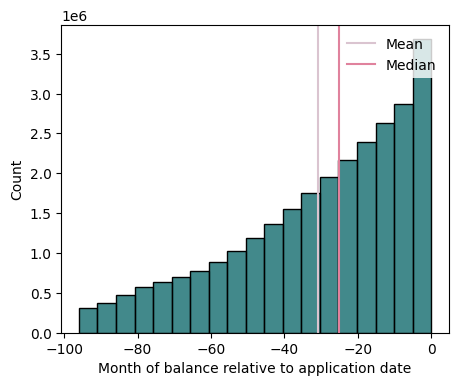

In [55]:
fig = plt.figure(figsize=(5, 4))

ax = histplot_f(
    bureau_balance.MONTHS_BALANCE,
    color=ch,
    color_median=cmed,
    xlabel='Month of balance relative to application date',
    color_mean=cmean,
    binwidth=5,
);

The distribution is skewed to the left. Closer to 0 means fresher date.

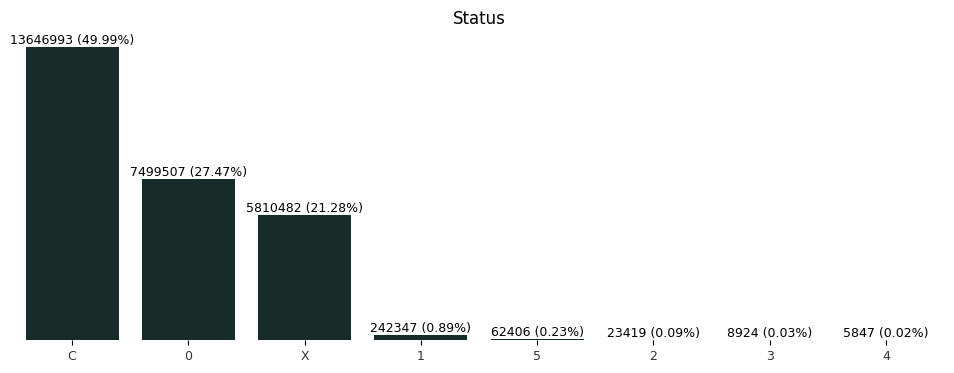

In [56]:
fig = plt.figure(figsize=(12, 4))

temp = bureau_balance.STATUS.value_counts()
ax1 = bar_plot_f_perc(temp, 'Status', color='#11302a')

Majority of credit bureau loan statuses are closed. X are unknown. Statuses with numbers stand for active. 0 means no DPD (days past due), 1 stands for 1 to 30, 2 stands for 31 - 60 and so on. Majority of active loans do not have DPD.

## Agregate

The dataset will be agregated according to the SK_ID_BUREAU.

In [57]:
query = """
    SELECT 
        SK_ID_BUREAU,
        AVG(MONTHS_BALANCE) MONTHS_BALANCE,
        CASE 
            WHEN COUNT_IF(STATUS IN ('0','1','2','3','4','5')) > 0 
                THEN MAX(CASE WHEN STATUS IN ('0','1','2','3','4','5') 
                THEN STATUS ELSE NULL END)
            WHEN COUNT_IF(STATUS = 'C') > 0 
                THEN 'C'
            ELSE 'X'
        END AS STATUS
    FROM bureau_balance
    GROUP BY SK_ID_BUREAU;   
"""

bb_agg = db.sql(query).df()
bb_agg.columns

Index(['SK_ID_BUREAU', 'MONTHS_BALANCE', 'STATUS'], dtype='object')

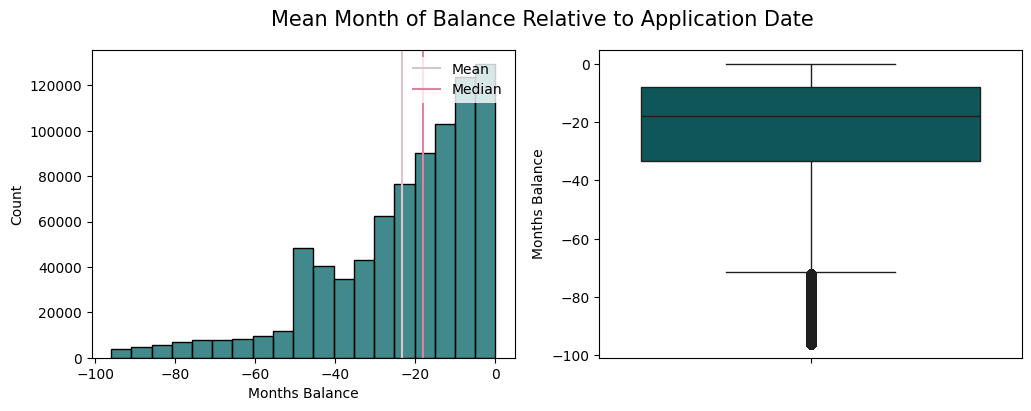

In [58]:
fig, axs = plt.subplots(1, 2, figsize=(12, 4))

fig.suptitle("Mean Month of Balance Relative to Application Date", fontsize=15)

ax0 = histplot_f(
    bb_agg.MONTHS_BALANCE, color=ch, color_median=cmed, color_mean=cmean, xlabel='Months Balance', binwidth=5, ax=axs[0]
)

ax1 = sns.boxplot(bb_agg.MONTHS_BALANCE, color=ch, ax=axs[1])
ax1.set_ylabel('Months Balance');

The distribution of average moths balance is skewed to the left. Closer to 0 means fresher date.

In [59]:
outlier_f(bb_agg.MONTHS_BALANCE).count()

np.int64(27137)

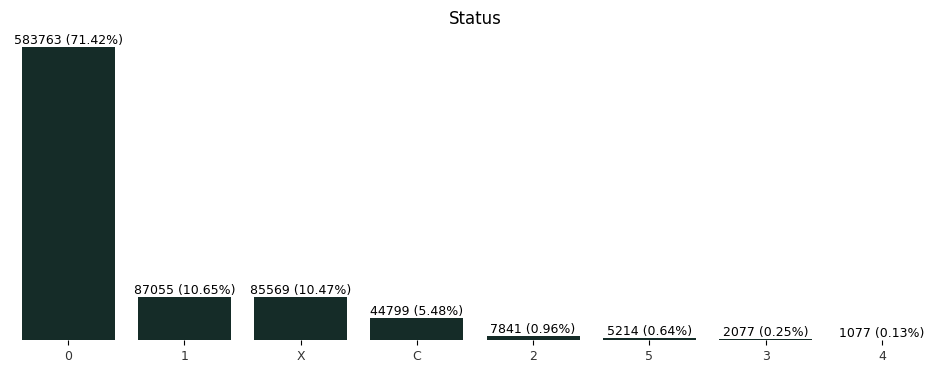

In [60]:
fig = plt.figure(figsize=(12, 4))

temp = bb_agg.STATUS.value_counts()
ax1 = bar_plot_f_perc(temp, 'Status', color='#11302a')

Majority of clients in bureau balance have active loans.

# Connecting Bureau and Bureau Balance

In [61]:
len(bb_agg.SK_ID_BUREAU.unique())

817395

In [62]:
len(bureau.SK_ID_BUREAU.unique())

1716428

In [63]:
query = '''
SELECT *
FROM bureau b
LEFT JOIN bb_agg bb
ON b.SK_ID_BUREAU = bb.SK_ID_BUREAU
'''

bureau_all = db.sql(query).df().drop(['SK_ID_BUREAU_1'], axis=1)
bureau_all.head()

,SK_ID_CURR,SK_ID_BUREAU,CREDIT_ACTIVE,CREDIT_CURRENCY,DAYS_CREDIT,CREDIT_DAY_OVERDUE,DAYS_CREDIT_ENDDATE,DAYS_ENDDATE_FACT,AMT_CREDIT_MAX_OVERDUE,CNT_CREDIT_PROLONG,...,CREDIT_CURRENCY_GROUPED,WAS_CREDIT_PROLONGED,CREDIT_LENGTH,DEBT_CREDIT_RATIO,OVERDUE_TO_DEBT_RATIO,HAS_OVERDUE,CREDIT_ACTIVE_FLAG,OVERDUE_WITH_NO_DEBT_FLAG,MONTHS_BALANCE,STATUS
0,380361,5715449,Active,currency 1,-357,0,1119.0,NaN,NaN,0,...,currency 1,0,NaN,0.0,NaN,0,1,0,-5.5,0
1,380361,5715451,Closed,currency 1,-917,0,-187.0,-759.0,NaN,0,...,currency 1,0,158.0,0.0,NaN,0,0,0,-17.5,0
2,380361,5715452,Closed,currency 1,-993,0,31039.0,-831.0,NaN,0,...,currency 1,0,162.0,0.0,NaN,0,0,0,-16.0,0
3,380361,5715453,Closed,currency 1,-1146,0,681.0,-780.0,NaN,0,...,currency 1,0,366.0,0.0,NaN,0,0,0,-18.5,0
4,380361,5715454,Closed,currency 1,-1622,0,-1074.0,-1073.0,NaN,0,...,currency 1,0,549.0,0.0,NaN,0,0,0,-34.0,0


In [64]:
bureau_all.describe()

,SK_ID_CURR,SK_ID_BUREAU,DAYS_CREDIT,CREDIT_DAY_OVERDUE,DAYS_CREDIT_ENDDATE,DAYS_ENDDATE_FACT,AMT_CREDIT_MAX_OVERDUE,CNT_CREDIT_PROLONG,AMT_CREDIT_SUM,AMT_CREDIT_SUM_DEBT,...,MISSING_CREDIT_LIMIT_FLAG,HAS_ANNUITY_INFO,WAS_CREDIT_PROLONGED,CREDIT_LENGTH,DEBT_CREDIT_RATIO,OVERDUE_TO_DEBT_RATIO,HAS_OVERDUE,CREDIT_ACTIVE_FLAG,OVERDUE_WITH_NO_DEBT_FLAG,MONTHS_BALANCE
count,1.716428e+06,1.716428e+06,1.716428e+06,1.716428e+06,1.610875e+06,1.082775e+06,5.919400e+05,1.716428e+06,1.716415e+06,1.458759e+06,...,1.716428e+06,1.716428e+06,1.716428e+06,1.082755e+06,1.396948e+06,442325.000000,1.716428e+06,1.716428e+06,1.716428e+06,774354.000000
mean,2.782149e+05,5.924434e+06,-1.142108e+03,8.181666e-01,5.105174e+02,-1.017437e+03,3.825418e+03,6.410406e-03,3.549946e+05,1.370851e+05,...,3.447741e-01,2.852651e-01,5.309864e-03,3.995370e+02,6.866229e-01,0.003940,2.422473e-03,3.673950e-01,4.311279e-04,-21.175822
std,1.029386e+05,5.322657e+05,7.951649e+02,3.654443e+01,4.994220e+03,7.140106e+02,2.060316e+05,9.622391e-02,1.149811e+06,6.774011e+05,...,4.752947e-01,4.515407e-01,7.267512e-02,3.700302e+02,1.728535e+02,0.982971,4.915898e-02,4.820955e-01,2.075915e-02,17.304289
min,1.000010e+05,5.000000e+06,-2.922000e+03,0.000000e+00,-4.206000e+04,-4.202300e+04,0.000000e+00,0.000000e+00,0.000000e+00,-4.705600e+06,...,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,-6.214942e+02,0.000000,0.000000e+00,0.000000e+00,0.000000e+00,-95.000000
25%,1.888668e+05,5.463954e+06,-1.666000e+03,0.000000e+00,-1.138000e+03,-1.489000e+03,0.000000e+00,0.000000e+00,5.130000e+04,0.000000e+00,...,0.000000e+00,0.000000e+00,0.000000e+00,1.800000e+02,0.000000e+00,0.000000,0.000000e+00,0.000000e+00,0.000000e+00,-30.000000
50%,2.780550e+05,5.926304e+06,-9.870000e+02,0.000000e+00,-3.300000e+02,-8.970000e+02,0.000000e+00,0.000000e+00,1.255185e+05,0.000000e+00,...,0.000000e+00,0.000000e+00,0.000000e+00,3.040000e+02,0.000000e+00,0.000000,0.000000e+00,0.000000e+00,0.000000e+00,-17.000000
75%,3.674260e+05,6.385681e+06,-4.740000e+02,0.000000e+00,4.740000e+02,-4.250000e+02,0.000000e+00,0.000000e+00,3.150000e+05,4.015350e+04,...,1.000000e+00,1.000000e+00,0.000000e+00,4.870000e+02,4.103880e-01,0.000000,0.000000e+00,1.000000e+00,0.000000e+00,-8.000000
max,4.562550e+05,6.843457e+06,0.000000e+00,2.792000e+03,3.119900e+04,0.000000e+00,1.159872e+08,9.000000e+00,5.850000e+08,1.701000e+08,...,1.000000e+00,1.000000e+00,1.000000e+00,2.877000e+03,1.393960e+05,615.000000,1.000000e+00,1.000000e+00,1.000000e+00,0.000000


In [65]:
result = bureau_all.isnull().sum()
rows_nr = bureau_all.shape[0]
for item in bureau_all.columns:
    missing_nr = result[item]
    if missing_nr > 0:
        missing_perc = count_percentage(missing_nr, rows_nr, round_value=4)
        print(f'The percentage of missing {item} values is {missing_perc}%.')

The percentage of missing DAYS_CREDIT_ENDDATE values is 6.1496%.
The percentage of missing DAYS_ENDDATE_FACT values is 36.917%.
The percentage of missing AMT_CREDIT_MAX_OVERDUE values is 65.5133%.
The percentage of missing AMT_CREDIT_SUM values is 0.0008%.
The percentage of missing AMT_CREDIT_SUM_DEBT values is 15.0119%.
The percentage of missing AMT_CREDIT_SUM_LIMIT values is 34.4774%.
The percentage of missing AMT_ANNUITY values is 71.4735%.
The percentage of missing CREDIT_LENGTH values is 36.9181%.
The percentage of missing DEBT_CREDIT_RATIO values is 18.6131%.
The percentage of missing OVERDUE_TO_DEBT_RATIO values is 74.2299%.
The percentage of missing MONTHS_BALANCE values is 54.8857%.
The percentage of missing STATUS values is 54.8857%.


### Aggregation

In [66]:
bureau_all.CREDIT_TYPE_GROUPED.unique()

array(['Credit card', 'Consumer credit', 'Car loan', 'Mortgage', 'Other'],
      dtype=object)

In [67]:
aggregations = {
    'DAYS_CREDIT': ['mean'],
    'CREDIT_DAY_OVERDUE': ['mean', 'max'],
    'DAYS_CREDIT_ENDDATE': ['mean'],
    'DAYS_ENDDATE_FACT': ['min', 'mean'],
    'AMT_CREDIT_MAX_OVERDUE': ['mean'],
    'CNT_CREDIT_PROLONG': ['mean', 'max'],
    'AMT_CREDIT_SUM': ['mean'],
    'AMT_CREDIT_SUM_DEBT': ['mean'],
    'AMT_CREDIT_SUM_LIMIT': ['mean'],
    'AMT_CREDIT_SUM_OVERDUE': ['mean'],
    'DAYS_CREDIT_UPDATE': ['mean'],
    'AMT_ANNUITY': ['mean'],
    'CREDIT_ENDDATE_MISSING_FLAG': ['max'],
    'ENDDATE_FACT_MISSING_FLAG': ['max'],
    'AMT_CREDIT_MAX_OVERDUE_MISSING_FLAG': ['max'],
    'MISSING_SUM_DEBT_FLAG': ['max'],
    'MISSING_CREDIT_LIMIT_FLAG': ['max'],
    'HAS_ANNUITY_INFO': ['max'],
    'WAS_CREDIT_PROLONGED': ['max'],
    'CREDIT_LENGTH': ['mean', 'max'],
    'DEBT_CREDIT_RATIO': ['mean'],
    'OVERDUE_TO_DEBT_RATIO': ['mean'],
    'HAS_OVERDUE': ['max'],
    'CREDIT_ACTIVE_FLAG': ['max'],
    'OVERDUE_WITH_NO_DEBT_FLAG': ['max'],
    'MONTHS_BALANCE': ['mean'],
}

bureau_agg = bureau_all.groupby('SK_ID_CURR').agg(aggregations)
bureau_agg.columns = ['BUR_' + '_'.join(col).upper() for col in bureau_agg.columns]
bureau_agg.reset_index(inplace=True)

query = '''
with t1 as (
    SELECT 
        SK_ID_CURR,
        COUNT(DISTINCT SK_ID_BUREAU) AS NUM_BUREAU,
        CASE WHEN COUNT(DISTINCT SK_ID_BUREAU) > 0 THEN 1 ELSE 0 END AS HAS_BUREAU,
       
        SUM(CASE WHEN CREDIT_ACTIVE_GROUPED = 'Active' THEN 1 ELSE 0 END) AS CREDIT_ACTIVE_ACTIVE,
        SUM(CASE WHEN CREDIT_ACTIVE_GROUPED = 'Closed' THEN 1 ELSE 0 END) AS CREDIT_ACTIVE_CLOSED,
        SUM(CASE WHEN CREDIT_ACTIVE_GROUPED = 'Other' THEN 1 ELSE 0 END) AS CREDIT_ACTIVE_OTHER,

        SUM(CASE WHEN CREDIT_TYPE_GROUPED = 'Credit card' THEN 1 ELSE 0 END) AS CREDIT_TYPE_CREDIT_CARD,
        SUM(CASE WHEN CREDIT_TYPE_GROUPED = 'Consumer credit' THEN 1 ELSE 0 END) AS CREDIT_TYPE_CONSUMER_CREDIT,
        SUM(CASE WHEN CREDIT_TYPE_GROUPED = 'Mortgage' THEN 1 ELSE 0 END) AS CREDIT_TYPE_MORTGAGE,
        SUM(CASE WHEN CREDIT_TYPE_GROUPED = 'Car loan' THEN 1 ELSE 0 END) AS CREDIT_TYPE_CAR_LOAN,
        SUM(CASE WHEN CREDIT_TYPE_GROUPED = 'Other' THEN 1 ELSE 0 END) AS CREDIT_TYPE_OTHER,
        
        COUNT(DISTINCT CREDIT_CURRENCY) AS NUM_DISTINCT_CURRENCIES,
        SUM(CASE WHEN CREDIT_CURRENCY = 'currency 1' THEN 1 ELSE 0 END) AS NUM_CURRENCY_1,
        SUM(CASE WHEN CREDIT_CURRENCY = 'currency 2' THEN 1 ELSE 0 END) AS NUM_CURRENCY_2,
        SUM(CASE WHEN CREDIT_CURRENCY = 'currency 3' THEN 1 ELSE 0 END) AS NUM_CURRENCY_3,
        SUM(CASE WHEN CREDIT_CURRENCY_GROUPED = 'other currency' THEN 1 ELSE 0 END) AS NUM_CURRENCY_OTHER,
        CASE 
            WHEN COUNT_IF(STATUS IN ('0','1','2','3','4','5')) > 0 
                THEN MAX(CASE WHEN STATUS IN ('0','1','2','3','4','5') 
                THEN STATUS ELSE NULL END)
            WHEN COUNT_IF(STATUS = 'C') > 0 
                THEN 'C'
            ELSE 'X'
        END AS STATUS,
        CASE 
            WHEN COUNT(*) FILTER (WHERE STATUS IN ('1','2','3','4','5')) > 0 
                THEN 1
            ELSE 0
        END AS STATUS_FLAG
    FROM bureau_all
    GROUP BY SK_ID_CURR
    )
    
SELECT *
FROM bureau_agg b
LEFT JOIN t1
ON b.SK_ID_CURR = t1.SK_ID_CURR
'''

bureau_agg = db.sql(query).df().drop(['SK_ID_CURR_1'], axis=1)

x_num = bureau_agg.select_dtypes(exclude='object').reset_index(drop=True)
x_cat = bureau_agg.select_dtypes(include='object')

encoder = OneHotEncoder(sparse_output=False)
x_encoded = encoder.fit_transform(x_cat)

# create the names for the one-hot encoded categorical features
categorical_columns = [f'{col}_{cat}' for i, col in enumerate(x_cat.columns) for cat in encoder.categories_[i]]

# put the features into a dataframe and join with the original
# numerical features

one_hot_features = pd.DataFrame(x_encoded, columns=categorical_columns)

# Dropping missing and some of rare categories
one_hot_features = one_hot_features.drop(['STATUS_X'], axis=1)

bureau_agg = x_num.join(one_hot_features)
bureau_agg.describe().T

,count,mean,std,min,25%,50%,75%,max
SK_ID_CURR,305811.0,278047.300091,102849.568343,1.000010e+05,188878.500000,277895.000000,367184.500000,4.562550e+05
BUR_DAYS_CREDIT_MEAN,305811.0,-1083.802103,558.441124,-2.922000e+03,-1431.000000,-1052.500000,-670.369318,0.000000e+00
BUR_CREDIT_DAY_OVERDUE_MEAN,305811.0,0.965926,24.957209,0.000000e+00,0.000000,0.000000,0.000000,2.776000e+03
BUR_CREDIT_DAY_OVERDUE_MAX,305811.0,4.436629,85.573591,0.000000e+00,0.000000,0.000000,0.000000,2.792000e+03
BUR_DAYS_CREDIT_ENDDATE_MEAN,303226.0,662.420814,3282.359178,-4.187500e+04,-697.525000,-131.788889,613.000000,3.119800e+04
BUR_DAYS_ENDDATE_FACT_MIN,268155.0,-1465.230591,787.620310,-4.202300e+04,-2202.000000,-1446.000000,-813.000000,0.000000e+00
BUR_DAYS_ENDDATE_FACT_MEAN,268155.0,-967.018316,531.158694,-8.376500e+03,-1288.591667,-926.400000,-573.666667,0.000000e+00
BUR_AMT_CREDIT_MAX_OVERDUE_MEAN,212971.0,5004.933760,285681.900244,0.000000e+00,0.000000,0.000000,2063.745000,1.159872e+08
BUR_CNT_CREDIT_PROLONG_MEAN,305811.0,0.007010,0.062334,0.000000e+00,0.000000,0.000000,0.000000,6.000000e+00
BUR_CNT_CREDIT_PROLONG_MAX,305811.0,0.034894,0.223169,0.000000e+00,0.000000,0.000000,0.000000,9.000000e+00


In [68]:
sorted(bureau_agg['BUR_AMT_CREDIT_MAX_OVERDUE_MEAN'].unique(), reverse=True)[:6]

[np.float64(nan),
 np.float64(115987185.0),
 np.float64(47406123.0),
 np.float64(16950010.5),
 np.float64(14111390.7),
 np.float64(13975258.5)]

In [69]:
mask = bureau_agg['BUR_AMT_CREDIT_MAX_OVERDUE_MEAN'] < 2e7
realistic_median = bureau_agg.loc[mask, 'BUR_AMT_CREDIT_MAX_OVERDUE_MEAN'].median()

# Replace suspiciously value with the realistic median
mask = bureau_agg['BUR_AMT_CREDIT_MAX_OVERDUE_MEAN'] > 2e7
bureau_agg.loc[mask, 'BUR_AMT_CREDIT_MAX_OVERDUE_MEAN'] = realistic_median

In [70]:
sorted(bureau_agg['BUR_AMT_CREDIT_SUM_MEAN'].unique(), reverse=True)[:6]

[np.float64(55378591.36363637),
 np.float64(39897000.0),
 np.float64(39046447.5),
 np.float64(38859748.71428572),
 np.float64(38167200.0),
 np.float64(35777280.0)]

In [71]:
mask = bureau_agg['BUR_AMT_CREDIT_SUM_MEAN'] < 5e7
realistic_median = bureau_agg.loc[mask, 'BUR_AMT_CREDIT_SUM_MEAN'].median()

# Replace suspiciously value with the realistic median
mask = bureau_agg['BUR_AMT_CREDIT_SUM_MEAN'] > 5e7
bureau_agg.loc[mask, 'BUR_AMT_CREDIT_SUM_MEAN'] = realistic_median

#### Charts for Numerical Features

In [72]:
num_bi_f = bureau_agg.iloc[:, 1:].select_dtypes(include=['float', 'int']).columns
num_f = []
bi_f = []

for item in num_bi_f:
    if len(bureau_agg[item].dropna().unique()) > 2:
        num_f.append(item)
    else:
        bi_f.append(item)
bi_f.remove('HAS_BUREAU')

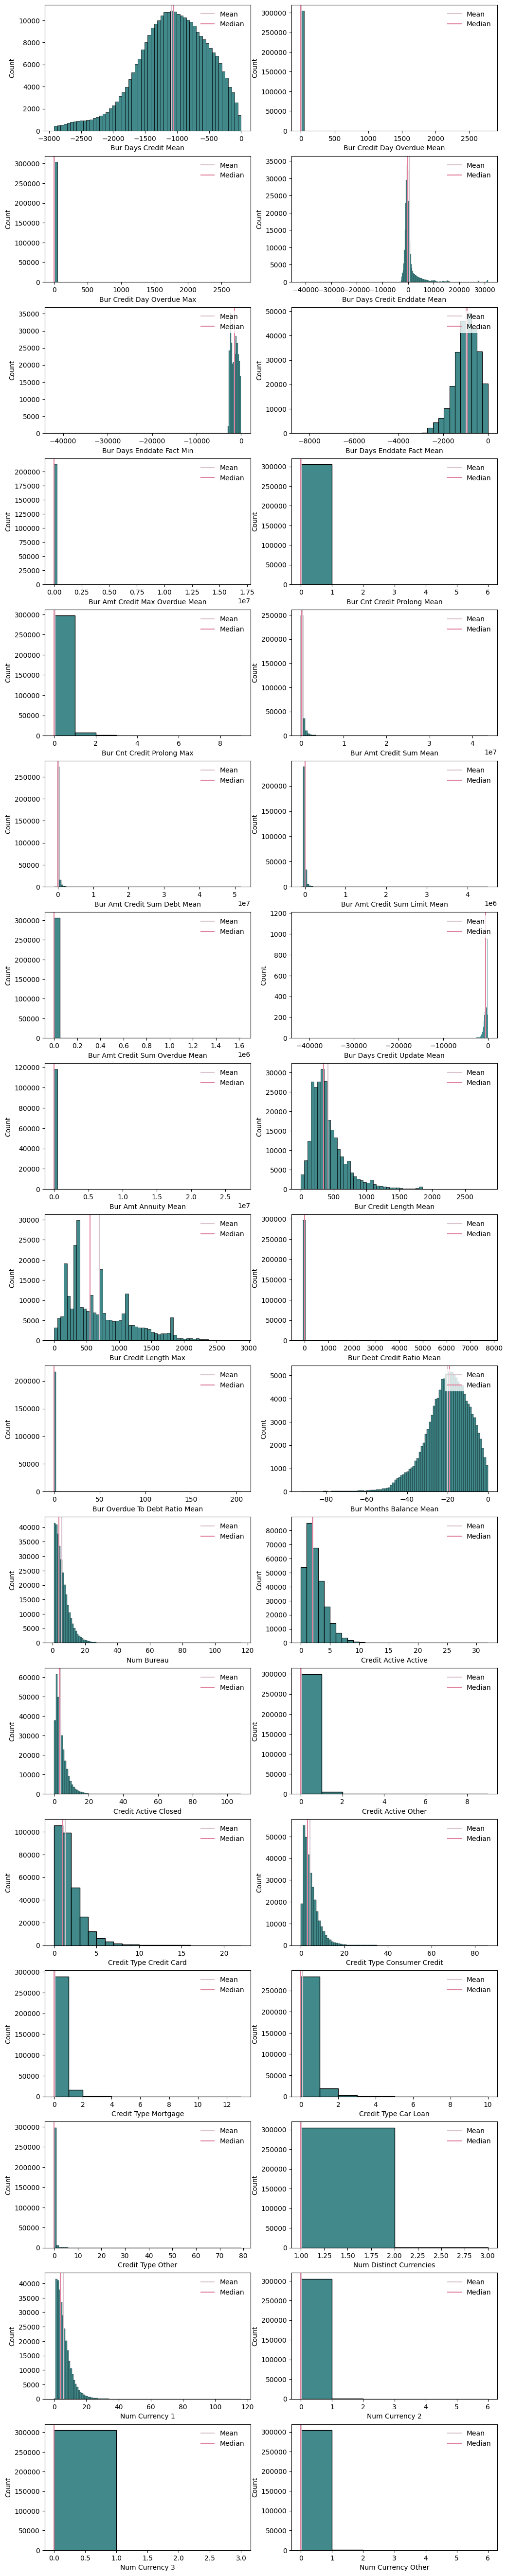

In [73]:
size = round(len(num_f) / 2)

fig, axs = plt.subplots(size, 2, figsize=(12, size * 4))

i = 0
j = 0
for item in num_f:
    if item in ['BUR_DAYS_CREDIT_ENDDATE_MEAN', 'BUR_DAYS_ENDDATE_FACT_MIN', 'BUR_DAYS_ENDDATE_FACT_MEAN']:
        binw = 250
    elif item in ['BUR_AMT_CREDIT_SUM_OVERDUE_MEAN', 'BUR_AMT_CREDIT_SUM_LIMIT_MEAN']:
        binw = 50000
    elif item in []:
        binw = 500000
    elif item in ['BUR_AMT_CREDIT_MAX_OVERDUE_MEAN']:
        binw = 250000
    elif item in ['BUR_AMT_ANNUITY_MEAN', 'BUR_AMT_CREDIT_SUM_DEBT_MEAN', 'BUR_AMT_CREDIT_SUM_MEAN']:
        binw = 500000
    elif item in [
        'BUR_DAYS_CREDIT_MEAN',
        'BUR_CREDIT_LENGTH_MEAN',
        'BUR_CREDIT_LENGTH_MAX',
        'BUR_CREDIT_DAY_OVERDUE_MEAN',
        'BUR_CREDIT_DAY_OVERDUE_MAX',
    ]:
        binw = 50
    elif item in ['BUR_DEBT_CREDIT_RATIO_MEAN']:
        binw = 100
    elif item in [
        'BUR_OVERDUE_TO_DEBT_RATIO_MEAN',
    ]:
        binw = 2
    elif item in [
        'BUR_CNT_CREDIT_PROLONG_MEAN',
        'BUR_CNT_CREDIT_PROLONG_MAX',
        'BUR_MONTHS_BALANCE_MEAN',
        'NUM_BUREAU',
        'BUR_DAYS_CREDIT_UPDATE_MEAN',
        'NUM_DISTINCT_CURRENCIES',
        'CREDIT_ACTIVE_ACTIVE',
        'CREDIT_ACTIVE_CLOSED',
        'CREDIT_ACTIVE_OTHER',
        'CREDIT_TYPE_CREDIT_CARD',
        'CREDIT_TYPE_CONSUMER_CREDIT',
        'CREDIT_TYPE_MORTGAGE',
        'CREDIT_TYPE_CAR_LOAN',
        'CREDIT_TYPE_OTHER',
        'NUM_CURRENCY_1',
        'NUM_CURRENCY_2',
        'NUM_CURRENCY_3',
        'NUM_CURRENCY_OTHER',
    ]:
        binw = 1
    else:
        binw = None

    title = item.replace("_", " ").title()
    if j == 0:
        ax0 = histplot_f(
            bureau_agg[item], color=ch, color_median=cmed, color_mean=cmean, xlabel=title, binwidth=binw, ax=axs[i, 0]
        )
        j += 1

    else:
        ax0 = histplot_f(
            bureau_agg[item], color=ch, color_median=cmed, color_mean=cmean, xlabel=title, binwidth=binw, ax=axs[i, 1]
        )
        j = 0
        i += 1

Many features exhibit strong skewness, with a large concentration of values around zero and a long tail of extreme outliers. This distribution makes some charts less informative, as the bulk of the data is compressed within a narrow range.

#### Outliers

In [74]:
selected = bureau_agg[num_f]
outliers = outlier_f(selected)
outliers.count()

BUR_DAYS_CREDIT_MEAN                4304
BUR_CREDIT_DAY_OVERDUE_MEAN         3864
BUR_CREDIT_DAY_OVERDUE_MAX          3864
BUR_DAYS_CREDIT_ENDDATE_MEAN       34652
BUR_DAYS_ENDDATE_FACT_MIN              1
BUR_DAYS_ENDDATE_FACT_MEAN          3992
BUR_AMT_CREDIT_MAX_OVERDUE_MEAN    30102
BUR_CNT_CREDIT_PROLONG_MEAN         8796
BUR_CNT_CREDIT_PROLONG_MAX          8796
BUR_AMT_CREDIT_SUM_MEAN            28036
BUR_AMT_CREDIT_SUM_DEBT_MEAN       28995
BUR_AMT_CREDIT_SUM_LIMIT_MEAN      56511
BUR_AMT_CREDIT_SUM_OVERDUE_MEAN     3801
BUR_DAYS_CREDIT_UPDATE_MEAN         6917
BUR_AMT_ANNUITY_MEAN                8207
BUR_CREDIT_LENGTH_MEAN             13619
BUR_CREDIT_LENGTH_MAX               3180
BUR_DEBT_CREDIT_RATIO_MEAN          8261
BUR_OVERDUE_TO_DEBT_RATIO_MEAN      2720
BUR_MONTHS_BALANCE_MEAN             1950
NUM_BUREAU                          6611
CREDIT_ACTIVE_ACTIVE                7525
CREDIT_ACTIVE_CLOSED               10071
CREDIT_ACTIVE_OTHER                 6039
CREDIT_TYPE_CRED

There are plenty of outliers in this dataset, which will addressed during modeling.

#### Charts for Binary Features

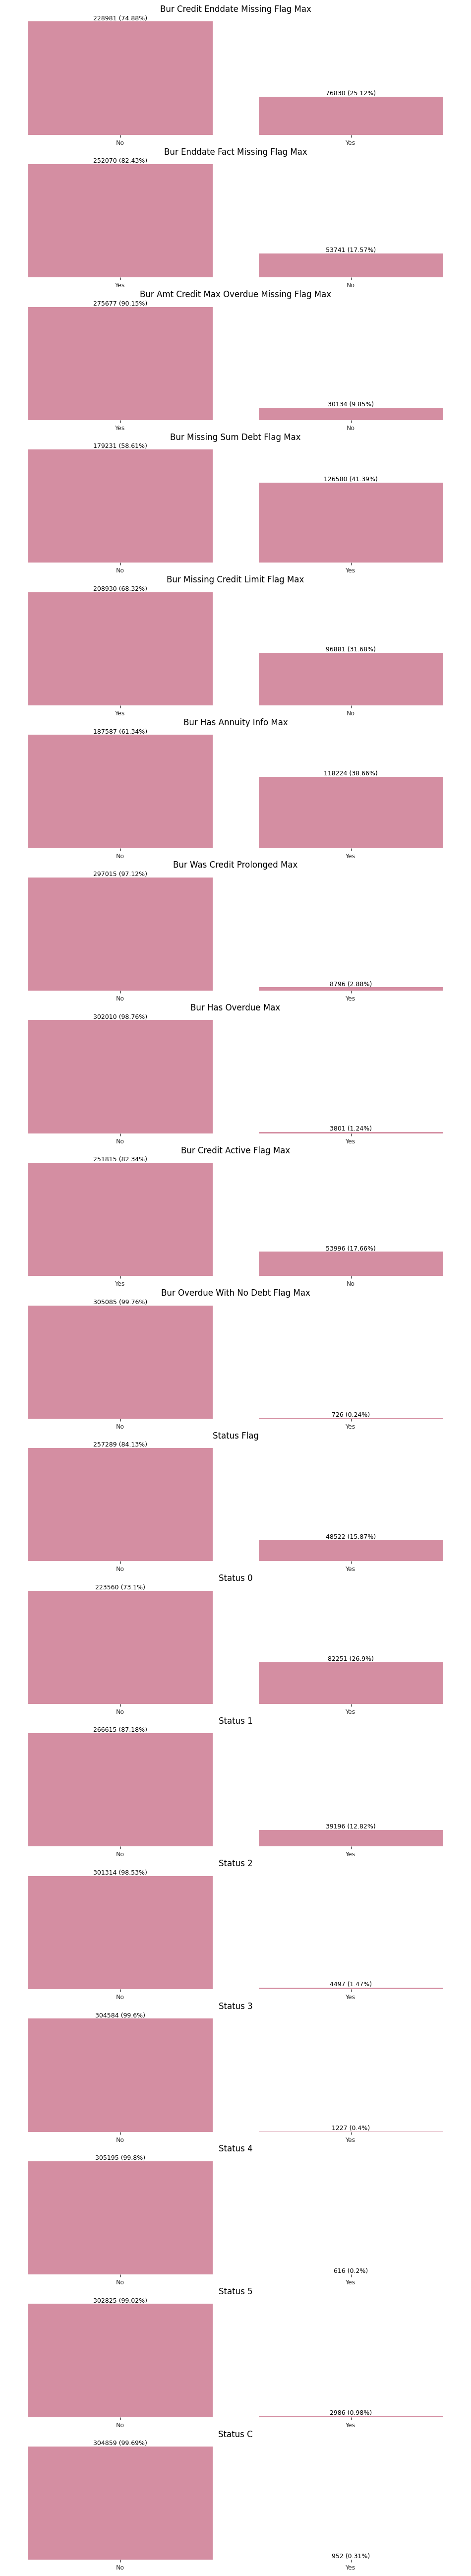

In [75]:
fig, axs = plt.subplots(len(bi_f), 1, figsize=(12, (3.7 * len(bi_f))))

i = 0
for item in bi_f:
    temp = bureau_agg[item].value_counts()
    title = item.replace("_", " ").title()
    ax1 = bar_plot_f_perc(temp, title, color='#e0829d', ax=axs[i])

    ind = temp.index
    if ind[0] == 0 and ind[1] == 1 and len(ind) == 2:
        ax1.set_xticklabels(['No', 'Yes'])
    if ind[0] == 1 and ind[1] == 0 and len(ind) == 2:
        ax1.set_xticklabels(['Yes', 'No'])

    i += 1

Some of the features are rare, for example there are only 1.24% of clients which have overdue max, or overdue with no debt flag max (0.24%).

# POS Cash Balance

## Checking for Nulls and Duplicates

### Duplicates

In [76]:
pos_cash.columns.duplicated().any()

np.False_

In [77]:
pos_cash.duplicated().any()

np.False_

### Missing Values

In [78]:
result = pos_cash.isnull().sum()
rows_nr = pos_cash.shape[0]
for item in pos_cash.columns:
    missing_nr = result[item]
    if missing_nr > 0:
        missing_perc = count_percentage(missing_nr, rows_nr, round_value=4)
        print(f'The percentage of missing {item} values is {missing_perc}%.')

The percentage of missing CNT_INSTALMENT values is 0.2607%.
The percentage of missing CNT_INSTALMENT_FUTURE values is 0.2608%.


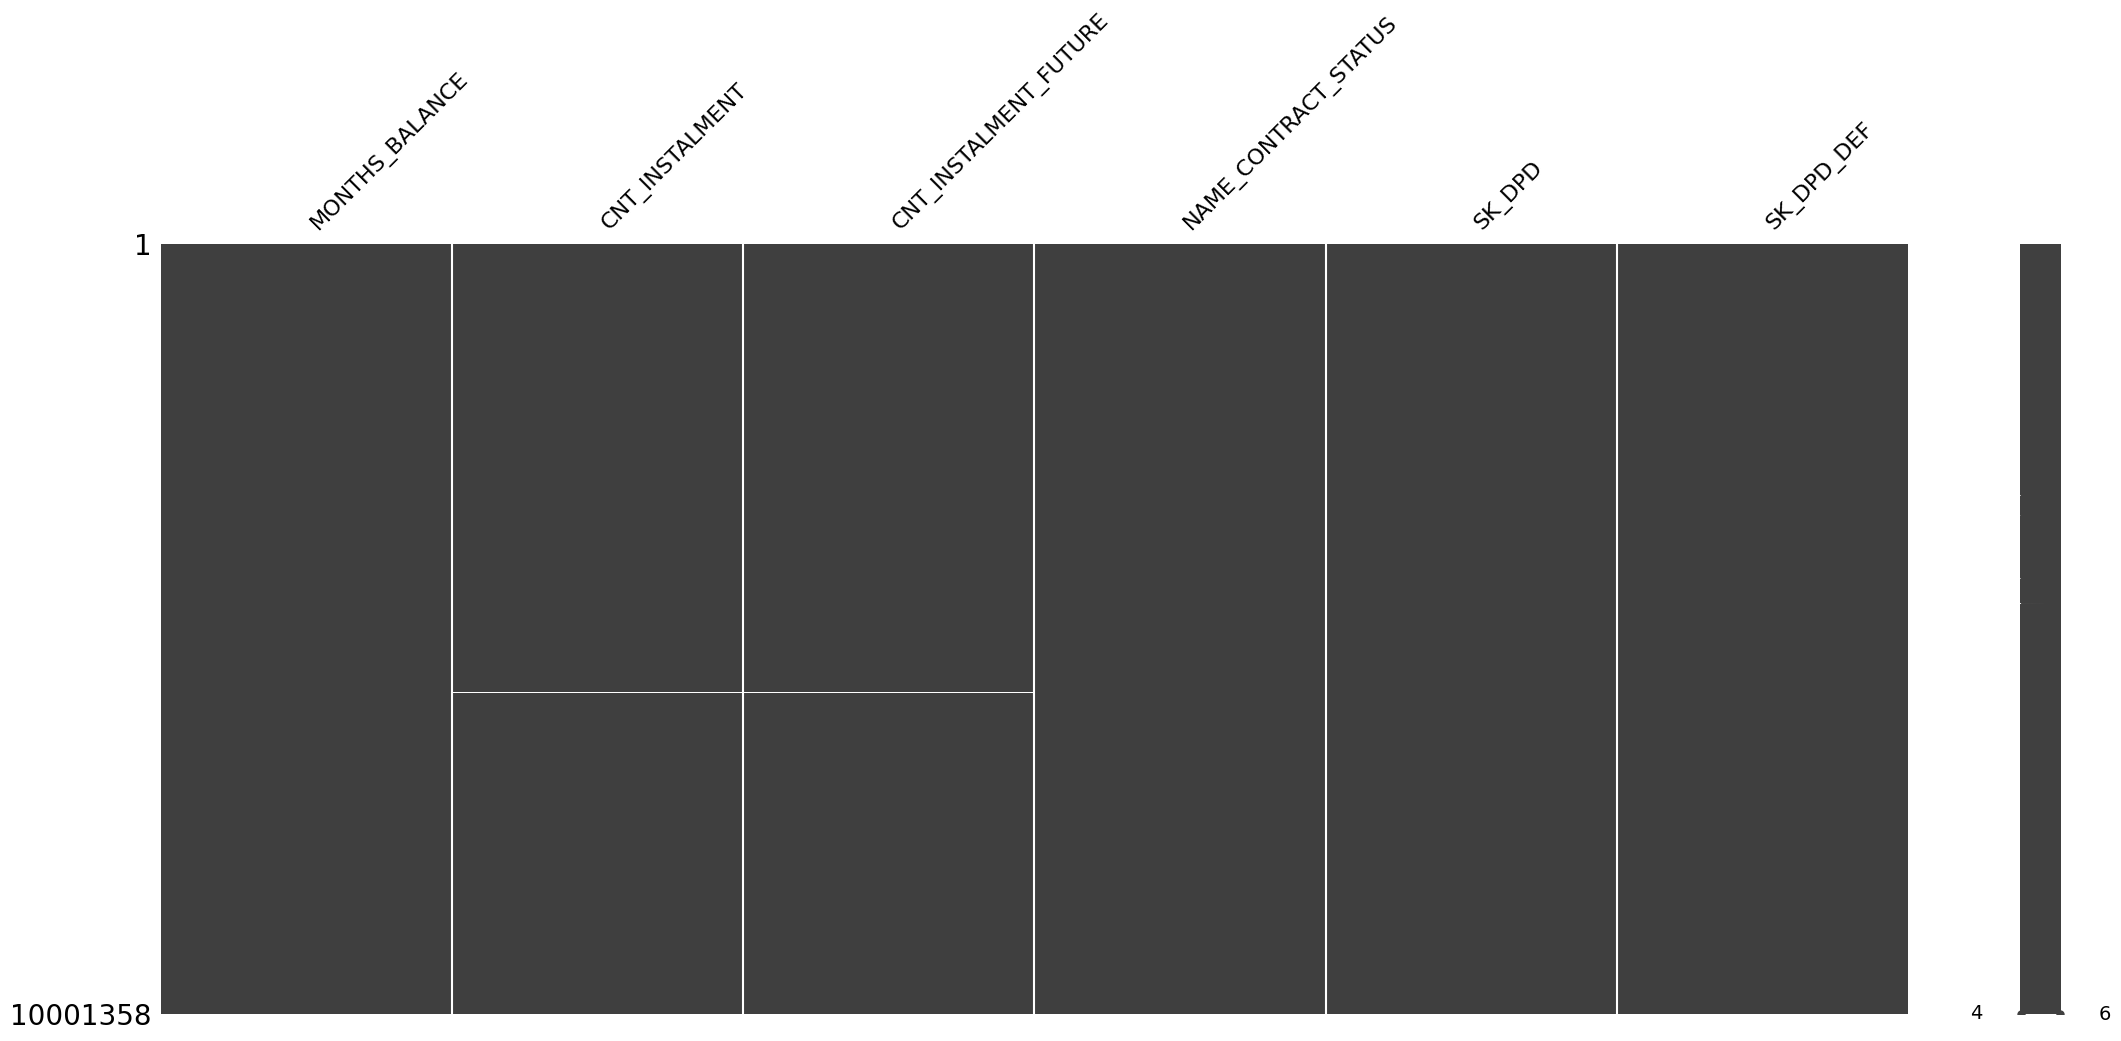

In [79]:
%matplotlib inline

msno.matrix(pos_cash.iloc[:, 2:]);

There isn't a high percentage of missing values in the dataset. Therefore they will not be investigated further and will be filled in during modeling.

## Exploring Data

In [80]:
query = '''
SELECT * 
FROM HomeCredit_columns_description
WHERE "Table" = 'POS_CASH_balance.csv'
'''

info = db.sql(query).df()
info

,Table,Row,Description,Special
0,POS_CASH_balance.csv,SK_ID_PREV,ID of previous credit in Home Credit related t...,None
1,POS_CASH_balance.csv,SK_ID_CURR,ID of loan in our sample,None
2,POS_CASH_balance.csv,MONTHS_BALANCE,Month of balance relative to application date ...,time only relative to the application
3,POS_CASH_balance.csv,CNT_INSTALMENT,Term of previous credit (can change over time),None
4,POS_CASH_balance.csv,CNT_INSTALMENT_FUTURE,Installments left to pay on the previous credit,None
5,POS_CASH_balance.csv,NAME_CONTRACT_STATUS,Contract status during the month,None
6,POS_CASH_balance.csv,SK_DPD,DPD (days past due) during the month of previo...,None
7,POS_CASH_balance.csv,SK_DPD_DEF,DPD during the month with tolerance (debts wit...,None


In [81]:
pos_cash.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 10001358 entries, 0 to 10001357
Data columns (total 8 columns):
 #   Column                 Dtype  
---  ------                 -----  
 0   SK_ID_PREV             int64  
 1   SK_ID_CURR             int64  
 2   MONTHS_BALANCE         int64  
 3   CNT_INSTALMENT         float64
 4   CNT_INSTALMENT_FUTURE  float64
 5   NAME_CONTRACT_STATUS   object 
 6   SK_DPD                 int64  
 7   SK_DPD_DEF             int64  
dtypes: float64(2), int64(5), object(1)
memory usage: 610.4+ MB


In [82]:
pos_cash_noid = pos_cash.iloc[:, 2:]
pos_cash_noid.describe()

,MONTHS_BALANCE,CNT_INSTALMENT,CNT_INSTALMENT_FUTURE,SK_DPD,SK_DPD_DEF
count,1.000136e+07,9.975287e+06,9.975271e+06,1.000136e+07,1.000136e+07
mean,-3.501259e+01,1.708965e+01,1.048384e+01,1.160693e+01,6.544684e-01
std,2.606657e+01,1.199506e+01,1.110906e+01,1.327140e+02,3.276249e+01
min,-9.600000e+01,1.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00
25%,-5.400000e+01,1.000000e+01,3.000000e+00,0.000000e+00,0.000000e+00
50%,-2.800000e+01,1.200000e+01,7.000000e+00,0.000000e+00,0.000000e+00
75%,-1.300000e+01,2.400000e+01,1.400000e+01,0.000000e+00,0.000000e+00
max,-1.000000e+00,9.200000e+01,8.500000e+01,4.231000e+03,3.595000e+03


In [83]:
for i in pos_cash.columns:
    print(i, "column's total unique values are:", pos_cash[i].nunique())

SK_ID_PREV column's total unique values are: 936325
SK_ID_CURR column's total unique values are: 337252
MONTHS_BALANCE column's total unique values are: 96
CNT_INSTALMENT column's total unique values are: 73
CNT_INSTALMENT_FUTURE column's total unique values are: 79
NAME_CONTRACT_STATUS column's total unique values are: 9
SK_DPD column's total unique values are: 3400
SK_DPD_DEF column's total unique values are: 2307


In [84]:
features_cat = pos_cash_noid.select_dtypes(include=['object']).columns

for i in features_cat:
    print(i, "column's unique values are:", pos_cash_noid[i].unique())

NAME_CONTRACT_STATUS column's unique values are: ['Active' 'Completed' 'Signed' 'Approved' 'Returned to the store' 'Demand'
 'Canceled' 'XNA' 'Amortized debt']


## Charts

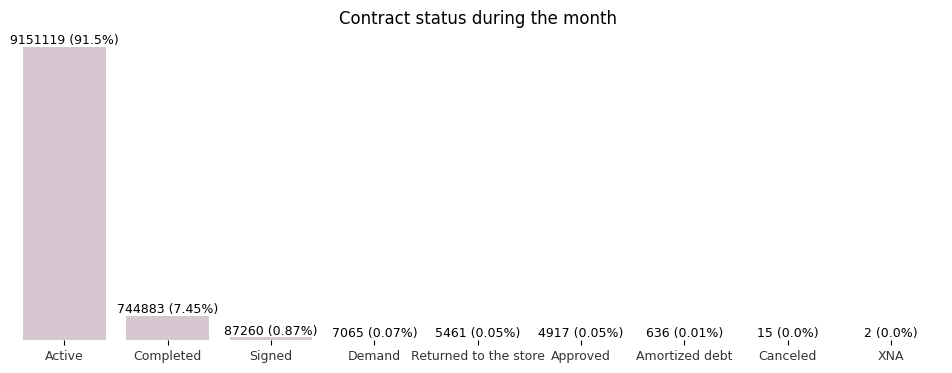

In [85]:
fig = plt.figure(figsize=(12, 4))

temp = pos_cash.NAME_CONTRACT_STATUS.value_counts()
ax = bar_plot_f_perc(temp, 'Contract status during the month', color='#dac4d0')

Majority of the contract statuses during the month were active.

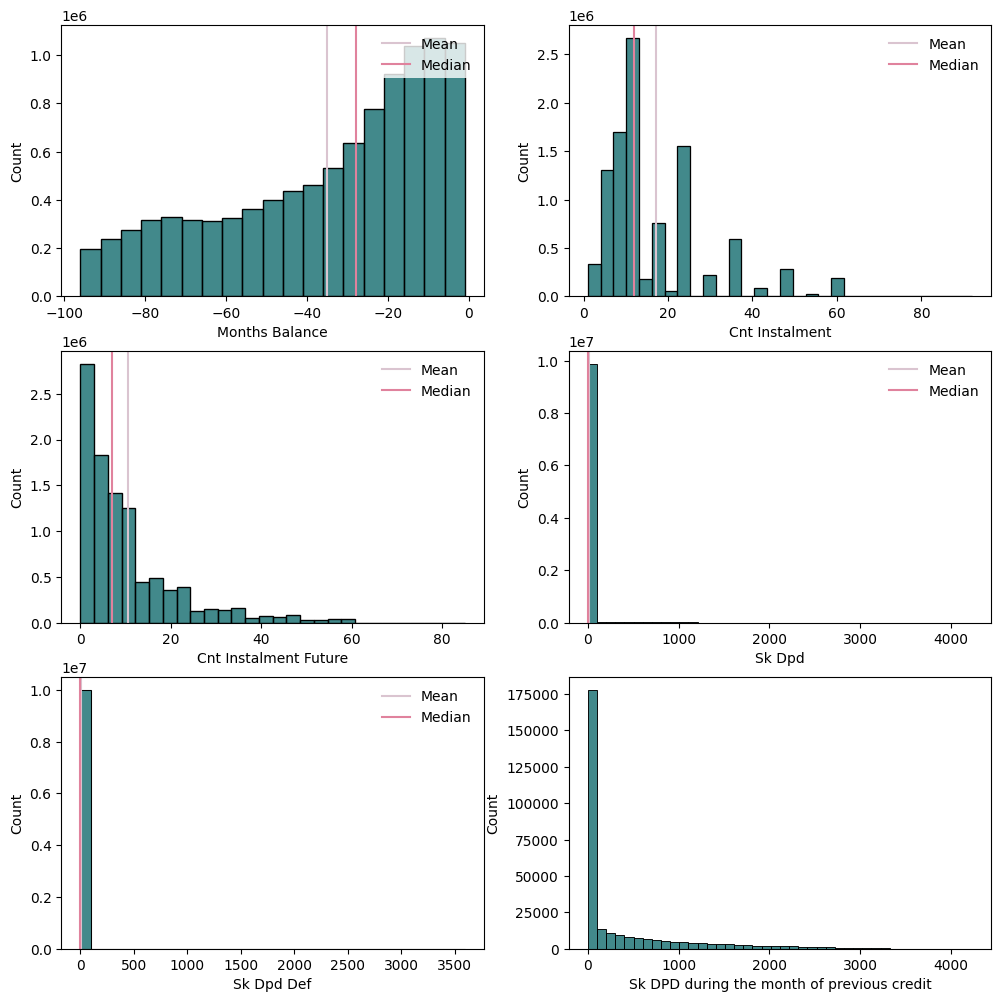

In [86]:
num_f = pos_cash_noid.select_dtypes(include=['float', 'int']).columns

size = round(len(num_f) / 2) + 1

fig, axs = plt.subplots(size, 2, figsize=(12, size * 4))

i = 0
j = 0
for item in num_f:
    if item in ['MONTHS_BALANCE']:
        binw = 5
    elif item in ['CNT_INSTALMENT', 'CNT_INSTALMENT_FUTURE']:
        binw = 3
    elif item in ['SK_DPD', 'SK_DPD_DEF']:
        binw = 100
    else:
        binw = None

    title = item.replace("_", " ").title()
    if j == 0:
        ax00 = histplot_f(
            pos_cash[item], color=ch, color_median=cmed, color_mean=cmean, xlabel=title, binwidth=binw, ax=axs[i, 0]
        )
        j += 1

    else:
        ax01 = histplot_f(
            pos_cash[item], color=ch, color_median=cmed, color_mean=cmean, xlabel=title, binwidth=binw, ax=axs[i, 1]
        )
        j = 0
        i += 1

query = '''
SELECT SK_DPD 
FROM pos_cash
WHERE SK_DPD != 0
'''
temp = db.sql(query).df()
ax21 = histplot_f(
    temp['SK_DPD'],
    color=ch,
    color_median=cmed,
    color_mean=cmean,
    xlabel='Sk DPD during the month of previous credit',
    mean_meadian=False,
    binwidth=100,
    ax=axs[2, 1],
)

The features are skewed. Bottom right graph represent SK DPD without 0 values.

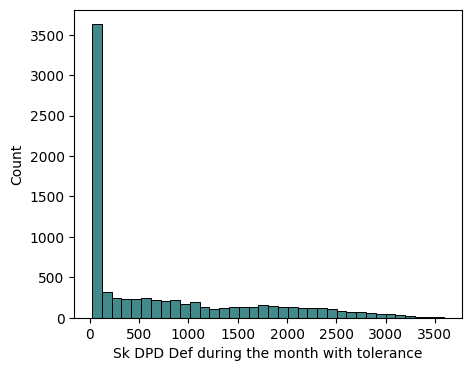

In [87]:
fig = plt.figure(figsize=(5, 4))

query = '''
SELECT SK_DPD_DEF 
FROM pos_cash
WHERE SK_DPD_DEF > 21
'''
temp = db.sql(query).df()
ax21 = histplot_f(
    temp['SK_DPD_DEF'],
    color=ch,
    color_median=cmed,
    color_mean=cmean,
    xlabel='Sk DPD Def during the month with tolerance',
    mean_meadian=False,
    binwidth=100,
)

SK DPD Def without 0 values. 

In [88]:
pos_cash['HAD_DPD'] = pos_cash['SK_DPD'].apply(lambda x: 1 if x > 0 else 0)
pos_cash['HAD_DPD_DEF'] = pos_cash['SK_DPD_DEF'].apply(lambda x: 1 if x > 0 else 0)

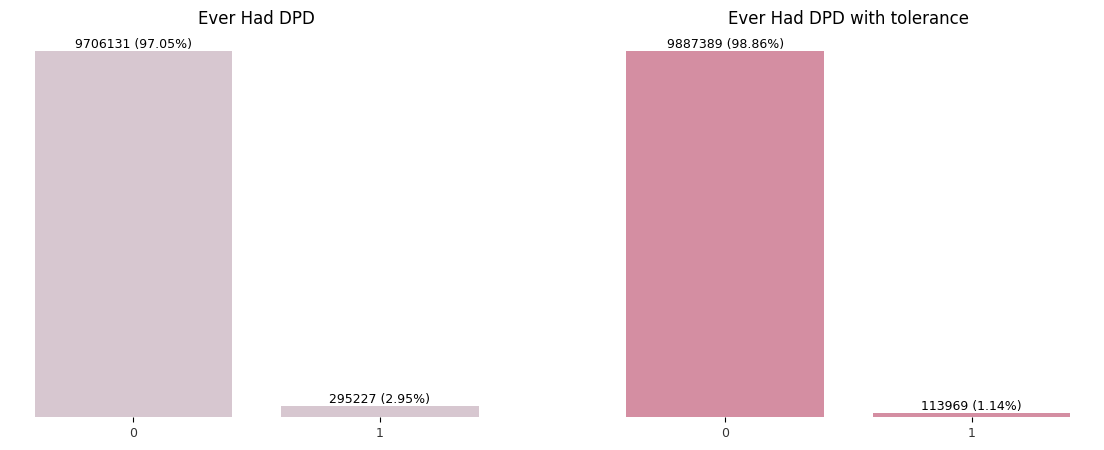

In [89]:
fig, axs = plt.subplots(1, 2, figsize=(14, 5))

temp = pos_cash.HAD_DPD.value_counts()
ax0 = bar_plot_f_perc(temp, 'Ever Had DPD', color='#dac4d0', ax=axs[0])

temp = pos_cash.HAD_DPD_DEF.value_counts()
ax1 = bar_plot_f_perc(temp, 'Ever Had DPD with tolerance', color='#e0829d', ax=axs[1]);

Majority of clients never had DPD

## Aggregations

In [91]:
aggregations = {
    'MONTHS_BALANCE': ['min', 'mean'],
    'CNT_INSTALMENT': ['mean', 'max'],
    'CNT_INSTALMENT_FUTURE': ['mean', 'sum'],
    'SK_DPD': ['mean', 'max'],
    'SK_DPD_DEF': ['mean', 'max'],
    'HAD_DPD': ['max'],
    'HAD_DPD_DEF': ['max'],
}

pos_agg = pos_cash.groupby('SK_ID_CURR').agg(aggregations)
pos_agg.columns = ['POS_' + '_'.join(col).upper() for col in pos_agg.columns]
pos_agg.reset_index(inplace=True)

query = """
with t1 as (
    SELECT 
        SK_ID_CURR,
        COUNT(DISTINCT SK_ID_PREV) AS NUM_PREVIOUS_POS_LOANS,
        CASE WHEN COUNT(DISTINCT SK_ID_PREV) > 0 THEN 1 ELSE 0 END AS HAS_PREVIOUS_POS
    FROM pos_cash
    GROUP BY SK_ID_CURR
    ), 

    t2 as (
    SELECT 
    SK_ID_CURR,
    COUNT(DISTINCT CASE WHEN has_active = 1 THEN SK_ID_PREV ELSE NULL END) AS POS_ACTIVE_LOANS,
    FROM (
        SELECT 
            SK_ID_CURR,
            SK_ID_PREV,
            MAX(CASE WHEN NAME_CONTRACT_STATUS = 'Active' THEN 1 ELSE 0 END) AS has_active,
        FROM pos_cash
        GROUP BY SK_ID_CURR, SK_ID_PREV
    ) AS loan_flags
    GROUP BY SK_ID_CURR
    )

SELECT *
FROM pos_agg pa
JOIN t1
ON pa.SK_ID_CURR = t1.SK_ID_CURR
LEFT JOIN t2
ON pa.SK_ID_CURR = t2.SK_ID_CURR;
"""

pos_agg = db.sql(query).df().drop(['SK_ID_CURR_1', 'SK_ID_CURR_2'], axis=1)
pos_agg.iloc[:, 1:].describe()

,POS_MONTHS_BALANCE_MIN,POS_MONTHS_BALANCE_MEAN,POS_CNT_INSTALMENT_MEAN,POS_CNT_INSTALMENT_MAX,POS_CNT_INSTALMENT_FUTURE_MEAN,POS_CNT_INSTALMENT_FUTURE_SUM,POS_SK_DPD_MEAN,POS_SK_DPD_MAX,POS_SK_DPD_DEF_MEAN,POS_SK_DPD_DEF_MAX,POS_HAD_DPD_MAX,POS_HAD_DPD_DEF_MAX,NUM_PREVIOUS_POS_LOANS,HAS_PREVIOUS_POS,POS_ACTIVE_LOANS
count,337252.000000,337252.000000,337224.000000,337224.000000,337224.000000,337252.000000,337252.000000,337252.000000,337252.000000,337252.000000,337252.000000,337252.000000,337252.000000,337252.0,337252.000000
mean,-52.874349,-31.873263,14.654990,20.425999,9.176876,310.092005,4.296271,15.294106,0.225470,1.473355,0.186756,0.136245,2.776336,1.0,2.764680
std,29.690356,20.081193,7.969848,13.909296,6.501034,382.481670,59.717229,151.343806,13.554576,32.337266,0.389717,0.343049,1.975222,0.0,1.969632
min,-96.000000,-96.000000,1.000000,1.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,1.000000,1.0,0.000000
25%,-82.000000,-43.988354,9.625000,12.000000,5.000000,72.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,1.000000,1.0,1.000000
50%,-51.000000,-28.571429,12.000000,12.000000,6.989411,164.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,2.000000,1.0,2.000000
75%,-25.000000,-15.500000,18.600000,24.000000,11.666667,396.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,4.000000,1.0,4.000000
max,-1.000000,-1.000000,72.000000,92.000000,60.000000,5539.000000,2622.078431,4231.000000,1740.554455,3595.000000,1.000000,1.000000,26.000000,1.0,26.000000


### Missing Values in Aggregation

In [92]:
result = pos_agg.isnull().sum()
rows_nr = pos_agg.shape[0]
for item in pos_agg.columns:
    missing_nr = result[item]
    if missing_nr > 0:
        missing_perc = count_percentage(missing_nr, rows_nr, round_value=4)
        print(f'The percentage of missing {item} values is {missing_perc}%.')

The percentage of missing POS_CNT_INSTALMENT_MEAN values is 0.0083%.
The percentage of missing POS_CNT_INSTALMENT_MAX values is 0.0083%.
The percentage of missing POS_CNT_INSTALMENT_FUTURE_MEAN values is 0.0083%.


Percentage-vice there are less missing values after the aggregation. They will be addressed during modeling part.

### Drawing Charts for Agregations

In [93]:
pos_agg.columns

Index(['SK_ID_CURR', 'POS_MONTHS_BALANCE_MIN', 'POS_MONTHS_BALANCE_MEAN',
       'POS_CNT_INSTALMENT_MEAN', 'POS_CNT_INSTALMENT_MAX',
       'POS_CNT_INSTALMENT_FUTURE_MEAN', 'POS_CNT_INSTALMENT_FUTURE_SUM',
       'POS_SK_DPD_MEAN', 'POS_SK_DPD_MAX', 'POS_SK_DPD_DEF_MEAN',
       'POS_SK_DPD_DEF_MAX', 'POS_HAD_DPD_MAX', 'POS_HAD_DPD_DEF_MAX',
       'NUM_PREVIOUS_POS_LOANS', 'HAS_PREVIOUS_POS', 'POS_ACTIVE_LOANS'],
      dtype='object')

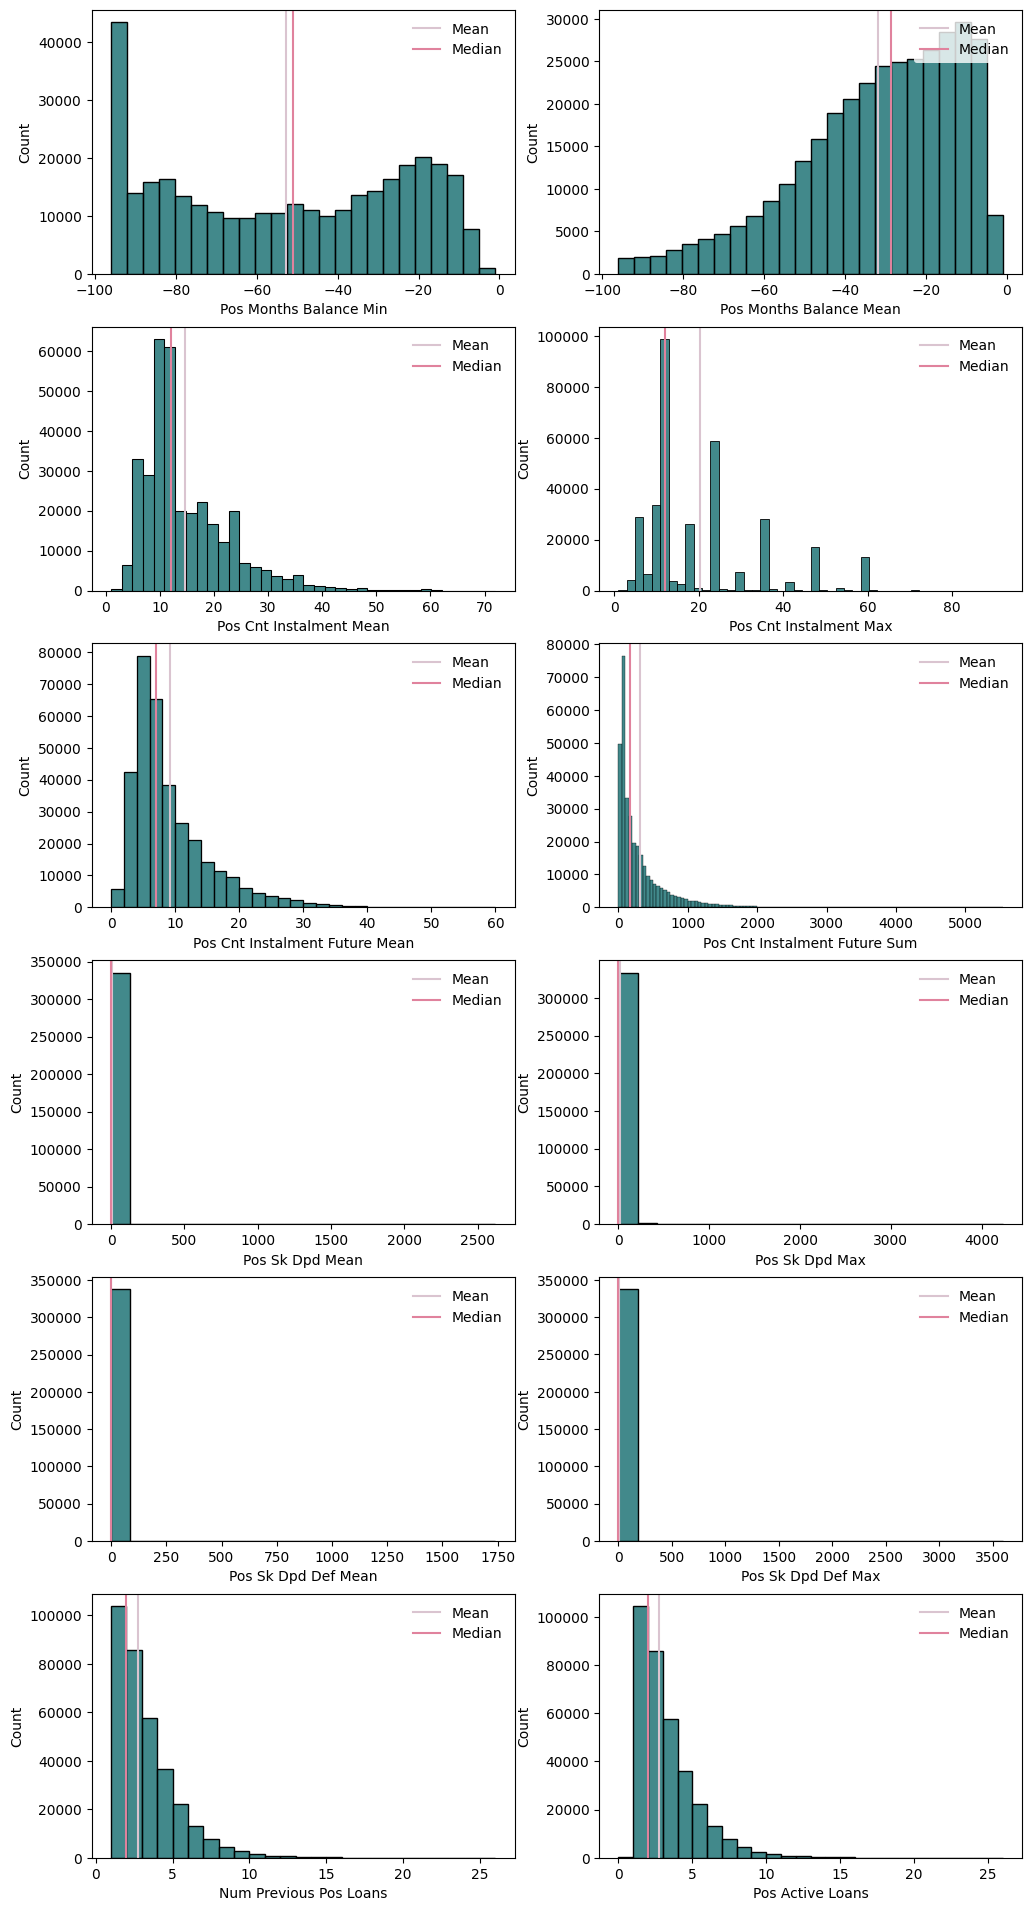

In [94]:
num_bi_f = pos_agg.iloc[:, 1:].select_dtypes(include=['float', 'int']).columns
num_f = []
bi_f = []

for item in num_bi_f:
    if len(pos_agg[item].unique()) > 2:
        num_f.append(item)
    else:
        bi_f.append(item)
bi_f.remove('HAS_PREVIOUS_POS')

size = round(len(num_f) / 2)

fig, axs = plt.subplots(size, 2, figsize=(12, size * 4))

i = 0
j = 0
for item in num_f:
    if item in ['POS_MONTHS_BALANCE_MIN', 'POS_MONTHS_BALANCE_MEAN']:
        binw = 4
    elif item in ['POS_CNT_INSTALMENT_MEAN', 'POS_CNT_INSTALMENT_MAX', 'POS_CNT_INSTALMENT_FUTURE_MEAN']:
        binw = 2
    elif item in ['POS_CNT_INSTALMENT_FUTURE_SUM']:
        binw = 50
    elif item in ['POS_ACTIVE_LOANS', 'NUM_PREVIOUS_POS_LOANS']:
        binw = 1
    else:
        binw = None

    title = item.replace("_", " ").title()
    if j == 0:
        ax00 = histplot_f(
            pos_agg[item], color=ch, color_median=cmed, color_mean=cmean, xlabel=title, binwidth=binw, ax=axs[i, 0]
        )
        j += 1

    else:
        ax01 = histplot_f(
            pos_agg[item], color=ch, color_median=cmed, color_mean=cmean, xlabel=title, binwidth=binw, ax=axs[i, 1]
        )
        j = 0
        i += 1

After agregation the features are still skewed.

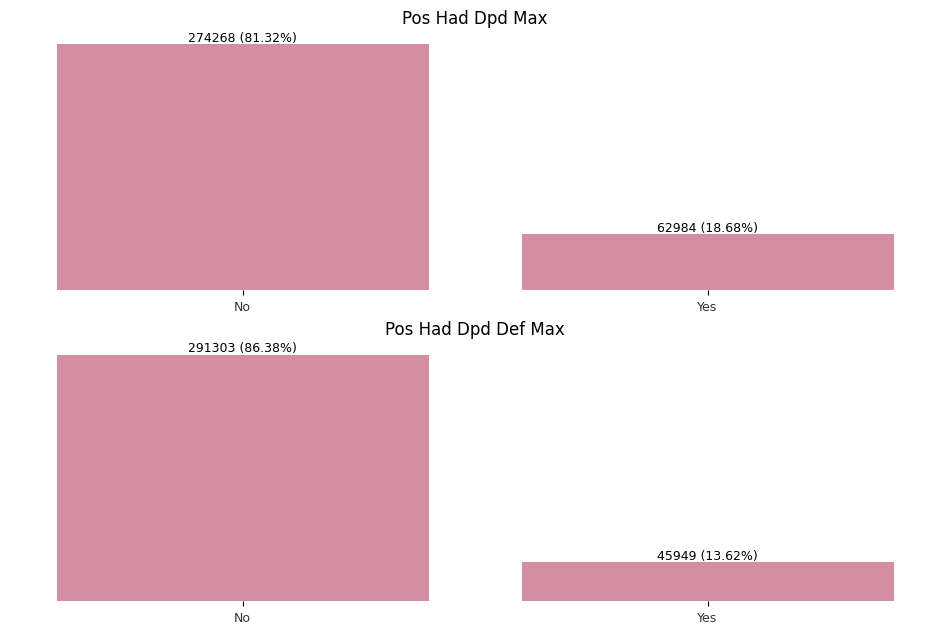

In [95]:
fig, axs = plt.subplots(len(bi_f), 1, figsize=(12, (3.7 * len(bi_f))))

i = 0
for item in bi_f:
    temp = pos_agg[item].value_counts()
    title = item.replace("_", " ").title()
    ax1 = bar_plot_f_perc(temp, title, color='#e0829d', ax=axs[i])

    ind = temp.index
    if ind[0] == 0 and ind[1] == 1 and len(ind) == 2:
        ax1.set_xticklabels(['No', 'Yes'])
    if ind[0] == 1 and ind[1] == 0 and len(ind) == 2:
        ax1.set_xticklabels(['Yes', 'No'])

    i += 1

Around 18.68% of clients had DPD and 13.62% had DPD with tolerance.

### Outliers

In [96]:
selected = pos_agg[num_f]
outliers = outlier_f(selected)
outliers.count()

POS_MONTHS_BALANCE_MIN                0
POS_MONTHS_BALANCE_MEAN            4502
POS_CNT_INSTALMENT_MEAN           13524
POS_CNT_INSTALMENT_MAX            32098
POS_CNT_INSTALMENT_FUTURE_MEAN    18753
POS_CNT_INSTALMENT_FUTURE_SUM     27061
POS_SK_DPD_MEAN                   62984
POS_SK_DPD_MAX                    62984
POS_SK_DPD_DEF_MEAN               45949
POS_SK_DPD_DEF_MAX                45949
NUM_PREVIOUS_POS_LOANS             6095
POS_ACTIVE_LOANS                   5998
dtype: int64

Removing outliers will be tested during modeling.

# Credit Card Balance

## Checking for Nulls and Duplicates

### Duplicates

In [97]:
credit_card_balance.duplicated().any()

np.False_

In [98]:
credit_card_balance.columns.duplicated().any()

np.False_

### Missing Values

In [99]:
result = credit_card_balance.isnull().sum()
rows_nr = credit_card_balance.shape[0]
for item in credit_card_balance.columns:
    missing_nr = result[item]
    if missing_nr > 0:
        missing_perc = count_percentage(missing_nr, rows_nr, round_value=4)
        print(f'The percentage of missing {item} values is {missing_perc}%.')

The percentage of missing AMT_DRAWINGS_ATM_CURRENT values is 19.5249%.
The percentage of missing AMT_DRAWINGS_OTHER_CURRENT values is 19.5249%.
The percentage of missing AMT_DRAWINGS_POS_CURRENT values is 19.5249%.
The percentage of missing AMT_INST_MIN_REGULARITY values is 7.9482%.
The percentage of missing AMT_PAYMENT_CURRENT values is 19.9981%.
The percentage of missing CNT_DRAWINGS_ATM_CURRENT values is 19.5249%.
The percentage of missing CNT_DRAWINGS_OTHER_CURRENT values is 19.5249%.
The percentage of missing CNT_DRAWINGS_POS_CURRENT values is 19.5249%.
The percentage of missing CNT_INSTALMENT_MATURE_CUM values is 7.9482%.


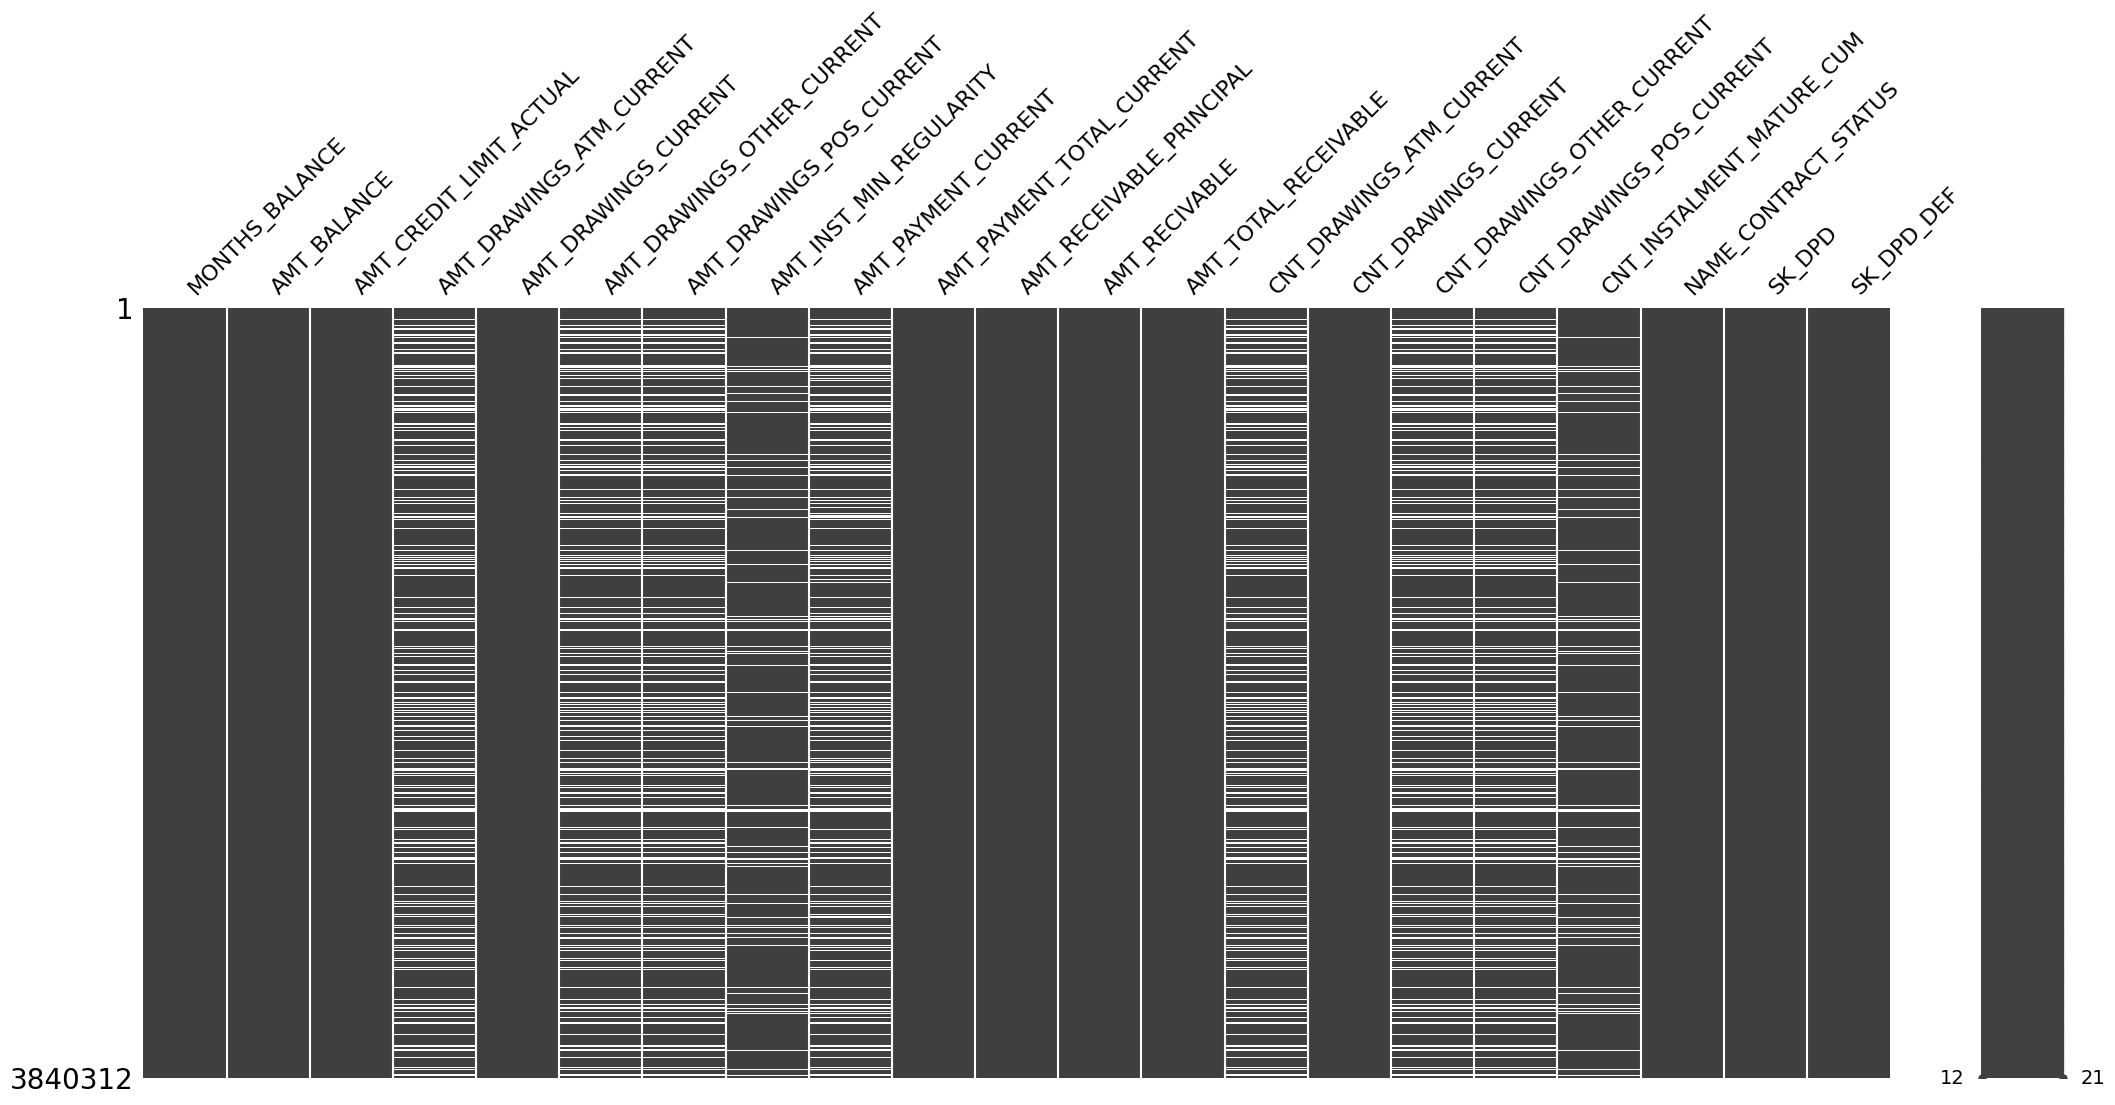

In [100]:
%matplotlib inline

msno.matrix(credit_card_balance.iloc[:, 2:]);

In [101]:
query = '''
SELECT * 
FROM credit_card_balance
WHERE AMT_INST_MIN_REGULARITY IS NULL AND CNT_INSTALMENT_MATURE_CUM IS NOT NULL
'''

assert db.sql(query).df().shape[0] == 0

All of the missing values of AMT_INST_MIN_REGULARITY are missing together with CNT_INSTALMENT_MATURE_CUM.

In [102]:
credit_card_balance['AMT_INST_MIN_REGULARITY'].isnull().groupby(credit_card_balance['NAME_CONTRACT_STATUS']).mean()

NAME_CONTRACT_STATUS
Active           0.081083
Approved         1.000000
Completed        0.001133
Demand           0.000000
Refused          1.000000
Sent proposal    1.000000
Signed           0.422680
Name: AMT_INST_MIN_REGULARITY, dtype: float64

All rows with status "Approved", "Refused", or "Sent proposal" are missing AMT_INST_MIN_REGULARITY — this likely means the contract was never started, so the minimum installment value was never set. “Signed” contracts have ~42% missing — probably a mix of initiated and abandoned contracts.

In [104]:
cols = [
    'AMT_DRAWINGS_ATM_CURRENT',
    'AMT_DRAWINGS_OTHER_CURRENT',
    'AMT_DRAWINGS_POS_CURRENT',
    'CNT_DRAWINGS_ATM_CURRENT',
    'CNT_DRAWINGS_OTHER_CURRENT',
    'CNT_DRAWINGS_POS_CURRENT',
]

joint_missing = credit_card_balance[cols].isnull().all(axis=1).sum()
any_missing = credit_card_balance[cols].isnull().any(axis=1).sum()

print(f"Rows where ALL are missing: {joint_missing}")
print(f"Rows where ANY are missing: {any_missing}")
print(f"Same? {joint_missing == any_missing}")

Rows where ALL are missing: 749816
Rows where ANY are missing: 749816
Same? True


In [105]:
credit_card_balance['AMT_DRAWINGS_ATM_CURRENT'].isnull().groupby(credit_card_balance['NAME_CONTRACT_STATUS']).mean()

NAME_CONTRACT_STATUS
Active           0.195139
Approved         1.000000
Completed        0.176895
Demand           0.000000
Refused          1.000000
Sent proposal    0.855750
Signed           0.437873
Name: AMT_DRAWINGS_ATM_CURRENT, dtype: float64

Statuses like 'Approved', 'Refused', and 'Sent proposal' often lack drawing data, possibly because they were never activated (i.e., customer didn't actually use the card). 'Active' or 'Completed' contracts still have a decent portion of missing values, which could mean: Data wasn't recorded at that time or the customer had an active card but never used ATM withdrawals.

In [107]:
credit_card_balance['AMT_PAYMENT_CURRENT'].isnull().groupby(credit_card_balance['NAME_CONTRACT_STATUS']).mean()

NAME_CONTRACT_STATUS
Active           0.200458
Approved         0.000000
Completed        0.174840
Demand           0.073260
Refused          0.058824
Sent proposal    0.087719
Signed           0.354675
Name: AMT_PAYMENT_CURRENT, dtype: float64

In [108]:
credit_card_balance['AMT_PAYMENT_CURRENT'].isnull().groupby(credit_card_balance['MISSING_DRAWINGS']).mean()

MISSING_DRAWINGS
0    0.014808
1    0.963200
Name: AMT_PAYMENT_CURRENT, dtype: float64

In [109]:
credit_card_balance[credit_card_balance['AMT_PAYMENT_CURRENT'].isnull()]['MONTHS_BALANCE'].describe()

count    767988.000000
mean        -23.568971
std          21.980119
min         -96.000000
25%         -32.000000
50%         -16.000000
75%          -8.000000
max          -1.000000
Name: MONTHS_BALANCE, dtype: float64

The missing payments are not random — they align with no drawing activity. This strongly supports the idea that these accounts had no drawing/payment activity in that month. The time distribution is skewed toward older records (-96 = 96 months before application). These are likely non-active months.

## Exploring Data

### Features

In [111]:
query = '''
SELECT * 
FROM HomeCredit_columns_description
WHERE "Table" = 'credit_card_balance.csv'
'''

info = db.sql(query).df()
info

,Table,Row,Description,Special
0,credit_card_balance.csv,SK_ID_PREV,ID of previous credit in Home credit related t...,hashed
1,credit_card_balance.csv,SK_ID_CURR,ID of loan in our sample,hashed
2,credit_card_balance.csv,MONTHS_BALANCE,Month of balance relative to application date ...,time only relative to the application
3,credit_card_balance.csv,AMT_BALANCE,Balance during the month of previous credit,None
4,credit_card_balance.csv,AMT_CREDIT_LIMIT_ACTUAL,Credit card limit during the month of the prev...,None
5,credit_card_balance.csv,AMT_DRAWINGS_ATM_CURRENT,Amount drawing at ATM during the month of the ...,None
6,credit_card_balance.csv,AMT_DRAWINGS_CURRENT,Amount drawing during the month of the previou...,None
7,credit_card_balance.csv,AMT_DRAWINGS_OTHER_CURRENT,Amount of other drawings during the month of t...,None
8,credit_card_balance.csv,AMT_DRAWINGS_POS_CURRENT,Amount drawing or buying goods during the mont...,None
9,credit_card_balance.csv,AMT_INST_MIN_REGULARITY,Minimal installment for this month of the prev...,None


In [112]:
credit_card_balance.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 3840312 entries, 0 to 3840311
Data columns (total 27 columns):
 #   Column                      Dtype  
---  ------                      -----  
 0   SK_ID_PREV                  int64  
 1   SK_ID_CURR                  int64  
 2   MONTHS_BALANCE              int64  
 3   AMT_BALANCE                 float64
 4   AMT_CREDIT_LIMIT_ACTUAL     int64  
 5   AMT_DRAWINGS_ATM_CURRENT    float64
 6   AMT_DRAWINGS_CURRENT        float64
 7   AMT_DRAWINGS_OTHER_CURRENT  float64
 8   AMT_DRAWINGS_POS_CURRENT    float64
 9   AMT_INST_MIN_REGULARITY     float64
 10  AMT_PAYMENT_CURRENT         float64
 11  AMT_PAYMENT_TOTAL_CURRENT   float64
 12  AMT_RECEIVABLE_PRINCIPAL    float64
 13  AMT_RECIVABLE               float64
 14  AMT_TOTAL_RECEIVABLE        float64
 15  CNT_DRAWINGS_ATM_CURRENT    float64
 16  CNT_DRAWINGS_CURRENT        int64  
 17  CNT_DRAWINGS_OTHER_CURRENT  float64
 18  CNT_DRAWINGS_POS_CURRENT    float64
 19  CNT_INSTALMENT_MATURE

In [113]:
credit_card_balance_noid = credit_card_balance.iloc[:, 2:]
credit_card_balance_noid.describe()

,MONTHS_BALANCE,AMT_BALANCE,AMT_CREDIT_LIMIT_ACTUAL,AMT_DRAWINGS_ATM_CURRENT,AMT_DRAWINGS_CURRENT,AMT_DRAWINGS_OTHER_CURRENT,AMT_DRAWINGS_POS_CURRENT,AMT_INST_MIN_REGULARITY,AMT_PAYMENT_CURRENT,AMT_PAYMENT_TOTAL_CURRENT,...,CNT_DRAWINGS_CURRENT,CNT_DRAWINGS_OTHER_CURRENT,CNT_DRAWINGS_POS_CURRENT,CNT_INSTALMENT_MATURE_CUM,SK_DPD,SK_DPD_DEF,HAS_INSTALMENT_INFO,MISSING_DRAWINGS,NO_ACTIVITY_MONTH,MISSING_PAYMENT
count,3.840312e+06,3.840312e+06,3.840312e+06,3.090496e+06,3.840312e+06,3.090496e+06,3.090496e+06,3.535076e+06,3.072324e+06,3.840312e+06,...,3.840312e+06,3.090496e+06,3.090496e+06,3.535076e+06,3.840312e+06,3.840312e+06,3.840312e+06,3.840312e+06,3.840312e+06,3.840312e+06
mean,-3.452192e+01,5.830016e+04,1.538080e+05,5.961325e+03,7.433388e+03,2.881696e+02,2.968805e+03,3.540204e+03,1.028054e+04,7.588857e+03,...,7.031439e-01,4.812496e-03,5.594791e-01,2.082508e+01,9.283667e+00,3.316220e-01,9.205179e-01,1.952487e-01,1.880636e-01,1.999806e-01
std,2.666775e+01,1.063070e+05,1.651457e+05,2.822569e+04,3.384608e+04,8.201989e+03,2.079689e+04,5.600154e+03,3.607808e+04,3.200599e+04,...,3.190347e+00,8.263861e-02,3.240649e+00,2.005149e+01,9.751570e+01,2.147923e+01,2.704897e-01,3.963921e-01,3.907630e-01,3.999855e-01
min,-9.600000e+01,-4.202502e+05,0.000000e+00,-6.827310e+03,-6.211620e+03,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,...,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00
25%,-5.500000e+01,0.000000e+00,4.500000e+04,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,1.523700e+02,0.000000e+00,...,0.000000e+00,0.000000e+00,0.000000e+00,4.000000e+00,0.000000e+00,0.000000e+00,1.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00
50%,-2.800000e+01,0.000000e+00,1.125000e+05,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,2.702700e+03,0.000000e+00,...,0.000000e+00,0.000000e+00,0.000000e+00,1.500000e+01,0.000000e+00,0.000000e+00,1.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00
75%,-1.100000e+01,8.904669e+04,1.800000e+05,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,6.633911e+03,9.000000e+03,6.750000e+03,...,0.000000e+00,0.000000e+00,0.000000e+00,3.200000e+01,0.000000e+00,0.000000e+00,1.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00
max,-1.000000e+00,1.505902e+06,1.350000e+06,2.115000e+06,2.287098e+06,1.529847e+06,2.239274e+06,2.028820e+05,4.289207e+06,4.278316e+06,...,1.650000e+02,1.200000e+01,1.650000e+02,1.200000e+02,3.260000e+03,3.260000e+03,1.000000e+00,1.000000e+00,1.000000e+00,1.000000e+00


In [114]:
for i in credit_card_balance.columns:
    print(i, "column's total unique values are:", credit_card_balance[i].nunique())

SK_ID_PREV column's total unique values are: 104307
SK_ID_CURR column's total unique values are: 103558
MONTHS_BALANCE column's total unique values are: 96
AMT_BALANCE column's total unique values are: 1347904
AMT_CREDIT_LIMIT_ACTUAL column's total unique values are: 181
AMT_DRAWINGS_ATM_CURRENT column's total unique values are: 2267
AMT_DRAWINGS_CURRENT column's total unique values are: 187005
AMT_DRAWINGS_OTHER_CURRENT column's total unique values are: 1832
AMT_DRAWINGS_POS_CURRENT column's total unique values are: 168748
AMT_INST_MIN_REGULARITY column's total unique values are: 312266
AMT_PAYMENT_CURRENT column's total unique values are: 163209
AMT_PAYMENT_TOTAL_CURRENT column's total unique values are: 182957
AMT_RECEIVABLE_PRINCIPAL column's total unique values are: 1195839
AMT_RECIVABLE column's total unique values are: 1338878
AMT_TOTAL_RECEIVABLE column's total unique values are: 1339008
CNT_DRAWINGS_ATM_CURRENT column's total unique values are: 44
CNT_DRAWINGS_CURRENT column's

In [115]:
features_cat = credit_card_balance_noid.select_dtypes(include=['object']).columns

for i in features_cat:
    print(i, "column's unique values are:", credit_card_balance_noid[i].unique())

NAME_CONTRACT_STATUS column's unique values are: ['Active' 'Completed' 'Demand' 'Signed' 'Sent proposal' 'Refused'
 'Approved']


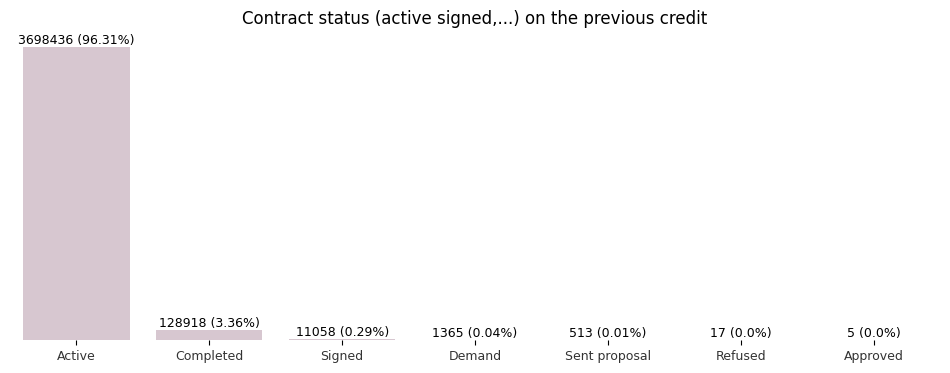

In [116]:
fig = plt.figure(figsize=(12, 4))

temp = credit_card_balance.NAME_CONTRACT_STATUS.value_counts()
ax = bar_plot_f_perc(temp, 'Contract status (active signed,...) on the previous credit', color='#dac4d0')

Majority of the contract statuses were active.

In [117]:
credit_card_balance['HAD_DPD'] = credit_card_balance['SK_DPD'].apply(lambda x: 1 if x > 0 else 0)
credit_card_balance['HAD_DPD_DEF'] = credit_card_balance['SK_DPD_DEF'].apply(lambda x: 1 if x > 0 else 0)

## Aggregation

In [118]:
aggregations = {
    'MONTHS_BALANCE': ['min', 'mean'],
    'AMT_BALANCE': ['mean'],
    'AMT_CREDIT_LIMIT_ACTUAL': ['mean'],
    'AMT_DRAWINGS_ATM_CURRENT': ['mean'],
    'AMT_DRAWINGS_CURRENT': ['mean'],
    'AMT_DRAWINGS_OTHER_CURRENT': ['mean'],
    'AMT_DRAWINGS_POS_CURRENT': ['mean'],
    'AMT_INST_MIN_REGULARITY': ['mean'],
    'AMT_PAYMENT_CURRENT': ['mean'],
    'AMT_PAYMENT_TOTAL_CURRENT': ['mean'],
    'AMT_RECEIVABLE_PRINCIPAL': ['mean'],
    'AMT_RECIVABLE': ['mean'],
    'AMT_TOTAL_RECEIVABLE': ['mean'],
    'CNT_DRAWINGS_ATM_CURRENT': ['mean'],
    'CNT_DRAWINGS_CURRENT': ['mean'],
    'CNT_DRAWINGS_OTHER_CURRENT': ['mean'],
    'CNT_DRAWINGS_POS_CURRENT': ['mean'],
    'CNT_INSTALMENT_MATURE_CUM': ['mean'],
    'SK_DPD': ['mean'],
    'SK_DPD_DEF': ['mean'],
    'NO_ACTIVITY_MONTH': ['sum'],
    'HAS_INSTALMENT_INFO': ['sum', 'min'],
    'MISSING_DRAWINGS': ['sum', 'min', 'max'],
    'MISSING_PAYMENT': ['sum', 'min', 'max'],
    'HAD_DPD': ['max'],
    'HAD_DPD_DEF': ['max'],
}

cc_bal_agg = credit_card_balance.groupby('SK_ID_CURR').agg(aggregations)
cc_bal_agg.columns = ['CC_' + '_'.join(col).upper() for col in cc_bal_agg.columns]
cc_bal_agg.reset_index(inplace=True)

query = """
with t1 as (
    SELECT 
        SK_ID_CURR,
        COUNT(DISTINCT SK_ID_PREV) AS NUM_CREDIT_CARD,
        CASE WHEN COUNT(DISTINCT SK_ID_PREV) > 0 THEN 1 ELSE 0 END AS HAS_PREVIOUS_CREDIT_CARD
    FROM credit_card_balance
    GROUP BY SK_ID_CURR
    ), 

    t2 as (
    SELECT 
    SK_ID_CURR,
    COUNT(DISTINCT CASE WHEN has_active = 1 THEN SK_ID_PREV ELSE NULL END) AS CC_ACTIVE,
    COUNT(DISTINCT CASE WHEN has_completed = 1 THEN SK_ID_PREV ELSE NULL END) AS CC_COMPLETED,
    FROM (
        SELECT 
            SK_ID_CURR,
            SK_ID_PREV,
            MAX(CASE WHEN NAME_CONTRACT_STATUS = 'Active' THEN 1 ELSE 0 END) AS has_active,
            MAX(CASE WHEN NAME_CONTRACT_STATUS = 'Completed' THEN 1 ELSE 0 END) AS has_completed,
        FROM credit_card_balance
        GROUP BY SK_ID_CURR, SK_ID_PREV
    ) AS loan_flags
    GROUP BY SK_ID_CURR
    )

SELECT *
FROM cc_bal_agg cc
JOIN t1
ON cc.SK_ID_CURR = t1.SK_ID_CURR
LEFT JOIN t2
ON cc.SK_ID_CURR = t2.SK_ID_CURR;
"""

cc_bal_agg = db.sql(query).df().drop(['SK_ID_CURR_1', 'SK_ID_CURR_2'], axis=1)
cc_bal_agg.iloc[:, 1:].describe()

,CC_MONTHS_BALANCE_MIN,CC_MONTHS_BALANCE_MEAN,CC_AMT_BALANCE_MEAN,CC_AMT_CREDIT_LIMIT_ACTUAL_MEAN,CC_AMT_DRAWINGS_ATM_CURRENT_MEAN,CC_AMT_DRAWINGS_CURRENT_MEAN,CC_AMT_DRAWINGS_OTHER_CURRENT_MEAN,CC_AMT_DRAWINGS_POS_CURRENT_MEAN,CC_AMT_INST_MIN_REGULARITY_MEAN,CC_AMT_PAYMENT_CURRENT_MEAN,...,CC_MISSING_DRAWINGS_MAX,CC_MISSING_PAYMENT_SUM,CC_MISSING_PAYMENT_MIN,CC_MISSING_PAYMENT_MAX,CC_HAD_DPD_MAX,CC_HAD_DPD_DEF_MAX,NUM_CREDIT_CARD,HAS_PREVIOUS_CREDIT_CARD,CC_ACTIVE,CC_COMPLETED
count,103558.000000,103558.000000,103558.000000,1.035580e+05,72194.000000,1.035580e+05,72194.000000,7.219400e+04,103558.000000,7.212000e+04,...,103558.000000,103558.000000,103558.000000,103558.000000,103558.000000,103558.000000,103558.000000,103558.0,103558.000000,103558.000000
mean,-37.534531,-19.505553,69973.192455,2.073207e+05,12018.179117,1.356678e+04,583.772133,8.389181e+03,3536.945932,1.793468e+04,...,0.534580,7.416018,0.303579,0.664932,0.199502,0.164439,1.007233,1.0,1.006257,0.128382
std,33.379821,16.666571,107537.810551,1.902293e+05,21302.087154,2.642765e+04,4518.785160,2.310356e+04,5088.463531,2.842948e+04,...,0.498805,15.700424,0.459805,0.472017,0.399628,0.370675,0.085869,0.0,0.090275,0.337877
min,-96.000000,-50.179775,-2930.232558,0.000000e+00,0.000000,-1.757812e+01,0.000000,0.000000e+00,0.000000,0.000000e+00,...,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,1.000000,1.0,0.000000,0.000000
25%,-75.000000,-38.000000,0.000000,8.250000e+04,1046.511628,0.000000e+00,0.000000,0.000000e+00,0.000000,4.668147e+03,...,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,1.000000,1.0,1.000000,0.000000
50%,-22.000000,-12.000000,24997.602995,1.490000e+05,4500.000000,3.329349e+03,0.000000,3.657905e+02,1623.508258,9.856811e+03,...,1.000000,1.000000,0.000000,1.000000,0.000000,0.000000,1.000000,1.0,1.000000,0.000000
75%,-11.000000,-6.000000,96997.746023,2.675000e+05,15350.390625,1.791554e+04,0.000000,8.547148e+03,5006.284788,2.134006e+04,...,1.000000,7.000000,1.000000,1.000000,0.000000,0.000000,1.000000,1.0,1.000000,0.000000
max,-1.000000,-1.000000,928686.323571,1.350000e+06,904500.000000,1.616206e+06,225000.000000,1.616206e+06,43014.126429,1.593111e+06,...,1.000000,113.000000,1.000000,1.000000,1.000000,1.000000,4.000000,1.0,4.000000,3.000000


In [119]:
result = cc_bal_agg.isnull().sum()
rows_nr = cc_bal_agg.shape[0]
for item in cc_bal_agg.columns:
    missing_nr = result[item]
    if missing_nr > 0:
        missing_perc = count_percentage(missing_nr, rows_nr, round_value=4)
        print(f'The percentage of missing {item} values is {missing_perc}%.')

The percentage of missing CC_AMT_DRAWINGS_ATM_CURRENT_MEAN values is 30.2864%.
The percentage of missing CC_AMT_DRAWINGS_OTHER_CURRENT_MEAN values is 30.2864%.
The percentage of missing CC_AMT_DRAWINGS_POS_CURRENT_MEAN values is 30.2864%.
The percentage of missing CC_AMT_PAYMENT_CURRENT_MEAN values is 30.3579%.
The percentage of missing CC_CNT_DRAWINGS_ATM_CURRENT_MEAN values is 30.2864%.
The percentage of missing CC_CNT_DRAWINGS_OTHER_CURRENT_MEAN values is 30.2864%.
The percentage of missing CC_CNT_DRAWINGS_POS_CURRENT_MEAN values is 30.2864%.


In [120]:
query = '''
SELECT * 
FROM cc_bal_agg
WHERE CC_AMT_DRAWINGS_CURRENT_MEAN != 0 AND CC_AMT_DRAWINGS_ATM_CURRENT_MEAN IS NULL
'''

db.sql(query).df()

,SK_ID_CURR,CC_MONTHS_BALANCE_MIN,CC_MONTHS_BALANCE_MEAN,CC_AMT_BALANCE_MEAN,CC_AMT_CREDIT_LIMIT_ACTUAL_MEAN,CC_AMT_DRAWINGS_ATM_CURRENT_MEAN,CC_AMT_DRAWINGS_CURRENT_MEAN,CC_AMT_DRAWINGS_OTHER_CURRENT_MEAN,CC_AMT_DRAWINGS_POS_CURRENT_MEAN,CC_AMT_INST_MIN_REGULARITY_MEAN,...,CC_MISSING_DRAWINGS_MAX,CC_MISSING_PAYMENT_SUM,CC_MISSING_PAYMENT_MIN,CC_MISSING_PAYMENT_MAX,CC_HAD_DPD_MAX,CC_HAD_DPD_DEF_MAX,NUM_CREDIT_CARD,HAS_PREVIOUS_CREDIT_CARD,CC_ACTIVE,CC_COMPLETED


In [121]:
query = '''
SELECT * 
FROM cc_bal_agg
WHERE CC_AMT_PAYMENT_TOTAL_CURRENT_MEAN != 0 and CC_AMT_PAYMENT_CURRENT_MEAN IS NULL
'''

db.sql(query).df()

,SK_ID_CURR,CC_MONTHS_BALANCE_MIN,CC_MONTHS_BALANCE_MEAN,CC_AMT_BALANCE_MEAN,CC_AMT_CREDIT_LIMIT_ACTUAL_MEAN,CC_AMT_DRAWINGS_ATM_CURRENT_MEAN,CC_AMT_DRAWINGS_CURRENT_MEAN,CC_AMT_DRAWINGS_OTHER_CURRENT_MEAN,CC_AMT_DRAWINGS_POS_CURRENT_MEAN,CC_AMT_INST_MIN_REGULARITY_MEAN,...,CC_MISSING_DRAWINGS_MAX,CC_MISSING_PAYMENT_SUM,CC_MISSING_PAYMENT_MIN,CC_MISSING_PAYMENT_MAX,CC_HAD_DPD_MAX,CC_HAD_DPD_DEF_MAX,NUM_CREDIT_CARD,HAS_PREVIOUS_CREDIT_CARD,CC_ACTIVE,CC_COMPLETED


Missing values are likelly not random but associated with the absence of payments or credit card usage.

### Charts

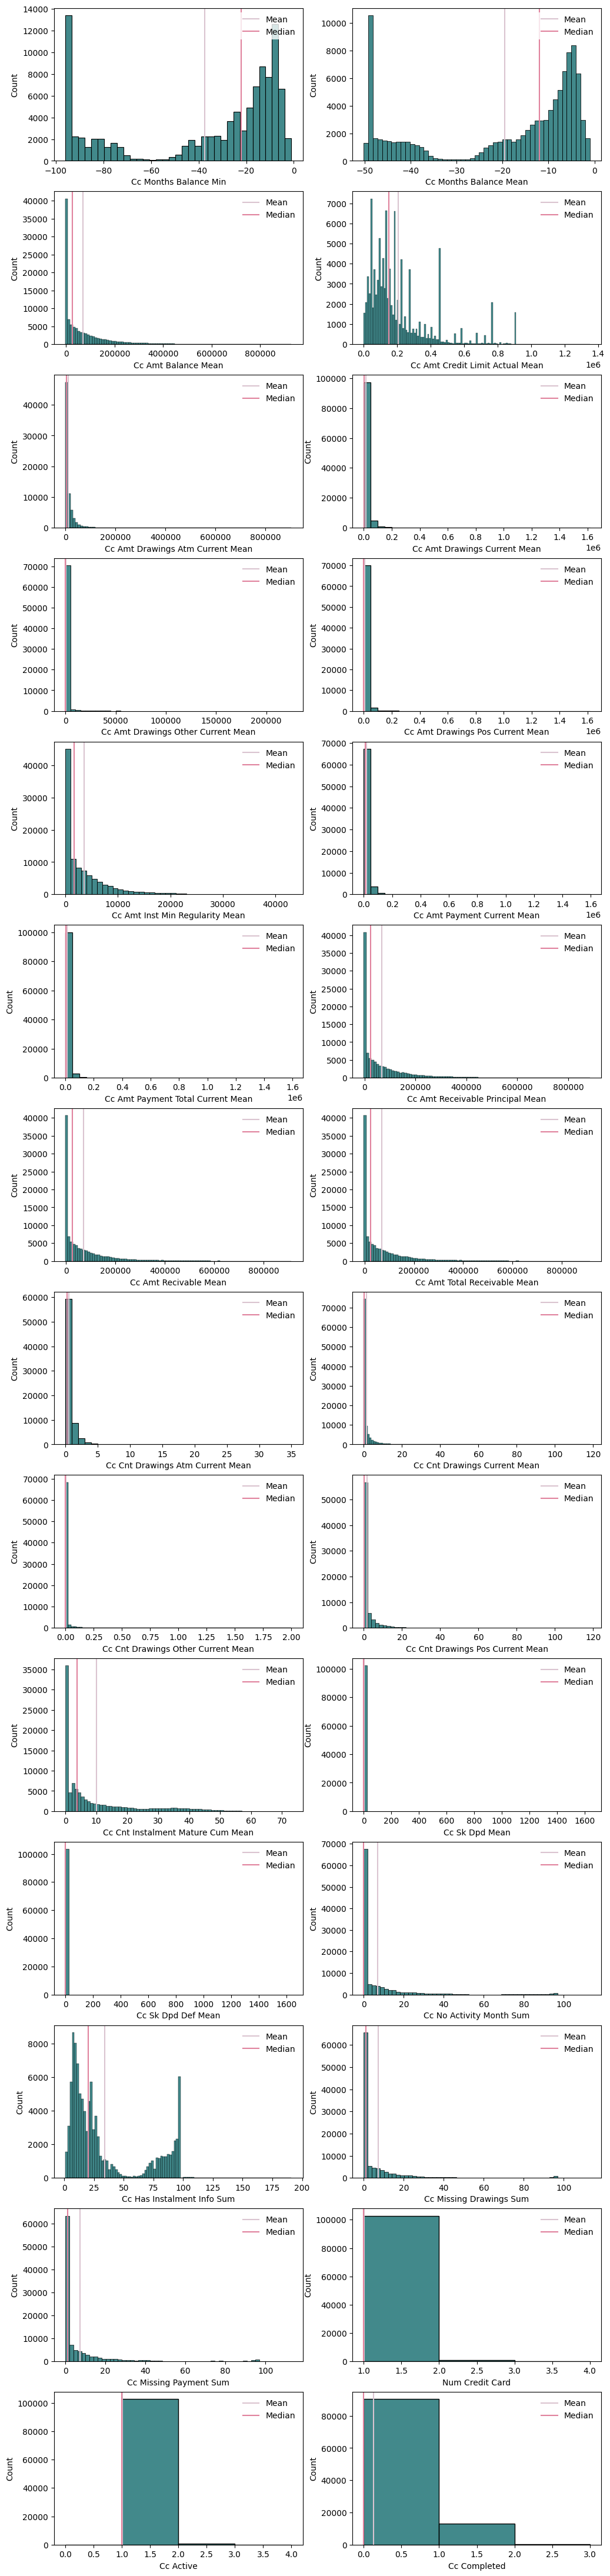

In [122]:
num_bi_f = cc_bal_agg.iloc[:, 1:].select_dtypes(include=['float', 'int']).columns
num_f = []
bi_f = []

for item in num_bi_f:
    if len(cc_bal_agg[item].unique()) > 2:
        num_f.append(item)
    else:
        bi_f.append(item)
bi_f.remove('HAS_PREVIOUS_CREDIT_CARD')

size = round(len(num_f) / 2)

fig, axs = plt.subplots(size, 2, figsize=(12, size * 4))

i = 0
j = 0
for item in num_f:
    if item in ['CC_MONTHS_BALANCE_MEAN']:
        binw = 1
    elif item in [
        'CC_AMT_DRAWINGS_CURRENT_MEAN',
        'CC_AMT_DRAWINGS_POS_CURRENT_MEAN',
        'CC_AMT_PAYMENT_CURRENT_MEAN',
        'CC_AMT_PAYMENT_TOTAL_CURRENT_MEAN',
    ]:
        binw = 50000
    elif item in [
        'CC_AMT_BALANCE_MEAN',
        'CC_AMT_CREDIT_LIMIT_ACTUAL_MEAN',
        'CC_AMT_DRAWINGS_ATM_CURRENT_MEAN',
        'CC_AMT_RECEIVABLE_PRINCIPAL_MEAN',
        'CC_AMT_RECIVABLE_MEAN',
        'CC_AMT_TOTAL_RECEIVABLE_MEAN',
    ]:
        binw = 10000
    elif item in ['CC_AMT_DRAWINGS_OTHER_CURRENT_MEAN']:
        binw = 5000
    elif item in ['CC_AMT_INST_MIN_REGULARITY_MEAN']:
        binw = 1000
    elif item in [
        'CC_CNT_DRAWINGS_ATM_CURRENT_MEAN',
        'CC_CNT_DRAWINGS_CURRENT_MEAN',
        'CC_CNT_INSTALMENT_MATURE_CUM_MEAN',
        'NUM_CREDIT_CARD',
        'CC_ACTIVE',
        'CC_COMPLETED',
    ]:
        binw = 1
    elif item in [
        'CC_CNT_DRAWINGS_CURRENT_MEAN',
        'CC_CNT_DRAWINGS_POS_CURRENT_MEAN',
        'CC_MISSING_DRAWINGS_SUM',
        'CC_MISSING_PAYMENT_SUM',
        'CC_NO_ACTIVITY_MONTH_SUM',
    ]:
        binw = 2
    elif item in ['CC_CNT_DRAWINGS_OTHER_CURRENT_MEAN']:
        binw = 0.025
    elif item in ['CC_CNT_DRAWINGS_OTHER_CURRENT_MEAN']:
        binw = 0.1
    elif item in ['CC_SK_DPD_MEAN', 'CC_SK_DPD_DEF_MEAN']:
        binw = 25
    else:
        binw = None

    title = item.replace("_", " ").title()
    if j == 0:
        ax00 = histplot_f(
            cc_bal_agg[item], color=ch, color_median=cmed, color_mean=cmean, xlabel=title, binwidth=binw, ax=axs[i, 0]
        )
        j += 1

    else:
        ax01 = histplot_f(
            cc_bal_agg[item], color=ch, color_median=cmed, color_mean=cmean, xlabel=title, binwidth=binw, ax=axs[i, 1]
        )
        j = 0
        i += 1

Majority of the features are skewed to the right. Some are multimodal and have two peaks, like CC_HAS_INSTALMENT_INFO_SUM, CC_MONTHS_BALANCE_MIN and CC_MONTHS_BALANCE_MEAN.

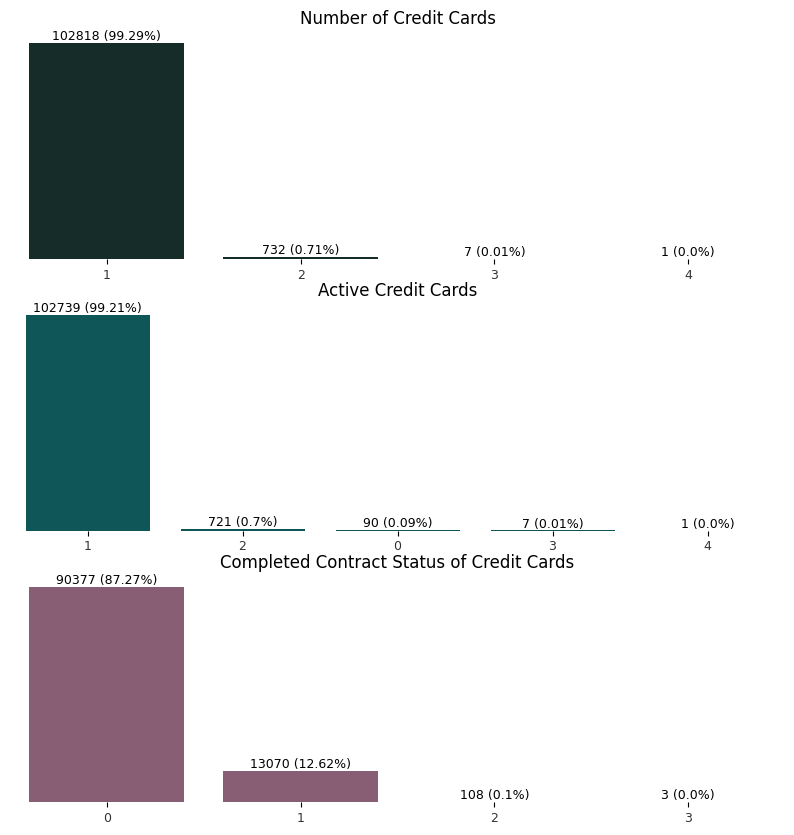

In [123]:
fig, axs = plt.subplots(3, 1, figsize=(10, 10))

temp = cc_bal_agg.NUM_CREDIT_CARD.value_counts()
ax = bar_plot_f_perc(temp, 'Number of Credit Cards', color='#11302a', ax=axs[0])

temp = cc_bal_agg.CC_ACTIVE.value_counts()
ax = bar_plot_f_perc(temp, 'Active Credit Cards', color='#036264', ax=axs[1])

temp = cc_bal_agg.CC_COMPLETED.value_counts()
ax = bar_plot_f_perc(temp, 'Completed Contract Status of Credit Cards', color='#8f5774', ax=axs[2])

Number of cards and active cards is close. Majority of clients have one card. 

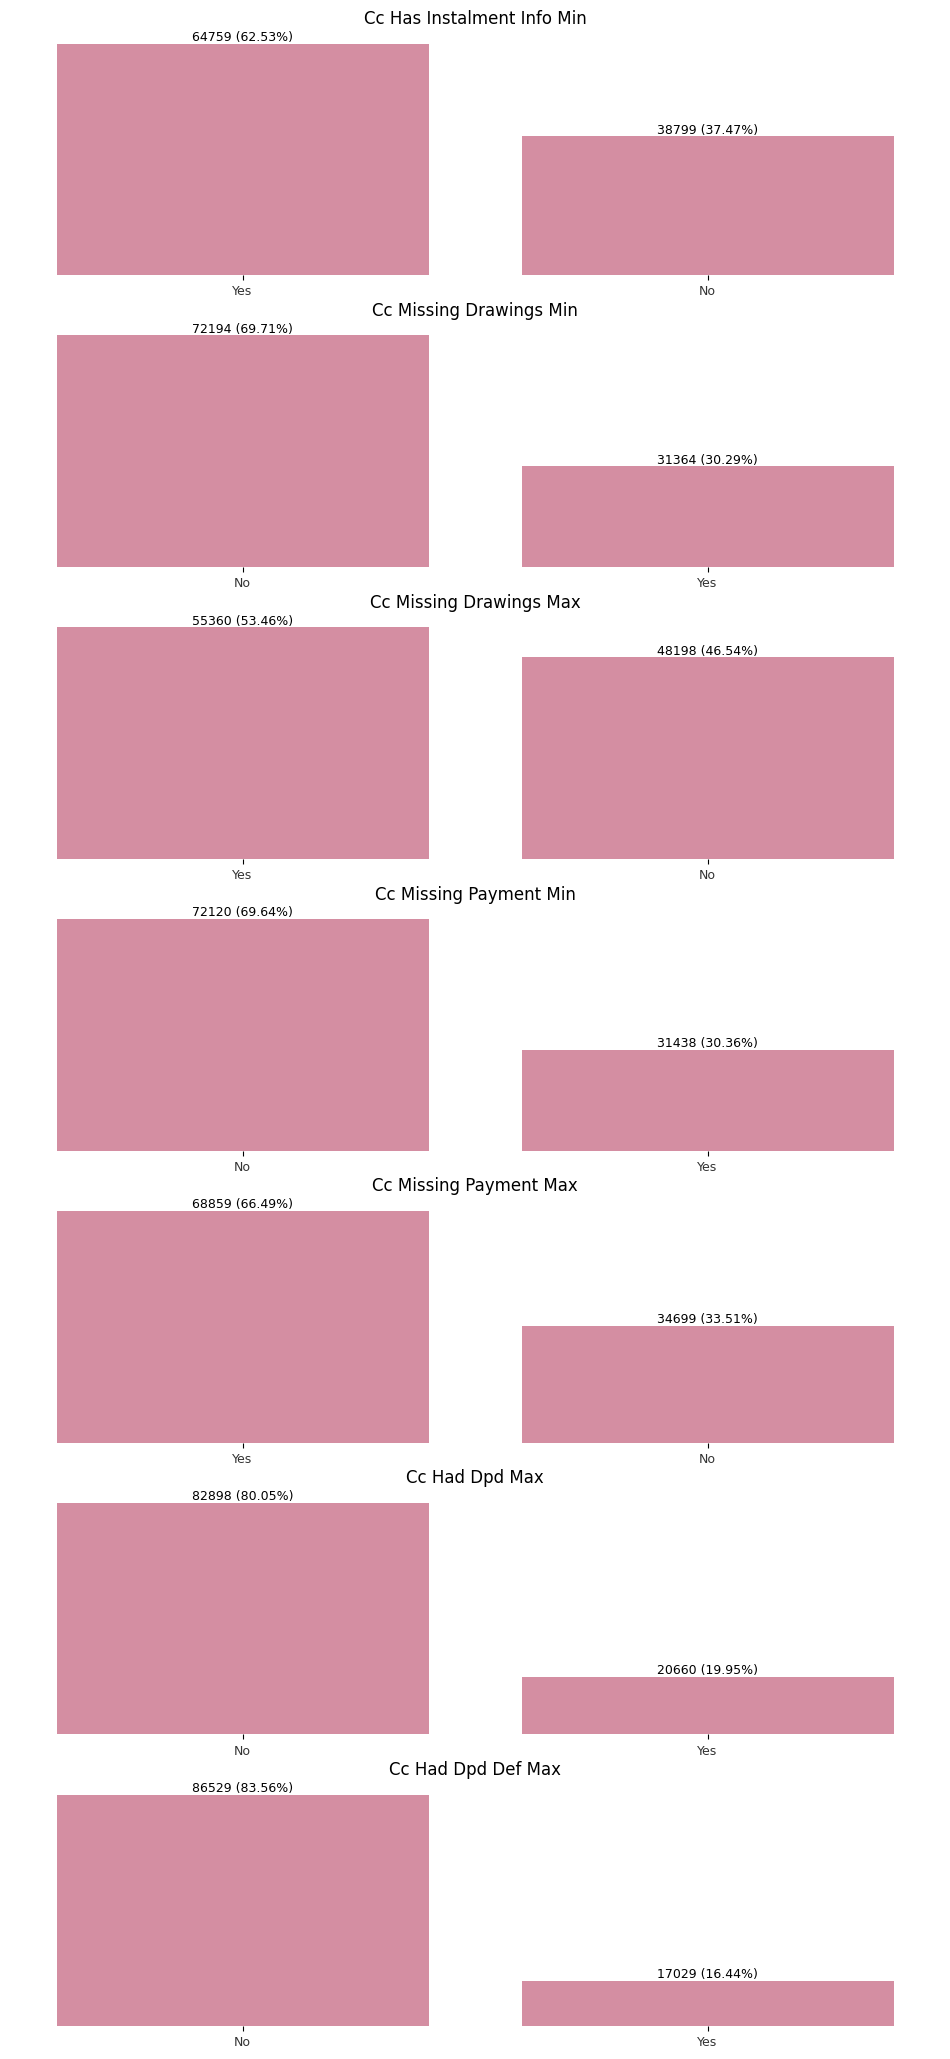

In [124]:
fig, axs = plt.subplots(len(bi_f), 1, figsize=(12, (3.7 * len(bi_f))))

i = 0
for item in bi_f:
    temp = cc_bal_agg[item].value_counts()
    title = item.replace("_", " ").title()
    ax1 = bar_plot_f_perc(temp, title, color='#e0829d', ax=axs[i])

    ind = temp.index
    if ind[0] == 0 and ind[1] == 1 and len(ind) == 2:
        ax1.set_xticklabels(['No', 'Yes'])
    if ind[0] == 1 and ind[1] == 0 and len(ind) == 2:
        ax1.set_xticklabels(['Yes', 'No'])

    i += 1

More than half of clients had instalment info (~62%). Around 66% had missed a payment. About 20% of clients had DPD.

### Outliers

In [125]:
selected = cc_bal_agg[num_f]
outliers = outlier_f(selected)
outliers.count()

CC_MONTHS_BALANCE_MIN                     0
CC_MONTHS_BALANCE_MEAN                    0
CC_AMT_BALANCE_MEAN                    7316
CC_AMT_CREDIT_LIMIT_ACTUAL_MEAN        6968
CC_AMT_DRAWINGS_ATM_CURRENT_MEAN       5659
CC_AMT_DRAWINGS_CURRENT_MEAN           7784
CC_AMT_DRAWINGS_OTHER_CURRENT_MEAN     6501
CC_AMT_DRAWINGS_POS_CURRENT_MEAN       8422
CC_AMT_INST_MIN_REGULARITY_MEAN        6516
CC_AMT_PAYMENT_CURRENT_MEAN            5477
CC_AMT_PAYMENT_TOTAL_CURRENT_MEAN      8787
CC_AMT_RECEIVABLE_PRINCIPAL_MEAN       7402
CC_AMT_RECIVABLE_MEAN                  7358
CC_AMT_TOTAL_RECEIVABLE_MEAN           7355
CC_CNT_DRAWINGS_ATM_CURRENT_MEAN       5284
CC_CNT_DRAWINGS_CURRENT_MEAN          13665
CC_CNT_DRAWINGS_OTHER_CURRENT_MEAN     6519
CC_CNT_DRAWINGS_POS_CURRENT_MEAN      10411
CC_CNT_INSTALMENT_MATURE_CUM_MEAN      7461
CC_SK_DPD_MEAN                        20660
CC_SK_DPD_DEF_MEAN                    17029
CC_NO_ACTIVITY_MONTH_SUM              12074
CC_HAS_INSTALMENT_INFO_SUM      

Removing outliers will be tested during modeling.

# Previous Application

## Checking for Nulls and Duplicates

### Duplicates

In [126]:
previous_application.columns.duplicated().any()

np.False_

In [127]:
previous_application.duplicated().any()

np.False_

### Missing Values

In [128]:
result = previous_application.isnull().sum()
rows_nr = previous_application.shape[0]
for item in previous_application.columns:
    missing_nr = result[item]
    if missing_nr > 0:
        missing_perc = count_percentage(missing_nr, rows_nr, round_value=4)
        print(f'The percentage of missing {item} values is {missing_perc}%.')

The percentage of missing AMT_ANNUITY values is 22.2867%.
The percentage of missing AMT_CREDIT values is 0.0001%.
The percentage of missing AMT_DOWN_PAYMENT values is 53.6365%.
The percentage of missing AMT_GOODS_PRICE values is 23.0818%.
The percentage of missing RATE_DOWN_PAYMENT values is 53.6365%.
The percentage of missing RATE_INTEREST_PRIMARY values is 99.6437%.
The percentage of missing RATE_INTEREST_PRIVILEGED values is 99.6437%.
The percentage of missing NAME_TYPE_SUITE values is 49.1198%.
The percentage of missing CNT_PAYMENT values is 22.2864%.
The percentage of missing PRODUCT_COMBINATION values is 0.0207%.
The percentage of missing DAYS_FIRST_DRAWING values is 40.2981%.
The percentage of missing DAYS_FIRST_DUE values is 40.2981%.
The percentage of missing DAYS_LAST_DUE_1ST_VERSION values is 40.2981%.
The percentage of missing DAYS_LAST_DUE values is 40.2981%.
The percentage of missing DAYS_TERMINATION values is 40.2981%.
The percentage of missing NFLAG_INSURED_ON_APPROVAL 

In [129]:
result = (previous_application == 'XNA').sum()
rows_nr = previous_application.shape[0]
for item in previous_application.columns:
    missing_nr = result[item]
    if missing_nr > 0:
        missing_perc = count_percentage(missing_nr, rows_nr, round_value=4)
        print(f'The percentage of missing {item} values is {missing_perc}%.')

The percentage of missing NAME_CONTRACT_TYPE values is 0.0207%.
The percentage of missing NAME_CASH_LOAN_PURPOSE values is 40.5887%.
The percentage of missing NAME_PAYMENT_TYPE values is 37.5631%.
The percentage of missing CODE_REJECT_REASON values is 0.314%.
The percentage of missing NAME_CLIENT_TYPE values is 0.1162%.
The percentage of missing NAME_GOODS_CATEGORY values is 56.9274%.
The percentage of missing NAME_PORTFOLIO values is 22.2864%.
The percentage of missing NAME_PRODUCT_TYPE values is 63.6844%.
The percentage of missing NAME_SELLER_INDUSTRY values is 51.2342%.
The percentage of missing NAME_YIELD_GROUP values is 30.967%.


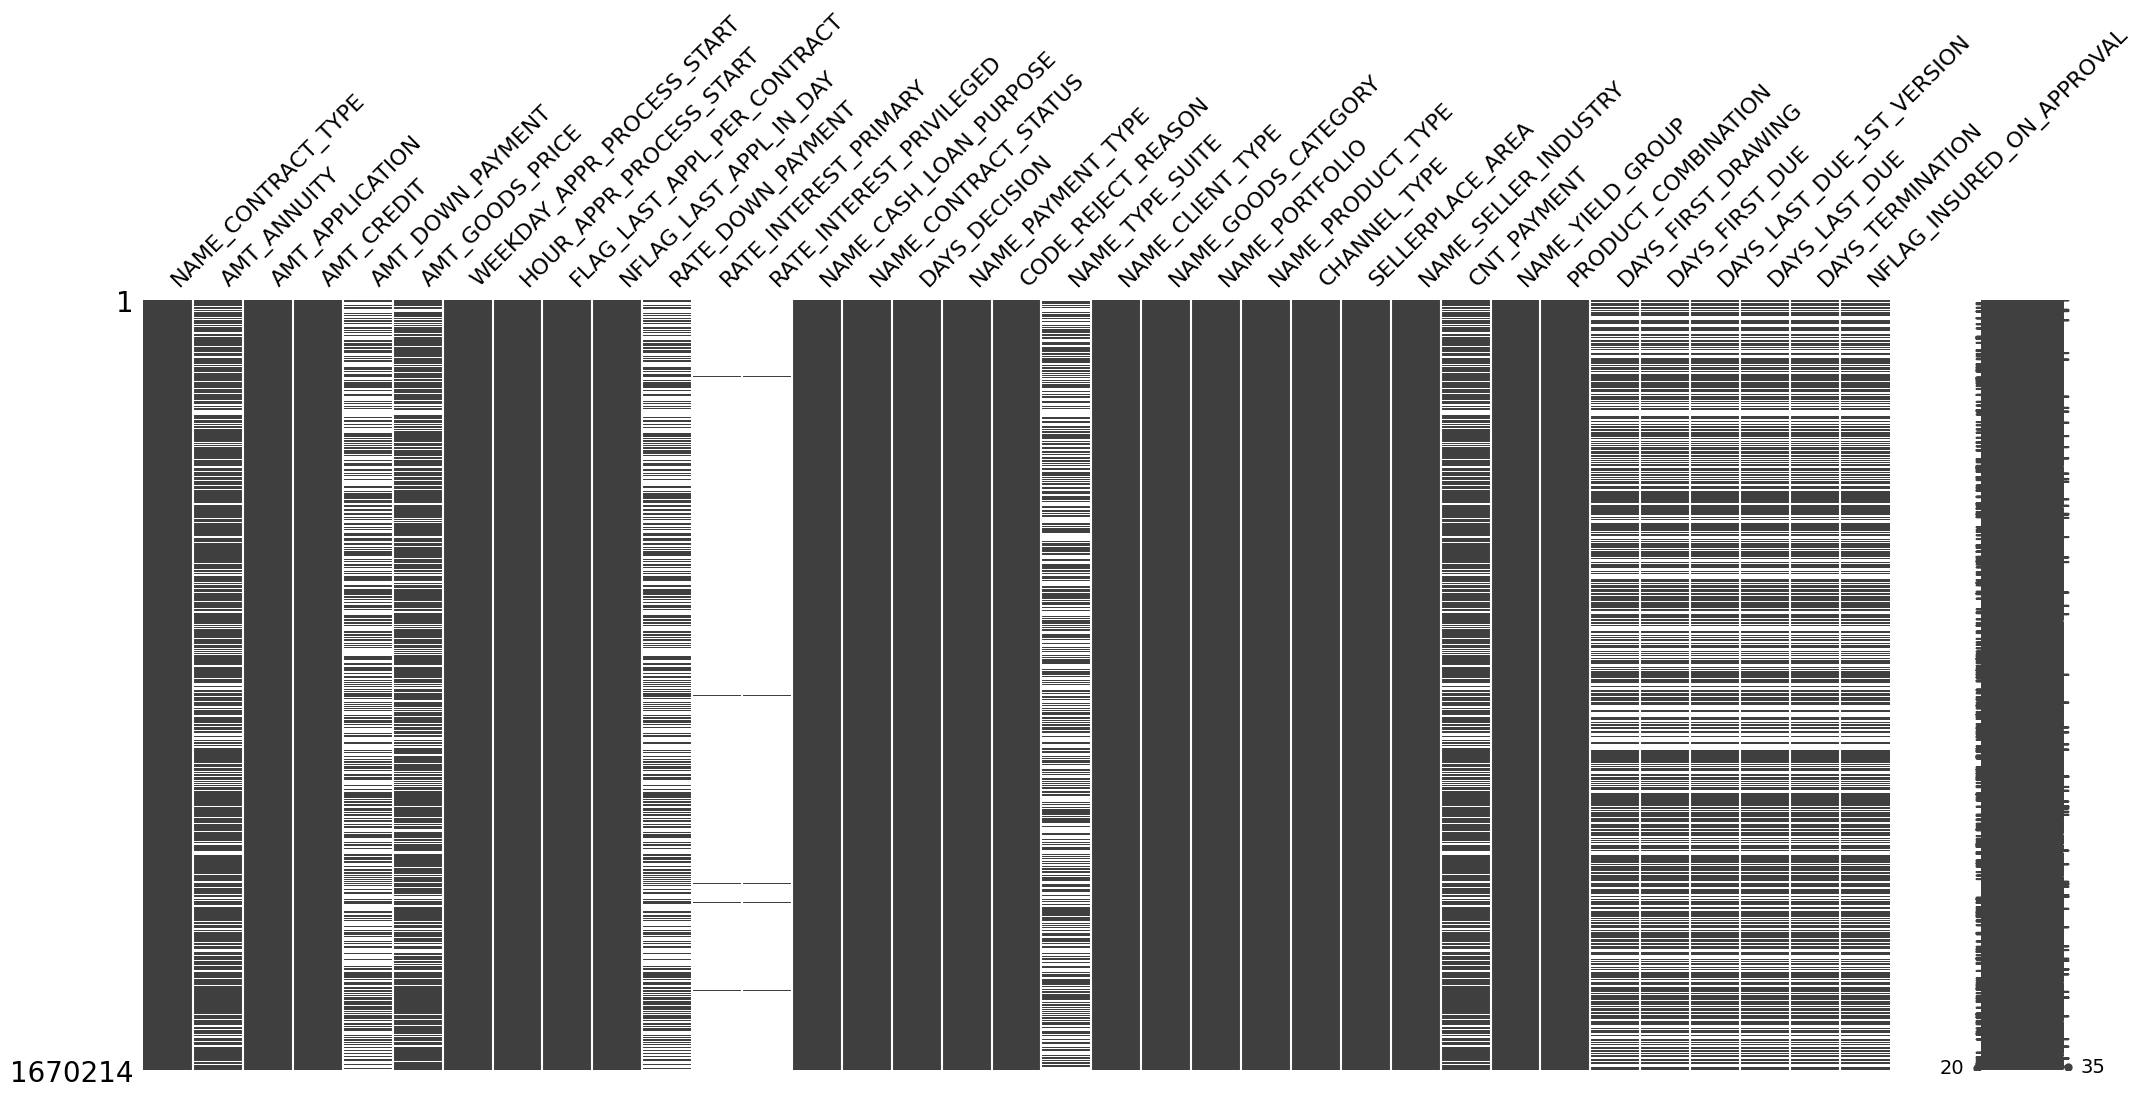

In [130]:
%matplotlib inline

msno.matrix(previous_application.iloc[:, 2:]);

In [131]:
print(previous_application['AMT_ANNUITY'].isnull().groupby(previous_application['NAME_CONTRACT_TYPE']).mean())
print(previous_application['AMT_ANNUITY'].isnull().groupby(previous_application['NAME_CONTRACT_STATUS']).mean())

NAME_CONTRACT_TYPE
Cash loans         0.382568
Consumer loans     0.051730
Revolving loans    0.249425
XNA                1.000000
Name: AMT_ANNUITY, dtype: float64
NAME_CONTRACT_STATUS
Approved        0.000008
Canceled        0.966761
Refused         0.140699
Unused offer    0.965502
Name: AMT_ANNUITY, dtype: float64


All of missing contract types (XNA) have missing annuity values.

Approved almost all approved loans have AMT_ANNUITY recorded. Canceled / Unused offer about 97% missing – annuity wasn't set, because the loan was never finalized.Refused (~14% missing) – some may have gone far enough to determine an annuity, others not.

Missing AMT_ANNUITY is mostly due to unapproved or incomplete applications.

AMT_CREDIT has 0.0001% missing, therefore will not be investigated further and missing values will be filled with median. PRODUCT_COMBINATION will not be investigated furhter, since it has only 0.0207% missing values. Same goes for other columns with low missing values: NAME_CLIENT_TYPE (0.1162%), CODE_REJECT_REASON (0.314%), NAME_CONTRACT_TYPE (0.0207%).

In [132]:
query = '''
SELECT * 
FROM previous_application
WHERE RATE_DOWN_PAYMENT IS NOT NULL and AMT_DOWN_PAYMENT IS NULL
'''

db.sql(query).df()

,SK_ID_PREV,SK_ID_CURR,NAME_CONTRACT_TYPE,AMT_ANNUITY,AMT_APPLICATION,AMT_CREDIT,AMT_DOWN_PAYMENT,AMT_GOODS_PRICE,WEEKDAY_APPR_PROCESS_START,HOUR_APPR_PROCESS_START,...,NAME_SELLER_INDUSTRY,CNT_PAYMENT,NAME_YIELD_GROUP,PRODUCT_COMBINATION,DAYS_FIRST_DRAWING,DAYS_FIRST_DUE,DAYS_LAST_DUE_1ST_VERSION,DAYS_LAST_DUE,DAYS_TERMINATION,NFLAG_INSURED_ON_APPROVAL


In [133]:
print(previous_application['AMT_DOWN_PAYMENT'].isnull().groupby(previous_application['NAME_CONTRACT_TYPE']).mean())
print(previous_application['AMT_DOWN_PAYMENT'].isnull().groupby(previous_application['NAME_CONTRACT_STATUS']).mean())
print(
    previous_application['AMT_DOWN_PAYMENT']
    .isnull()
    .groupby(previous_application['FLAG_LAST_APPL_PER_CONTRACT'])
    .mean()
)
print(previous_application['AMT_DOWN_PAYMENT'].isnull().groupby(previous_application['NFLAG_LAST_APPL_IN_DAY']).mean())

NAME_CONTRACT_TYPE
Cash loans         0.935879
Consumer loans     0.007008
Revolving loans    0.987601
XNA                1.000000
Name: AMT_DOWN_PAYMENT, dtype: float64
NAME_CONTRACT_STATUS
Approved        0.361118
Canceled        0.997967
Refused         0.699489
Unused offer    0.092374
Name: AMT_DOWN_PAYMENT, dtype: float64
FLAG_LAST_APPL_PER_CONTRACT
N    0.999882
Y    0.534001
Name: AMT_DOWN_PAYMENT, dtype: float64
NFLAG_LAST_APPL_IN_DAY
0    0.952542
1    0.534889
Name: AMT_DOWN_PAYMENT, dtype: float64


Down payments are almost never recorded for Cash or Revolving loans, likely because those product types don’t typically require a down payment.

Approved applications still have a substantial portion missing (36%), most likely for cash/revolving loans. Canceled (99.8%)/Refused (69.9%) have very high amount of missing values, as the loan might not have progressed to the point of calculating a down payment. Unused offers seem to have more complete down payment data (only 9% missing), which could mean the offer was prepared fully but not taken.

If the application is not the last one for that contract, the down payment is almost always missing. When it’s the last recorded application, there's a better chance the down payment was recorded. 

In [134]:
print(previous_application['AMT_GOODS_PRICE'].isnull().groupby(previous_application['NAME_GOODS_CATEGORY']).mean())
print(previous_application['AMT_GOODS_PRICE'].isnull().groupby(previous_application['NAME_CONTRACT_STATUS']).mean())
print(previous_application['AMT_GOODS_PRICE'].isnull().groupby(previous_application['NAME_CASH_LOAN_PURPOSE']).mean())

NAME_GOODS_CATEGORY
Additional Service          0.00000
Animals                     0.00000
Audio/Video                 0.00000
Auto Accessories            0.00000
Clothing and Accessories    0.00000
Computers                   0.00000
Construction Materials      0.00000
Consumer Electronics        0.00000
Direct Sales                0.00000
Education                   0.00000
Fitness                     0.00000
Furniture                   0.00000
Gardening                   0.00000
Homewares                   0.00000
House Construction          0.00000
Insurance                   0.00000
Jewelry                     0.00000
Medical Supplies            0.00000
Medicine                    0.00000
Mobile                      0.00000
Office Appliances           0.00000
Other                       0.00000
Photo / Cinema Equipment    0.00000
Sport and Leisure           0.00000
Tourism                     0.00000
Vehicles                    0.00000
Weapon                      0.00000
XNA     

Missing values in AMT_GOODS_PRICE are almost entirely due to unclear or incomplete applications:
- Contract Status is Canceled or Refused
- Loan Purpose or Goods Category is XNA/XAP

In [136]:
query = '''
SELECT * 
FROM previous_application
WHERE RATE_INTEREST_PRIVILEGED IS NOT NULL and RATE_INTEREST_PRIMARY IS NULL
'''

db.sql(query).df()

,SK_ID_PREV,SK_ID_CURR,NAME_CONTRACT_TYPE,AMT_ANNUITY,AMT_APPLICATION,AMT_CREDIT,AMT_DOWN_PAYMENT,AMT_GOODS_PRICE,WEEKDAY_APPR_PROCESS_START,HOUR_APPR_PROCESS_START,...,CNT_PAYMENT,NAME_YIELD_GROUP,PRODUCT_COMBINATION,DAYS_FIRST_DRAWING,DAYS_FIRST_DUE,DAYS_LAST_DUE_1ST_VERSION,DAYS_LAST_DUE,DAYS_TERMINATION,NFLAG_INSURED_ON_APPROVAL,MISSING_AMT_GOODS_PRICE


RATE_INTEREST_PRIVILEGED and RATE_INTEREST_PRIMARY values are missing together. There is a lot of values missing in these columns.

In [137]:
previous_application['HAS_INTEREST_INFO'] = previous_application['RATE_INTEREST_PRIMARY'].notnull().astype(int)

In [138]:
print(previous_application['NAME_TYPE_SUITE'].isnull().groupby(previous_application['NAME_CONTRACT_TYPE']).mean())
print(previous_application['NAME_TYPE_SUITE'].isnull().groupby(previous_application['NAME_CONTRACT_STATUS']).mean())
print(previous_application['NAME_TYPE_SUITE'].isnull().groupby(previous_application['NAME_PORTFOLIO']).mean())

NAME_CONTRACT_TYPE
Cash loans         0.563771
Consumer loans     0.358356
Revolving loans    0.710867
XNA                1.000000
Name: NAME_TYPE_SUITE, dtype: float64
NAME_CONTRACT_STATUS
Approved        0.359231
Canceled        0.968450
Refused         0.415532
Unused offer    0.788168
Name: NAME_TYPE_SUITE, dtype: float64
NAME_PORTFOLIO
Cards    0.614946
Cars     1.000000
Cash     0.296215
POS      0.336076
XNA      0.972162
Name: NAME_TYPE_SUITE, dtype: float64


Missing values indicates that this information was not collected or not required in some applications. When loans are approved, the info is usually more complete. Canceled/Unused offers often lack full documentation. For loans involving cars it wasn't collected and for loans involving cards it was rarely captured.

In [139]:
previous_application['NAME_TYPE_SUITE'] = previous_application['NAME_TYPE_SUITE'].fillna('Unknown')

In [140]:
print(previous_application['CNT_PAYMENT'].isnull().groupby(previous_application['NAME_CONTRACT_TYPE']).mean())
print(previous_application['CNT_PAYMENT'].isnull().groupby(previous_application['NAME_CONTRACT_STATUS']).mean())
print(previous_application['CNT_PAYMENT'].isnull().groupby(previous_application['NAME_PORTFOLIO']).mean())

NAME_CONTRACT_TYPE
Cash loans         0.382568
Consumer loans     0.051725
Revolving loans    0.249420
XNA                1.000000
Name: CNT_PAYMENT, dtype: float64
NAME_CONTRACT_STATUS
Approved        0.000004
Canceled        0.966761
Refused         0.140695
Unused offer    0.965502
Name: CNT_PAYMENT, dtype: float64
NAME_PORTFOLIO
Cards    0.0
Cars     0.0
Cash     0.0
POS      0.0
XNA      1.0
Name: CNT_PAYMENT, dtype: float64


Approved loans almost always have CNT_PAYMENT filled. Canceled / unused loans rarely have this info — they were likely withdrawn before reaching the installment phase. For known portfolios, no missing values. All missing CNT_PAYMENT records belong to XNA portfolio

In [142]:
cols = [
    'DAYS_FIRST_DRAWING',
    'DAYS_FIRST_DUE',
    'DAYS_LAST_DUE_1ST_VERSION',
    'DAYS_LAST_DUE',
    'DAYS_TERMINATION',
    'NFLAG_INSURED_ON_APPROVAL',
]

joint_missing = previous_application[cols].isnull().all(axis=1).sum()
any_missing = previous_application[cols].isnull().any(axis=1).sum()

print(f"Rows where ALL are missing: {joint_missing}")
print(f"Rows where ANY are missing: {any_missing}")
print(f"Same? {joint_missing == any_missing}")

Rows where ALL are missing: 673065
Rows where ANY are missing: 673065
Same? True


In [143]:
print(previous_application['DAYS_FIRST_DRAWING'].isnull().groupby(previous_application['NAME_CONTRACT_TYPE']).mean())
print(previous_application['DAYS_FIRST_DRAWING'].isnull().groupby(previous_application['NAME_CONTRACT_STATUS']).mean())
print(
    previous_application['DAYS_FIRST_DRAWING']
    .isnull()
    .groupby(previous_application['FLAG_LAST_APPL_PER_CONTRACT'])
    .mean()
)
print(previous_application['DAYS_FIRST_DRAWING'].isnull().groupby(previous_application['CODE_REJECT_REASON']).mean())

NAME_CONTRACT_TYPE
Cash loans         0.613692
Consumer loans     0.157096
Revolving loans    0.514615
XNA                1.000000
Name: DAYS_FIRST_DRAWING, dtype: float64
NAME_CONTRACT_STATUS
Approved        0.038226
Canceled        1.000000
Refused         1.000000
Unused offer    1.000000
Name: DAYS_FIRST_DRAWING, dtype: float64
FLAG_LAST_APPL_PER_CONTRACT
N    1.000000
Y    0.399936
Name: DAYS_FIRST_DRAWING, dtype: float64
CODE_REJECT_REASON
CLIENT    1.000000
HC        1.000000
LIMIT     1.000000
SCO       1.000000
SCOFR     1.000000
SYSTEM    1.000000
VERIF     1.000000
XAP       0.263065
XNA       0.998474
Name: DAYS_FIRST_DRAWING, dtype: float64


Only Approved applications have non-missing DAYS_FIRST_DRAWING. Missing values for all other statuses make perfect sense — no loan was drawn if it wasn’t approved. Only partially valid or borderline approvals like XAP may contain real DAYS_FIRST_DRAWING. The rest never led to money being drawn.

In [145]:
print(
    (previous_application.NAME_CASH_LOAN_PURPOSE == 'XNA').groupby(previous_application['NAME_CONTRACT_STATUS']).mean()
)
print((previous_application.NAME_CASH_LOAN_PURPOSE == 'XNA').groupby(previous_application['NAME_CONTRACT_TYPE']).mean())

NAME_CONTRACT_STATUS
Approved        0.275475
Canceled        0.843933
Refused         0.430270
Unused offer    0.010932
Name: NAME_CASH_LOAN_PURPOSE, dtype: float64
NAME_CONTRACT_TYPE
Cash loans         0.906849
Consumer loans     0.000000
Revolving loans    0.000000
XNA                0.000000
Name: NAME_CASH_LOAN_PURPOSE, dtype: float64


Canceled and refused applications are more likely to have 'XNA' purposes — possibly indicating incomplete or low-quality applications. Only cash loans and majority of them have 'XNA' purposes — indicating that cash loans often lack a clearly specified loan purpose.

In [146]:
print((previous_application.NAME_PAYMENT_TYPE == 'XNA').groupby(previous_application['NAME_CONTRACT_TYPE']).mean())
print((previous_application.NAME_PAYMENT_TYPE == 'XNA').groupby(previous_application['NAME_CONTRACT_STATUS']).mean())

NAME_CONTRACT_TYPE
Cash loans         0.459257
Consumer loans     0.124192
Revolving loans    1.000000
XNA                1.000000
Name: NAME_PAYMENT_TYPE, dtype: float64
NAME_CONTRACT_STATUS
Approved        0.204293
Canceled        0.989741
Refused         0.350866
Unused offer    0.019443
Name: NAME_PAYMENT_TYPE, dtype: float64


Payment type is missing for revolving loans. Also it is missing for majority of canceled contracts. 

In [147]:
print((previous_application.NAME_GOODS_CATEGORY == 'XNA').groupby(previous_application['NAME_CONTRACT_TYPE']).mean())
print((previous_application.NAME_GOODS_CATEGORY == 'XNA').groupby(previous_application['NAME_CONTRACT_STATUS']).mean())
print((previous_application.NAME_GOODS_CATEGORY == 'XNA').groupby(previous_application['NAME_PORTFOLIO']).mean())

NAME_CONTRACT_TYPE
Cash loans         1.000000
Consumer loans     0.014033
Revolving loans    0.997484
XNA                1.000000
Name: NAME_GOODS_CATEGORY, dtype: float64
NAME_CONTRACT_STATUS
Approved        0.395850
Canceled        0.999330
Refused         0.769883
Unused offer    0.019065
Name: NAME_GOODS_CATEGORY, dtype: float64
NAME_PORTFOLIO
Cards    0.996648
Cars     1.000000
Cash     1.000000
POS      0.012204
XNA      0.902370
Name: NAME_GOODS_CATEGORY, dtype: float64


It seems that goods category was not collected for cash loans and majority of revolving loans. Implying goods category is likely not applicable for these types. POS (Point of Sale) loans are associated with actual goods and have goods categories. All other portfolios (Cards, Cars, Cash) have  no category info, probably because they aren’t for specific products. No specific product is linked to the loan when the application is incomplete (e.g., canceled/refused).

In [148]:
print((previous_application.NAME_PORTFOLIO == 'XNA').groupby(previous_application['NAME_CONTRACT_STATUS']).mean())
print((previous_application.NAME_PORTFOLIO == 'XNA').groupby(previous_application['CNT_PAYMENT_MISSING']).mean())

NAME_CONTRACT_STATUS
Approved        0.000004
Canceled        0.966761
Refused         0.140695
Unused offer    0.965502
Name: NAME_PORTFOLIO, dtype: float64
CNT_PAYMENT_MISSING
0    0.0
1    1.0
Name: NAME_PORTFOLIO, dtype: float64


The missingness is clearly linked to canceled and unused applications. If payment info is missing, so is portfolio. This suggests that 'XNA' here likely represents incomplete or invalid applications, rather than true unknowns.

In [149]:
print((previous_application.NAME_PRODUCT_TYPE == 'XNA').groupby(previous_application['NAME_CONTRACT_TYPE']).mean())
print((previous_application.NAME_PRODUCT_TYPE == 'XNA').groupby(previous_application['NAME_CONTRACT_STATUS']).mean())
print((previous_application.NAME_PRODUCT_TYPE == 'XNA').groupby(previous_application['NAME_PORTFOLIO']).mean())

NAME_CONTRACT_TYPE
Cash loans         0.382568
Consumer loans     1.000000
Revolving loans    0.249420
XNA                1.000000
Name: NAME_PRODUCT_TYPE, dtype: float64
NAME_CONTRACT_STATUS
Approved        0.604249
Canceled        0.967451
Refused         0.360313
Unused offer    0.999924
Name: NAME_PRODUCT_TYPE, dtype: float64
NAME_PORTFOLIO
Cards    0.0
Cars     1.0
Cash     0.0
POS      1.0
XNA      1.0
Name: NAME_PRODUCT_TYPE, dtype: float64


Cards and Cash portfolios always have valid product type, Cars, POS, and XNA portfolios always missing it. 'NAME_PRODUCT_TYPE' is connected to certain portfolios and not applicable or recorded for others.

In [150]:
print((previous_application.NAME_SELLER_INDUSTRY == 'XNA').groupby(previous_application['NAME_CONTRACT_STATUS']).mean())
print((previous_application.NAME_SELLER_INDUSTRY == 'XNA').groupby(previous_application['NAME_CONTRACT_TYPE']).mean())
print(
    (previous_application.NAME_SELLER_INDUSTRY == 'XNA').groupby(previous_application['NAME_CASH_LOAN_PURPOSE']).mean()
)

NAME_CONTRACT_STATUS
Approved        0.337547
Canceled        0.992229
Refused         0.658423
Unused offer    0.019216
Name: NAME_SELLER_INDUSTRY, dtype: float64
NAME_CONTRACT_TYPE
Cash loans         0.935322
Consumer loans     0.002718
Revolving loans    0.799999
XNA                0.011561
Name: NAME_SELLER_INDUSTRY, dtype: float64
NAME_CASH_LOAN_PURPOSE
Building a house or an annex        0.944300
Business development                0.910798
Buying a garage                     0.933824
Buying a holiday home / land        0.969981
Buying a home                       0.969942
Buying a new car                    0.981225
Buying a used car                   0.969529
Car repairs                         0.894605
Education                           0.926891
Everyday expenses                   0.881623
Furniture                           0.883845
Gasification / water supply         0.876667
Hobby                               0.945455
Journey                             0.962066
Medicine 

Approved loans have a significant number with 'XNA', which suggests some loans genuinely lack seller industry data. Canceled/Refused contracts are mostly missing this information. Cash and revolving loans mostly lack it — most likely because seller involvement isn't applicable.

By NAME_CASH_LOAN_PURPOSE Most rows (excluding XAP) have very high 'XNA' rates. These high values imply that seller involvement is either unknown or not applicable in most cases.

In [151]:
print((previous_application.NAME_YIELD_GROUP == 'XNA').groupby(previous_application['NAME_CONTRACT_STATUS']).mean())
print((previous_application.NAME_YIELD_GROUP == 'XNA').groupby(previous_application['NAME_CONTRACT_TYPE']).mean())
print((previous_application.NAME_YIELD_GROUP == 'XNA').groupby(previous_application['NAME_PORTFOLIO']).mean())

NAME_CONTRACT_STATUS
Approved        0.094306
Canceled        0.968257
Refused         0.301488
Unused offer    0.965577
Name: NAME_YIELD_GROUP, dtype: float64
NAME_CONTRACT_TYPE
Cash loans         0.382568
Consumer loans     0.051725
Revolving loans    1.000000
XNA                1.000000
Name: NAME_YIELD_GROUP, dtype: float64
NAME_PORTFOLIO
Cards    1.0
Cars     0.0
Cash     0.0
POS      0.0
XNA      1.0
Name: NAME_YIELD_GROUP, dtype: float64


NAME_YIELD_GROUP missing values again tied to canceled and unused offers mostly. Also it is missing for all revolting loans and a significant amount of cash loans. It is tied to certain portfolios - it is always misisng for Cards portfolio and missing portfolio values.

## Exploring Data

### Features

In [152]:
query = '''
SELECT * 
FROM HomeCredit_columns_description
WHERE "Table" = 'previous_application.csv'
'''

info = db.sql(query).df()
info

,Table,Row,Description,Special
0,previous_application.csv,SK_ID_PREV,ID of previous credit in Home credit related t...,hashed
1,previous_application.csv,SK_ID_CURR,ID of loan in our sample,hashed
2,previous_application.csv,NAME_CONTRACT_TYPE,"Contract product type (Cash loan, consumer loa...",None
3,previous_application.csv,AMT_ANNUITY,Annuity of previous application,None
4,previous_application.csv,AMT_APPLICATION,For how much credit did client ask on the prev...,None
5,previous_application.csv,AMT_CREDIT,Final credit amount on the previous applicatio...,None
6,previous_application.csv,AMT_DOWN_PAYMENT,Down payment on the previous application,None
7,previous_application.csv,AMT_GOODS_PRICE,Goods price of good that client asked for (if ...,None
8,previous_application.csv,WEEKDAY_APPR_PROCESS_START,On which day of the week did the client apply ...,None
9,previous_application.csv,HOUR_APPR_PROCESS_START,Approximately at what day hour did the client ...,rounded


In [153]:
previous_application.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1670214 entries, 0 to 1670213
Data columns (total 41 columns):
 #   Column                       Non-Null Count    Dtype  
---  ------                       --------------    -----  
 0   SK_ID_PREV                   1670214 non-null  int64  
 1   SK_ID_CURR                   1670214 non-null  int64  
 2   NAME_CONTRACT_TYPE           1670214 non-null  object 
 3   AMT_ANNUITY                  1297979 non-null  float64
 4   AMT_APPLICATION              1670214 non-null  float64
 5   AMT_CREDIT                   1670213 non-null  float64
 6   AMT_DOWN_PAYMENT             774370 non-null   float64
 7   AMT_GOODS_PRICE              1284699 non-null  float64
 8   WEEKDAY_APPR_PROCESS_START   1670214 non-null  object 
 9   HOUR_APPR_PROCESS_START      1670214 non-null  int64  
 10  FLAG_LAST_APPL_PER_CONTRACT  1670214 non-null  object 
 11  NFLAG_LAST_APPL_IN_DAY       1670214 non-null  int64  
 12  RATE_DOWN_PAYMENT            774370 non-nu

In [154]:
previous_application_noid = previous_application.iloc[:, 2:]
previous_application_noid.describe()

,AMT_ANNUITY,AMT_APPLICATION,AMT_CREDIT,AMT_DOWN_PAYMENT,AMT_GOODS_PRICE,HOUR_APPR_PROCESS_START,NFLAG_LAST_APPL_IN_DAY,RATE_DOWN_PAYMENT,RATE_INTEREST_PRIMARY,RATE_INTEREST_PRIVILEGED,...,DAYS_FIRST_DRAWING,DAYS_FIRST_DUE,DAYS_LAST_DUE_1ST_VERSION,DAYS_LAST_DUE,DAYS_TERMINATION,NFLAG_INSURED_ON_APPROVAL,MISSING_AMT_GOODS_PRICE,HAS_INTEREST_INFO,CNT_PAYMENT_MISSING,DAYS_FIRST_DRAWING_MISSING
count,1.297979e+06,1.670214e+06,1.670213e+06,7.743700e+05,1.284699e+06,1.670214e+06,1.670214e+06,774370.000000,5951.000000,5951.000000,...,997149.000000,997149.000000,997149.000000,997149.000000,997149.000000,997149.000000,1.670214e+06,1.670214e+06,1.670214e+06,1.670214e+06
mean,1.595512e+04,1.752339e+05,1.961140e+05,6.697402e+03,2.278473e+05,1.248418e+01,9.964675e-01,0.079637,0.188357,0.773503,...,342209.855039,13826.269337,33767.774054,76582.403064,81992.343838,0.332570,2.308177e-01,3.563016e-03,2.228637e-01,4.029813e-01
std,1.478214e+04,2.927798e+05,3.185746e+05,2.092150e+04,3.153966e+05,3.334028e+00,5.932963e-02,0.107823,0.087671,0.100879,...,88916.115833,72444.869708,106857.034789,149647.415123,153303.516729,0.471134,4.213562e-01,5.958459e-02,4.161677e-01,4.904972e-01
min,0.000000e+00,0.000000e+00,0.000000e+00,-9.000000e-01,0.000000e+00,0.000000e+00,0.000000e+00,-0.000015,0.034781,0.373150,...,-2922.000000,-2892.000000,-2801.000000,-2889.000000,-2874.000000,0.000000,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00
25%,6.321780e+03,1.872000e+04,2.416050e+04,0.000000e+00,5.084100e+04,1.000000e+01,1.000000e+00,0.000000,0.160716,0.715645,...,365243.000000,-1628.000000,-1242.000000,-1314.000000,-1270.000000,0.000000,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00
50%,1.125000e+04,7.104600e+04,8.054100e+04,1.638000e+03,1.123200e+05,1.200000e+01,1.000000e+00,0.051605,0.189122,0.835095,...,365243.000000,-831.000000,-361.000000,-537.000000,-499.000000,0.000000,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00
75%,2.065842e+04,1.803600e+05,2.164185e+05,7.740000e+03,2.340000e+05,1.500000e+01,1.000000e+00,0.108909,0.193330,0.852537,...,365243.000000,-411.000000,129.000000,-74.000000,-44.000000,1.000000,0.000000e+00,0.000000e+00,0.000000e+00,1.000000e+00
max,4.180581e+05,6.905160e+06,6.905160e+06,3.060045e+06,6.905160e+06,2.300000e+01,1.000000e+00,1.000000,1.000000,1.000000,...,365243.000000,365243.000000,365243.000000,365243.000000,365243.000000,1.000000,1.000000e+00,1.000000e+00,1.000000e+00,1.000000e+00


In [ ]:
previous_application['DAYS_FIRST_DRAWING'].replace(365243, np.nan, inplace=True)
previous_application['DAYS_FIRST_DUE'].replace(365243, np.nan, inplace=True)
previous_application['DAYS_LAST_DUE_1ST_VERSION'].replace(365243, np.nan, inplace=True)
previous_application['DAYS_LAST_DUE'].replace(365243, np.nan, inplace=True)
previous_application['DAYS_TERMINATION'].replace(365243, np.nan, inplace=True)

In [155]:
for i in previous_application.columns:
    print(i, "column's total unique values are:", previous_application[i].nunique())

SK_ID_PREV column's total unique values are: 1670214
SK_ID_CURR column's total unique values are: 338857
NAME_CONTRACT_TYPE column's total unique values are: 4
AMT_ANNUITY column's total unique values are: 357959
AMT_APPLICATION column's total unique values are: 93885
AMT_CREDIT column's total unique values are: 86803
AMT_DOWN_PAYMENT column's total unique values are: 29278
AMT_GOODS_PRICE column's total unique values are: 93885
WEEKDAY_APPR_PROCESS_START column's total unique values are: 7
HOUR_APPR_PROCESS_START column's total unique values are: 24
FLAG_LAST_APPL_PER_CONTRACT column's total unique values are: 2
NFLAG_LAST_APPL_IN_DAY column's total unique values are: 2
RATE_DOWN_PAYMENT column's total unique values are: 207033
RATE_INTEREST_PRIMARY column's total unique values are: 148
RATE_INTEREST_PRIVILEGED column's total unique values are: 25
NAME_CASH_LOAN_PURPOSE column's total unique values are: 25
NAME_CONTRACT_STATUS column's total unique values are: 4
DAYS_DECISION column's

In [156]:
features_cat = previous_application_noid.select_dtypes(include=['object']).columns

for i in features_cat:
    print(i, "column's unique values are:", previous_application_noid[i].unique())

NAME_CONTRACT_TYPE column's unique values are: ['Consumer loans' 'Cash loans' 'Revolving loans' 'XNA']
WEEKDAY_APPR_PROCESS_START column's unique values are: ['SATURDAY' 'THURSDAY' 'TUESDAY' 'MONDAY' 'FRIDAY' 'SUNDAY' 'WEDNESDAY']
FLAG_LAST_APPL_PER_CONTRACT column's unique values are: ['Y' 'N']
NAME_CASH_LOAN_PURPOSE column's unique values are: ['XAP' 'XNA' 'Repairs' 'Everyday expenses' 'Car repairs'
 'Building a house or an annex' 'Other' 'Journey'
 'Purchase of electronic equipment' 'Medicine' 'Payments on other loans'
 'Urgent needs' 'Buying a used car' 'Buying a new car'
 'Buying a holiday home / land' 'Education' 'Buying a home' 'Furniture'
 'Buying a garage' 'Business development' 'Wedding / gift / holiday'
 'Hobby' 'Gasification / water supply' 'Refusal to name the goal'
 'Money for a third person']
NAME_CONTRACT_STATUS column's unique values are: ['Approved' 'Refused' 'Canceled' 'Unused offer']
NAME_PAYMENT_TYPE column's unique values are: ['Cash through the bank' 'XNA' 'Non-c

In [157]:
previous_application['FLAG_LAST_APPL_PER_CONTRACT'] = previous_application['FLAG_LAST_APPL_PER_CONTRACT'].map(
    {'Y': 1, 'N': 0}
)

###  Charts of Categorical Features 

In [158]:
num_bi_f = previous_application.iloc[:, 1:].select_dtypes(include=['float', 'int']).columns
num_f = []
bi_f = []

for item in num_bi_f:
    if len(previous_application[item].dropna().unique()) > 2:
        num_f.append(item)
    else:
        bi_f.append(item)

short_cat = []
long_cat = []
for item in features_cat:
    if previous_application[item].nunique() > 7:
        long_cat.append(item)
    else:
        short_cat.append(item)
short_cat.remove('FLAG_LAST_APPL_PER_CONTRACT')

catbi_f = []
catbi_f.extend(short_cat)
catbi_f.extend(bi_f)

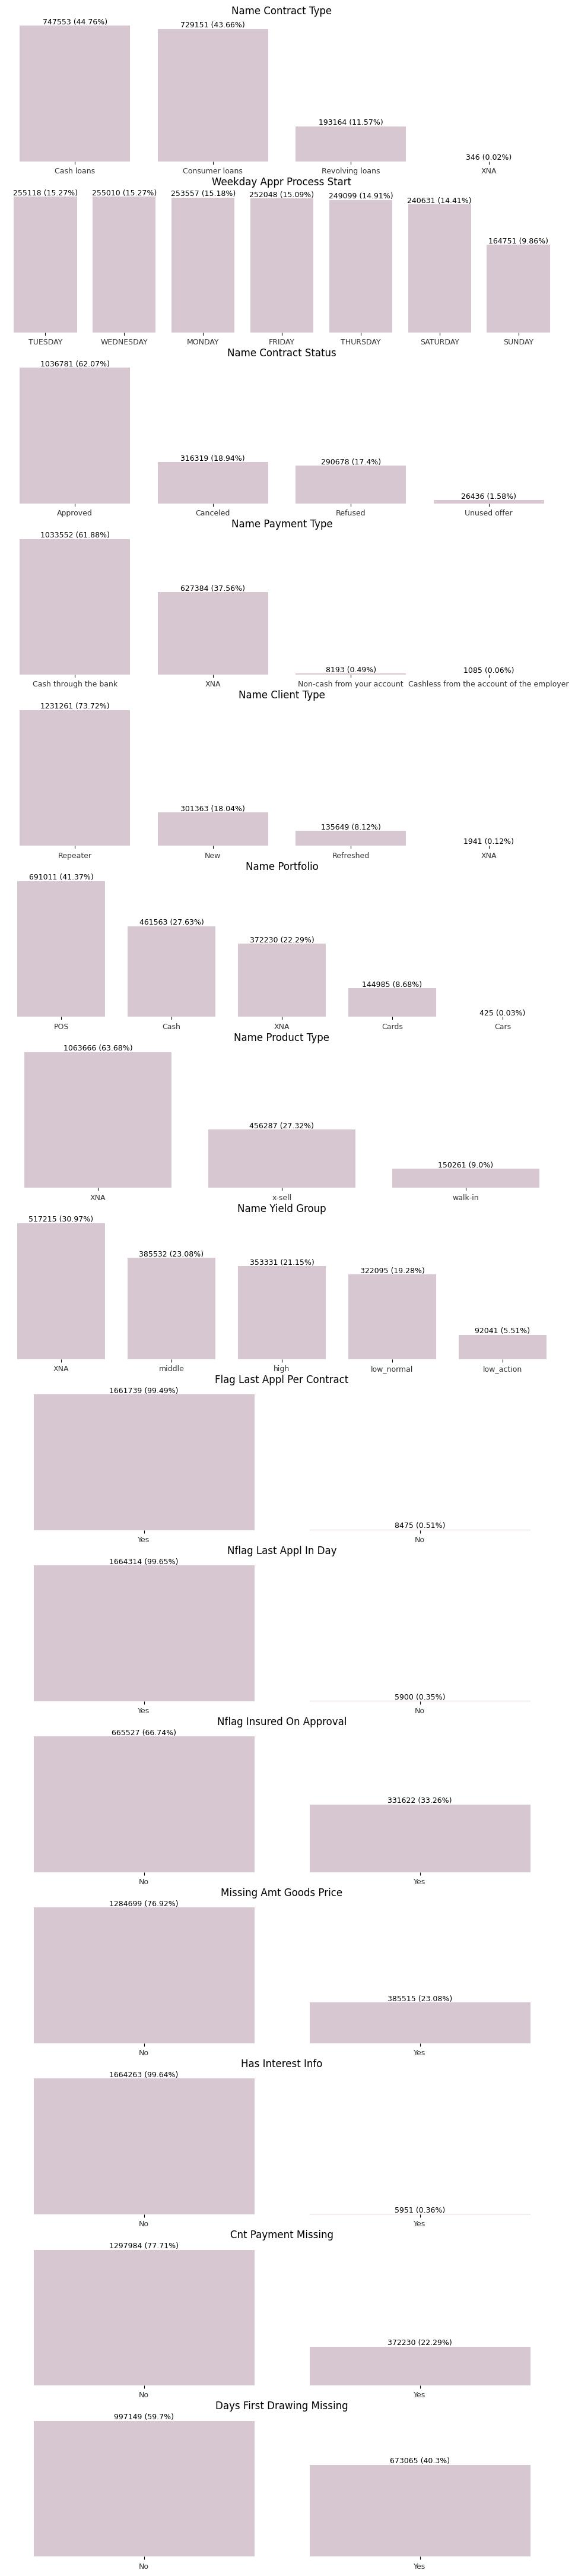

In [159]:
size = len(catbi_f)
fig, axs = plt.subplots(size, 1, figsize=(12, (3.7 * size)))

i = 0
for item in catbi_f:
    temp = previous_application[item].value_counts()
    title = item.replace("_", " ").title()
    ax1 = bar_plot_f_perc(temp, title, color='#dac4d0', ax=axs[i])

    ind = temp.index
    if ind[0] == 0 and ind[1] == 1:
        ax1.set_xticklabels(['No', 'Yes'])
    if ind[0] == 1 and ind[1] == 0:
        ax1.set_xticklabels(['Yes', 'No'])

    i += 1

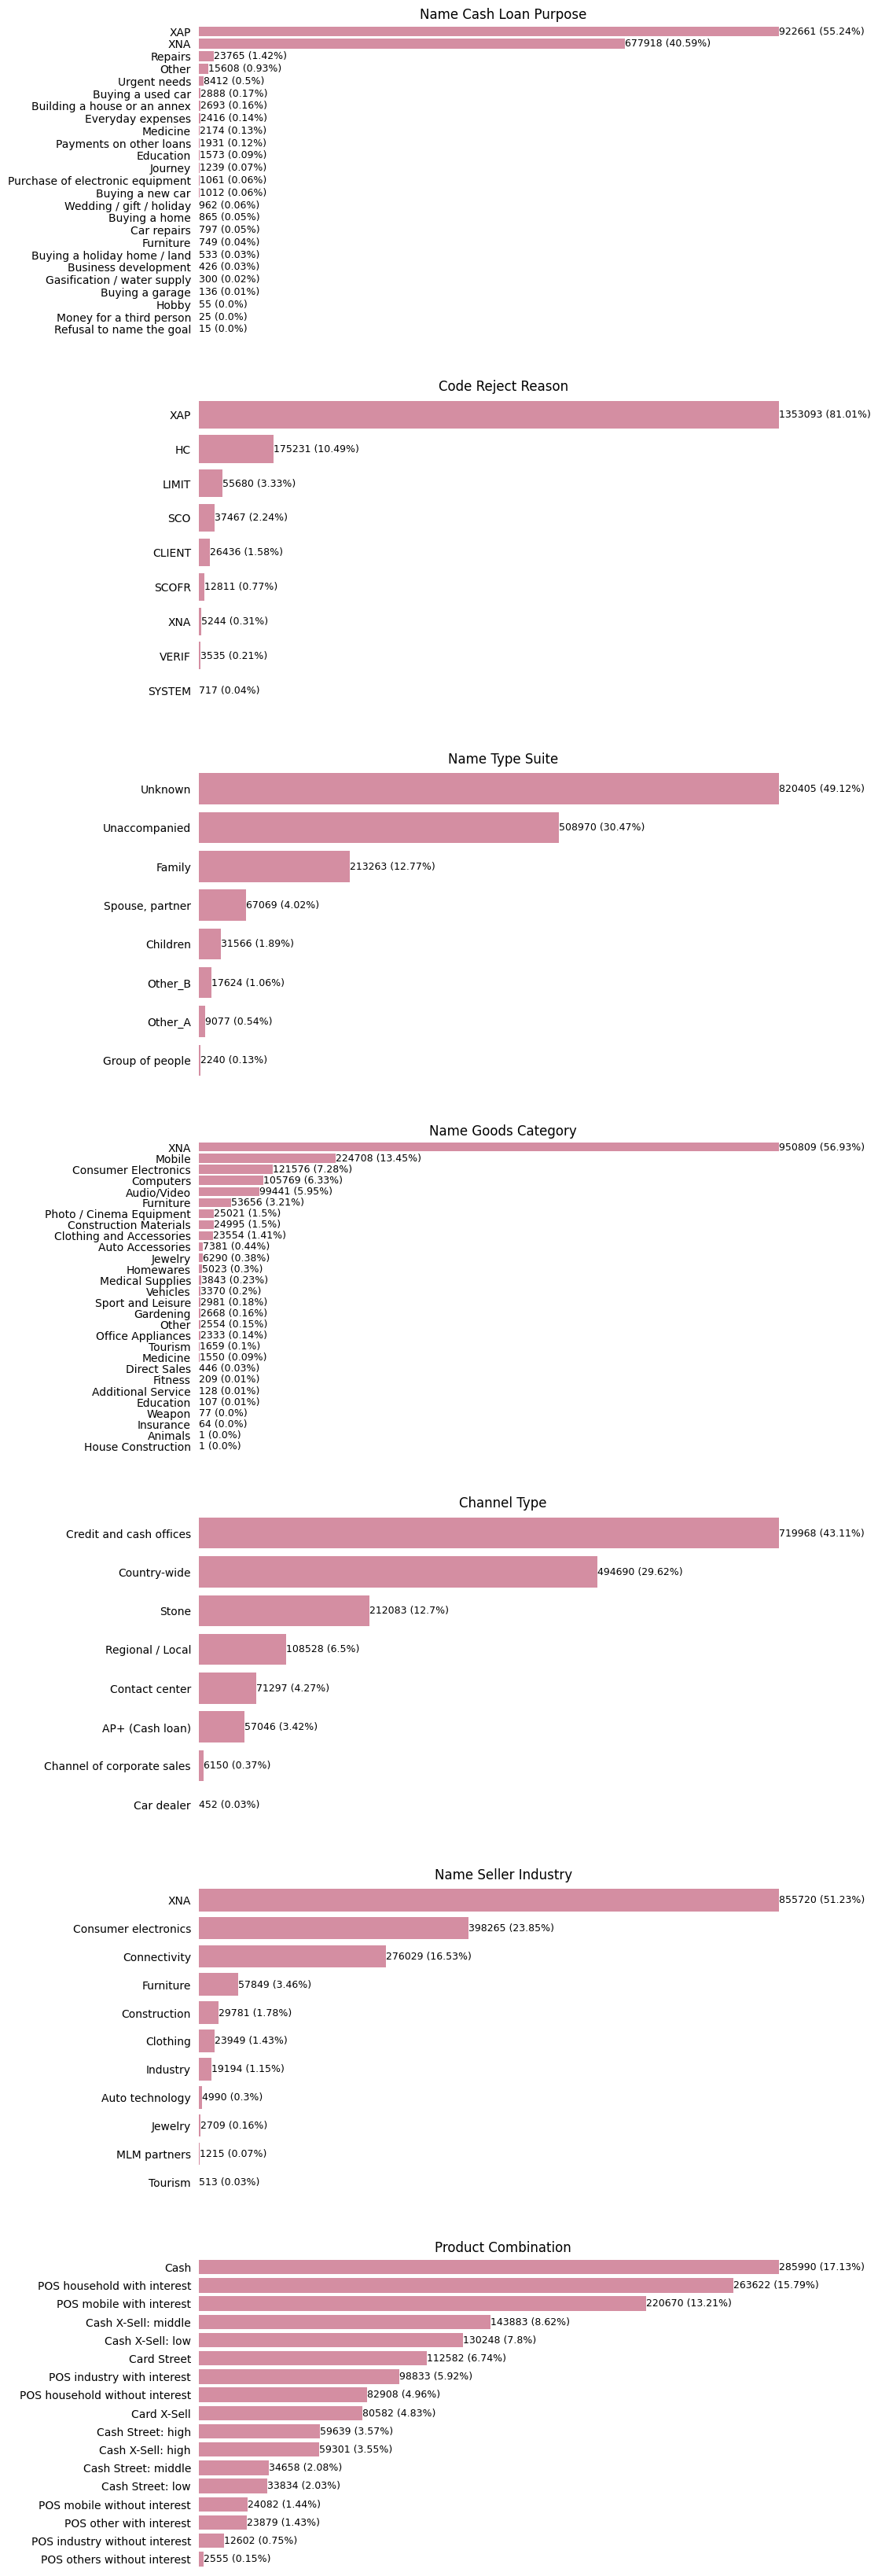

In [160]:
size = len(long_cat)
fig, axs = plt.subplots(size, 1, figsize=(10, (6 * size)))

i = 0
for item in long_cat:
    temp = previous_application[item].value_counts()
    title = item.replace("_", " ").title()
    ax1 = bar_plot_f_perc_horizontal(temp, title, color='#e0829d', ax=axs[i])
    i += 1

Some of the categories are rare compared to others, therefore they will be reduced during agregation part.

## Agregations

In [161]:
aggregations = {
    'AMT_ANNUITY': ['mean'],
    'AMT_APPLICATION': ['mean', 'max'],
    'AMT_CREDIT': ['mean'],
    'AMT_DOWN_PAYMENT': ['min', 'mean'],
    'AMT_GOODS_PRICE': ['mean'],
    'HOUR_APPR_PROCESS_START': ['mean'],
    'RATE_DOWN_PAYMENT': ['mean'],
    'RATE_INTEREST_PRIMARY': ['mean'],
    'RATE_INTEREST_PRIVILEGED': ['mean'],
    'DAYS_DECISION': ['mean'],
    'SELLERPLACE_AREA': ['mean'],
    'CNT_PAYMENT': ['min', 'mean'],
    'DAYS_FIRST_DRAWING': ['mean'],
    'DAYS_FIRST_DUE': ['mean'],
    'DAYS_TERMINATION': ['mean'],
    'FLAG_LAST_APPL_PER_CONTRACT': ['min'],
    'NFLAG_LAST_APPL_IN_DAY': ['min'],
    'NFLAG_INSURED_ON_APPROVAL': ['mean', 'max'],
    'MISSING_AMT_GOODS_PRICE': ['mean', 'max'],
    'HAS_INTEREST_INFO': ['max'],
    'CNT_PAYMENT_MISSING': ['mean', 'max'],
    'DAYS_FIRST_DRAWING_MISSING': ['mean', 'max'],
}

prev_app_agg = previous_application.groupby('SK_ID_CURR').agg(aggregations)
prev_app_agg.columns = ['PREV_' + '_'.join(col).upper() for col in prev_app_agg.columns]
prev_app_agg.reset_index(inplace=True)

query = """
with t1 as (
    SELECT 
        SK_ID_CURR,
        COUNT(DISTINCT SK_ID_PREV) AS NUM_PREV_APPLICATIONS,
        CASE WHEN COUNT(DISTINCT SK_ID_PREV) > 0 THEN 1 ELSE 0 END AS HAS_PREV_APPLICATION,
        SUM(CASE WHEN NAME_CONTRACT_TYPE = 'Cash loans' THEN 1 ELSE 0 END) AS CASH_LOAN,
        SUM(CASE WHEN NAME_CONTRACT_TYPE = 'Consumer loans' THEN 1 ELSE 0 END) AS CONSUMER_LOAN,
        SUM(CASE WHEN NAME_CONTRACT_TYPE = 'Revolving loans' THEN 1 ELSE 0 END) AS REVOLVING_LOAN,
        SUM(CASE WHEN NAME_CONTRACT_STATUS = 'Approved' THEN 1 ELSE 0 END) AS CONTRACT_APPROVED,
        SUM(CASE WHEN NAME_PAYMENT_TYPE = 'Cash through the bank' THEN 1 ELSE 0 END) AS PAY_TYPE_BANK,
        SUM(CASE WHEN NAME_PAYMENT_TYPE IN ('Non-cash from your account', 
        'Cashless from the account of the employer') THEN 1 ELSE 0 END) AS PAY_TYPE_OTHER,
        SUM(CASE WHEN NAME_PORTFOLIO = 'POS' THEN 1 ELSE 0 END) AS PORTFOLIO_POS,
        SUM(CASE WHEN NAME_PORTFOLIO = 'Cash' THEN 1 ELSE 0 END) AS PORTFOLIO_CASH,
        SUM(CASE WHEN NAME_PORTFOLIO = 'Cards' THEN 1 ELSE 0 END) AS PORTFOLIO_CARDS,
        SUM(CASE WHEN NAME_PORTFOLIO = 'Cars' THEN 1 ELSE 0 END) AS PORTFOLIO_CARS,
        SUM(CASE WHEN NAME_PRODUCT_TYPE = 'x-sell' THEN 1 ELSE 0 END) AS PRODUCT_XSELL,
        SUM(CASE WHEN NAME_PRODUCT_TYPE = 'walk-in' THEN 1 ELSE 0 END) AS PRODUCT_WALKIN,
        SUM(CASE WHEN NAME_YIELD_GROUP = 'low_action' THEN 1 ELSE 0 END) AS YIELD_LOW_ACTION,
        SUM(CASE WHEN NAME_YIELD_GROUP = 'low_normal' THEN 1 ELSE 0 END) AS YIELD_LOW_NORMAL,
        SUM(CASE WHEN NAME_YIELD_GROUP = 'middle' THEN 1 ELSE 0 END) AS YIELD_MIDDLE,
        SUM(CASE WHEN NAME_YIELD_GROUP = 'high' THEN 1 ELSE 0 END) AS YIELD_HIGH,
        SUM(CASE WHEN NAME_CASH_LOAN_PURPOSE = 'XAP' THEN 1 ELSE 0 END) AS CASH_LOAN_PURPOSE_XAP,
        SUM(CASE WHEN NAME_CASH_LOAN_PURPOSE NOT IN ('XAP', 'XNA') THEN 1 ELSE 0 END) AS CASH_LOAN_PURPOSE_OTHER,
        SUM(CASE WHEN CODE_REJECT_REASON = 'XAP' THEN 1 ELSE 0 END) AS CODE_REJECT_REASON_XAP,
        SUM(CASE WHEN CODE_REJECT_REASON NOT IN ('XAP', 'XNA') THEN 1 ELSE 0 END) AS CODE_REJECT_REASON_OTHER,
        SUM(CASE WHEN NAME_TYPE_SUITE = 'Unknown' THEN 1 ELSE 0 END) AS TYPE_SUITE_UNKNOWN,
        SUM(CASE WHEN NAME_TYPE_SUITE = 'Unaccompanied' THEN 1 ELSE 0 END) AS TYPE_SUITE_UNACCOMPANIED,
        SUM(CASE WHEN NAME_TYPE_SUITE = 'Family' THEN 1 ELSE 0 END) AS TYPE_SUITE_FAMILY,
        SUM(CASE WHEN NAME_TYPE_SUITE NOT IN ('Unknown', 'Unaccompanied', 'Family') THEN 1 ELSE 0 END) AS TYPE_SUITE_OTHER,
        SUM(CASE WHEN NAME_GOODS_CATEGORY = 'Mobile' THEN 1 ELSE 0 END) AS GOODS_CATEGORY_MOBILE,
        SUM(CASE WHEN NAME_GOODS_CATEGORY = 'Consumer Electronics' THEN 1 ELSE 0 END) AS GOODS_CATEGORY_ELECTRONICS,
        SUM(CASE WHEN NAME_GOODS_CATEGORY = 'Computers' THEN 1 ELSE 0 END) AS GOODS_CATEGORY_COMPUTERS,
        SUM(CASE WHEN NAME_GOODS_CATEGORY = 'Audio/Video' THEN 1 ELSE 0 END) AS GOODS_CATEGORY_AUDIOVID,
        SUM(CASE WHEN NAME_GOODS_CATEGORY = 'Furniture' THEN 1 ELSE 0 END) AS GOODS_CATEGORY_FURNITURE,
        SUM(CASE WHEN NAME_GOODS_CATEGORY NOT IN ('Mobile', 'Consumer Electronics', 'Computers',
        'Audio/Video', 'Furniture', 'XNA') THEN 1 ELSE 0 END) AS GOODS_CATEGORY_OTHER,
        SUM(CASE WHEN CHANNEL_TYPE = 'Credit and cash offices' THEN 1 ELSE 0 END) AS CHANNEL_OFFICES,
        SUM(CASE WHEN CHANNEL_TYPE = 'Country-wide' THEN 1 ELSE 0 END) AS CHANNEL_COUNTRY_WIDE,
        SUM(CASE WHEN CHANNEL_TYPE = 'Stone' THEN 1 ELSE 0 END) AS CHANNEL_STONE,
        SUM(CASE WHEN CHANNEL_TYPE = 'Regional / Local' THEN 1 ELSE 0 END) AS CHANNEL_REGLOCAL,
        SUM(CASE WHEN CHANNEL_TYPE NOT IN ('Credit and cash offices', 'Country-wide', 'Stone',
        'Regional / Local') THEN 1 ELSE 0 END) AS CHANNEL_OTHER,
        SUM(CASE WHEN NAME_SELLER_INDUSTRY = 'Consumer electronics' THEN 1 ELSE 0 END) AS SELLER_INDUSTRY_ELECTRONICS,
        SUM(CASE WHEN NAME_SELLER_INDUSTRY = 'Connectivity' THEN 1 ELSE 0 END) AS SELLER_INDUSTRY_CONNECTIVITY,
        SUM(CASE WHEN NAME_SELLER_INDUSTRY NOT IN ('Consumer electronics', 'Connectivity', 'XNA') THEN 1 ELSE 0 END) AS SELLER_INDUSTRY_OTHER,
        SUM(CASE WHEN PRODUCT_COMBINATION = 'Cash' THEN 1 ELSE 0 END) AS PRODUCT_COMBO_CASH,
        SUM(CASE WHEN PRODUCT_COMBINATION IN ('POS household with interest', 'POS mobile with interest', 
        'POS other with interest', 'POS industry with interest') THEN 1 ELSE 0 END) AS PRODUCT_COMBO_POS_WITH_INTEREST,
        SUM(CASE WHEN PRODUCT_COMBINATION IN ('POS household without interest', 'POS mobile without interest', 
        'POS industry without interest', 'POS others without interest') THEN 1 ELSE 0 END) AS PRODUCT_COMBO_POS_WITHOUT_INTEREST,
        SUM(CASE WHEN PRODUCT_COMBINATION IN ('Cash X-Sell: low', 'Cash X-Sell: high',  
        'Cash X-Sell: middle', 'Card X-Sell') THEN 1 ELSE 0 END) AS PRODUCT_COMBO_XSELL,
        SUM(CASE WHEN PRODUCT_COMBINATION IN ('Cash Street: high', 'Card Street', 
        'Cash Street: low', 'Cash Street: middle') THEN 1 ELSE 0 END) AS PRODUCT_COMBO_CASHSTREET
    FROM previous_application
    GROUP BY SK_ID_CURR
    )

SELECT *
FROM prev_app_agg pa
JOIN t1
ON pa.SK_ID_CURR = t1.SK_ID_CURR;
"""

prev_app_agg = db.sql(query).df().drop(['SK_ID_CURR_1'], axis=1)
prev_app_agg.iloc[:, 1:].describe()

FloatProgress(value=0.0, layout=Layout(width='auto'), style=ProgressStyle(bar_color='black'))

,PREV_AMT_ANNUITY_MEAN,PREV_AMT_APPLICATION_MEAN,PREV_AMT_APPLICATION_MAX,PREV_AMT_CREDIT_MEAN,PREV_AMT_DOWN_PAYMENT_MIN,PREV_AMT_DOWN_PAYMENT_MEAN,PREV_AMT_GOODS_PRICE_MEAN,PREV_HOUR_APPR_PROCESS_START_MEAN,PREV_RATE_DOWN_PAYMENT_MEAN,PREV_RATE_INTEREST_PRIMARY_MEAN,...,CHANNEL_REGLOCAL,CHANNEL_OTHER,SELLER_INDUSTRY_ELECTRONICS,SELLER_INDUSTRY_CONNECTIVITY,SELLER_INDUSTRY_OTHER,PRODUCT_COMBO_CASH,PRODUCT_COMBO_POS_WITH_INTEREST,PRODUCT_COMBO_POS_WITHOUT_INTEREST,PRODUCT_COMBO_XSELL,PRODUCT_COMBO_CASHSTREET
count,338377.000000,3.388570e+05,3.388570e+05,3.388570e+05,3.187530e+05,3.187530e+05,3.377930e+05,338857.000000,318753.000000,5721.000000,...,338857.000000,338857.000000,338857.000000,338857.000000,338857.000000,338857.000000,338857.000000,338857.000000,338857.000000,338857.000000
mean,14656.028970,1.544683e+05,3.775473e+05,1.703318e+05,3.975135e+03,7.118134e+03,1.953843e+05,12.672903,0.081418,0.188730,...,0.320277,0.398236,1.175319,0.814588,0.413744,0.843984,1.791328,0.360468,1.221796,0.710368
std,10093.856491,1.526145e+05,4.219383e+05,1.649810e+05,1.560765e+04,1.827759e+04,1.924749e+05,2.776552,0.089588,0.088609,...,0.738322,1.124562,1.456980,1.241655,0.794208,1.674759,1.654837,0.704692,1.844119,1.396220
min,0.000000,0.000000e+00,0.000000e+00,0.000000e+00,-9.000000e-01,-2.250000e-01,0.000000e+00,0.000000,-0.000007,0.034781,...,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
25%,7908.423750,6.259770e+04,9.957150e+04,6.741675e+04,0.000000e+00,0.000000e+00,7.460550e+04,11.000000,0.000000,0.160716,...,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,1.000000,0.000000,0.000000,0.000000
50%,12092.197500,1.068345e+05,2.105100e+05,1.181655e+05,0.000000e+00,3.355071e+03,1.303740e+05,12.769231,0.065161,0.189122,...,0.000000,0.000000,1.000000,0.000000,0.000000,0.000000,1.000000,0.000000,1.000000,0.000000
75%,18489.159000,1.916936e+05,4.635000e+05,2.164125e+05,3.600000e+03,8.325000e+03,2.475000e+05,14.500000,0.108913,0.193330,...,0.000000,0.000000,2.000000,1.000000,1.000000,1.000000,2.000000,1.000000,2.000000,1.000000
max,300425.445000,4.050000e+06,6.905160e+06,4.050000e+06,2.025000e+06,2.025000e+06,4.050000e+06,23.000000,0.989740,1.000000,...,21.000000,57.000000,48.000000,53.000000,41.000000,62.000000,46.000000,24.000000,51.000000,42.000000


In [162]:
result = prev_app_agg.isnull().sum()
rows_nr = prev_app_agg.shape[0]
for item in prev_app_agg.columns:
    missing_nr = result[item]
    if missing_nr > 0:
        missing_perc = count_percentage(missing_nr, rows_nr, round_value=4)
        print(f'The percentage of missing {item} values is {missing_perc}%.')

The percentage of missing PREV_AMT_ANNUITY_MEAN values is 0.1417%.
The percentage of missing PREV_AMT_DOWN_PAYMENT_MIN values is 5.9329%.
The percentage of missing PREV_AMT_DOWN_PAYMENT_MEAN values is 5.9329%.
The percentage of missing PREV_AMT_GOODS_PRICE_MEAN values is 0.314%.
The percentage of missing PREV_RATE_DOWN_PAYMENT_MEAN values is 5.9329%.
The percentage of missing PREV_RATE_INTEREST_PRIMARY_MEAN values is 98.3117%.
The percentage of missing PREV_RATE_INTEREST_PRIVILEGED_MEAN values is 98.3117%.
The percentage of missing PREV_CNT_PAYMENT_MIN values is 0.1411%.
The percentage of missing PREV_CNT_PAYMENT_MEAN values is 0.1411%.
The percentage of missing PREV_DAYS_FIRST_DRAWING_MEAN values is 0.4477%.
The percentage of missing PREV_DAYS_FIRST_DUE_MEAN values is 0.4477%.
The percentage of missing PREV_DAYS_TERMINATION_MEAN values is 0.4477%.
The percentage of missing PREV_NFLAG_INSURED_ON_APPROVAL_MEAN values is 0.4477%.
The percentage of missing PREV_NFLAG_INSURED_ON_APPROVAL_M

### Charts for Aggregations

In [163]:
num_bi_f = prev_app_agg.iloc[:, 1:].select_dtypes(include=['float', 'int']).columns
num_f = []
bi_f = []

for item in num_bi_f:
    if len(prev_app_agg[item].dropna().unique()) > 2:
        num_f.append(item)
    else:
        bi_f.append(item)
bi_f.remove('HAS_PREV_APPLICATION')



In [164]:
size = round(len(num_f) / 2)

fig, axs = plt.subplots(size, 2, figsize=(12, size * 4))

i = 0
j = 0
for item in num_f:
    if item in ['PREV_AMT_ANNUITY_MEAN']:
        binw = 1000
    elif item in [
        'PREV_AMT_APPLICATION_MEAN',
        'PREV_AMT_APPLICATION_MAX',
        'PREV_AMT_CREDIT_MEAN',
        'PREV_AMT_GOODS_PRICE_MEAN',
        'PREV_SELLERPLACE_AREA_MEAN',
    ]:
        binw = 100000
    elif item in ['PREV_AMT_DOWN_PAYMENT_MIN', 'PREV_AMT_DOWN_PAYMENT_MEAN']:
        binw = 50000
    elif item in ['PREV_HOUR_APPR_PROCESS_START_MEAN']:
        binw = 0.5
    elif item in ['PREV_RATE_DOWN_PAYMENT_MEAN', 'PREV_RATE_INTEREST_PRIMARY_MEAN']:
        binw = 0.01
    elif item in ['PREV_DAYS_DECISION_MEAN']:
        binw = 25
    elif item in [
        'PREV_CNT_PAYMENT_MIN',
        'PREV_CNT_PAYMENT_MEAN',
        'NUM_PREV_APPLICATIONS',
        'CASH_LOAN',
        'CONSUMER_LOAN',
        'REVOLVING_LOAN',
        'CONTRACT_APPROVED',
        'PAY_TYPE_BANK',
        'PAY_TYPE_OTHER',
        'PORTFOLIO_POS',
        'PORTFOLIO_CASH',
        'PORTFOLIO_CARDS',
        'PORTFOLIO_CARS',
        'PRODUCT_XSELL',
        'PRODUCT_WALKIN',
        'YIELD_LOW_ACTION',
        'YIELD_LOW_NORMAL',
        'YIELD_MIDDLE',
        'YIELD_HIGH',
        'CASH_LOAN_PURPOSE_XAP',
        'CASH_LOAN_PURPOSE_OTHER',
        'CODE_REJECT_REASON_XAP',
        'CODE_REJECT_REASON_OTHER',
        'TYPE_SUITE_UNKNOWN',
        'TYPE_SUITE_UNACCOMPANIED',
        'TYPE_SUITE_FAMILY',
        'TYPE_SUITE_OTHER',
        'GOODS_CATEGORY_MOBILE',
        'GOODS_CATEGORY_ELECTRONICS',
        'GOODS_CATEGORY_COMPUTERS',
        'GOODS_CATEGORY_AUDIOVID',
        'GOODS_CATEGORY_FURNITURE',
        'GOODS_CATEGORY_OTHER',
        'CHANNEL_OFFICES',
        'CHANNEL_COUNTRY_WIDE',
        'CHANNEL_STONE',
        'CHANNEL_REGLOCAL',
        'CHANNEL_OTHER',
        'SELLER_INDUSTRY_ELECTRONICS',
        'SELLER_INDUSTRY_CONNECTIVITY',
        'SELLER_INDUSTRY_OTHER',
        'PRODUCT_COMBO_CASH',
        'PRODUCT_COMBO_POS_WITH_INTEREST',
        'PRODUCT_COMBO_POS_WITHOUT_INTEREST',
        'PRODUCT_COMBO_XSELL',
        'PRODUCT_COMBO_CASHSTREET',
    ]:
        binw = 1
    elif item in ['PREV_DAYS_FIRST_DUE_MEAN']:
        binw = 5000
    elif item in ['CC_CNT_DRAWINGS_OTHER_CURRENT_MEAN']:
        binw = 0.025
    elif item in ['CC_CNT_DRAWINGS_OTHER_CURRENT_MEAN']:
        binw = 0.1
    elif item in ['CC_SK_DPD_MEAN', 'CC_SK_DPD_DEF_MEAN']:
        binw = 25
    else:
        binw = None

    title = item.replace("_", " ").title()
    if j == 0:
        ax0 = histplot_f(
            prev_app_agg[item], color=ch, color_median=cmed, color_mean=cmean, xlabel=title, binwidth=binw, ax=axs[i, 0]
        )
        j += 1

    else:
        ax0 = histplot_f(
            prev_app_agg[item], color=ch, color_median=cmed, color_mean=cmean, xlabel=title, binwidth=binw, ax=axs[i, 1]
        )
        j = 0
        i += 1

    if item in ['PREV_DAYS_FIRST_DRAWING_MEAN', 'PREV_DAYS_FIRST_DUE_MEAN', 'PREV_DAYS_TERMINATION_MEAN']:
        ax0.xaxis.set_major_formatter(FuncFormatter(thousands_formatter));

Majority of the features are skewed. Some are rather iregularly distributed, with a lot of smaller maximums (for example PREV_CNT_PAYMENT_MISSING_MEAN, PREV_RATE_INTEREST_PRIVILEGED_MEAN). PREV_HOUR_APPR_PROCESS_START_MEAN is distributed approximatelly normaly and slightly skewed to the left. 

In [165]:
prev_app_agg.PORTFOLIO_CARS.value_counts()

PORTFOLIO_CARS
0.0    338528
1.0       254
2.0        59
3.0        12
4.0         3
5.0         1
Name: count, dtype: int64

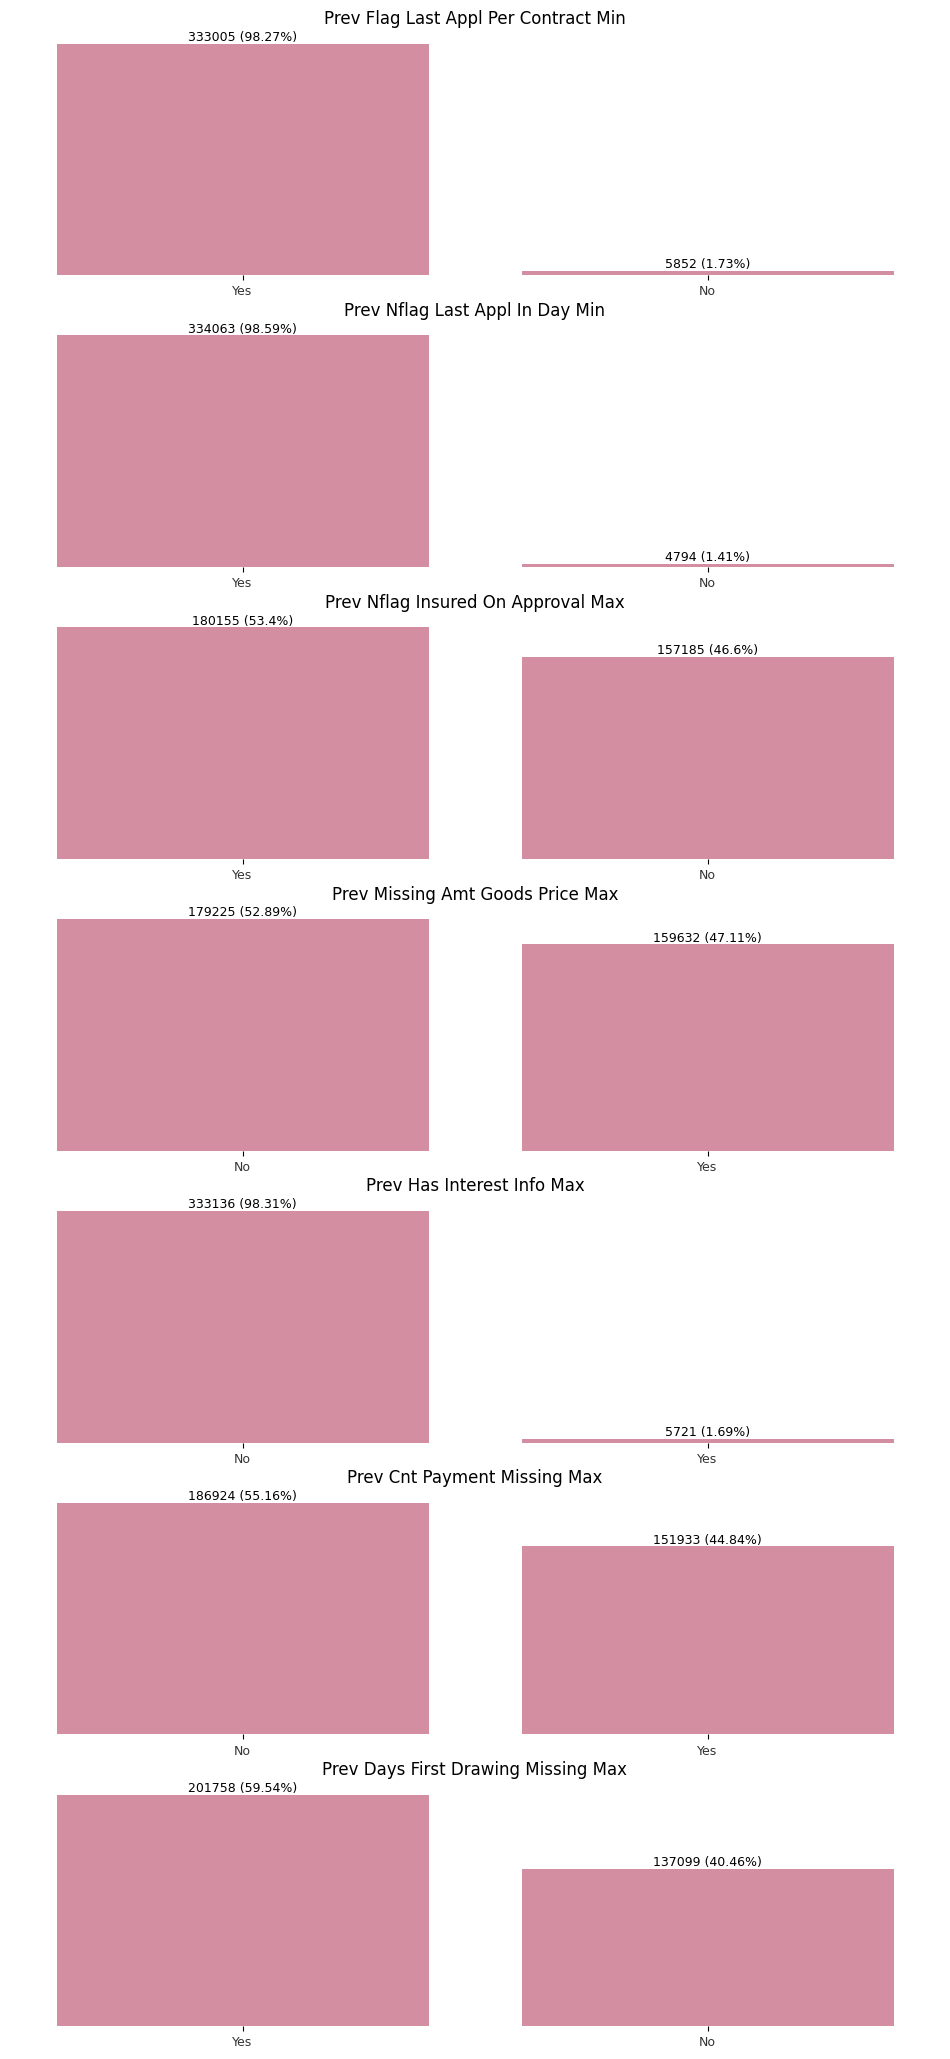

In [166]:
fig, axs = plt.subplots(len(bi_f), 1, figsize=(12, (3.7 * len(bi_f))))

i = 0
for item in bi_f:
    temp = prev_app_agg[item].value_counts()
    title = item.replace("_", " ").title()
    ax1 = bar_plot_f_perc(temp, title, color='#e0829d', ax=axs[i])

    ind = temp.index
    if ind[0] == 0 and ind[1] == 1 and len(ind) == 2:
        ax1.set_xticklabels(['No', 'Yes'])
    if ind[0] == 1 and ind[1] == 0 and len(ind) == 2:
        ax1.set_xticklabels(['Yes', 'No'])

    i += 1

Some of the categories are rare, making the dataset unbalanced.

### Outliers

In [167]:
selected = prev_app_agg[num_f]
outliers = outlier_f(selected)
outliers.count()

PREV_AMT_ANNUITY_MEAN                   15176
PREV_AMT_APPLICATION_MEAN               23624
PREV_AMT_APPLICATION_MAX                33010
PREV_AMT_CREDIT_MEAN                    21636
PREV_AMT_DOWN_PAYMENT_MIN               38040
PREV_AMT_DOWN_PAYMENT_MEAN              22800
PREV_AMT_GOODS_PRICE_MEAN               22757
PREV_HOUR_APPR_PROCESS_START_MEAN        5398
PREV_RATE_DOWN_PAYMENT_MEAN             12231
PREV_RATE_INTEREST_PRIMARY_MEAN           228
PREV_RATE_INTEREST_PRIVILEGED_MEAN         67
PREV_DAYS_DECISION_MEAN                  8504
PREV_SELLERPLACE_AREA_MEAN              40467
PREV_CNT_PAYMENT_MIN                     4229
PREV_CNT_PAYMENT_MEAN                   16809
PREV_DAYS_FIRST_DRAWING_MEAN            62503
PREV_DAYS_FIRST_DUE_MEAN                41145
PREV_DAYS_TERMINATION_MEAN                  0
PREV_NFLAG_INSURED_ON_APPROVAL_MEAN         0
PREV_MISSING_AMT_GOODS_PRICE_MEAN        1426
PREV_CNT_PAYMENT_MISSING_MEAN            1298
PREV_DAYS_FIRST_DRAWING_MISSING_ME

Removing outliers will be tested during modeling.

# Installments Payments

## Checking for Nulls and Duplicates

In [168]:
installments_payments.columns.duplicated().any()

np.False_

In [169]:
installments_payments.duplicated().any()

np.False_

In [170]:
result = installments_payments.isnull().sum()
rows_nr = installments_payments.shape[0]
for item in installments_payments.columns:
    missing_nr = result[item]
    if missing_nr > 0:
        missing_perc = count_percentage(missing_nr, rows_nr, round_value=4)
        print(f'The percentage of missing {item} values is {missing_perc}%.')

The percentage of missing DAYS_ENTRY_PAYMENT values is 0.0214%.
The percentage of missing AMT_PAYMENT values is 0.0214%.


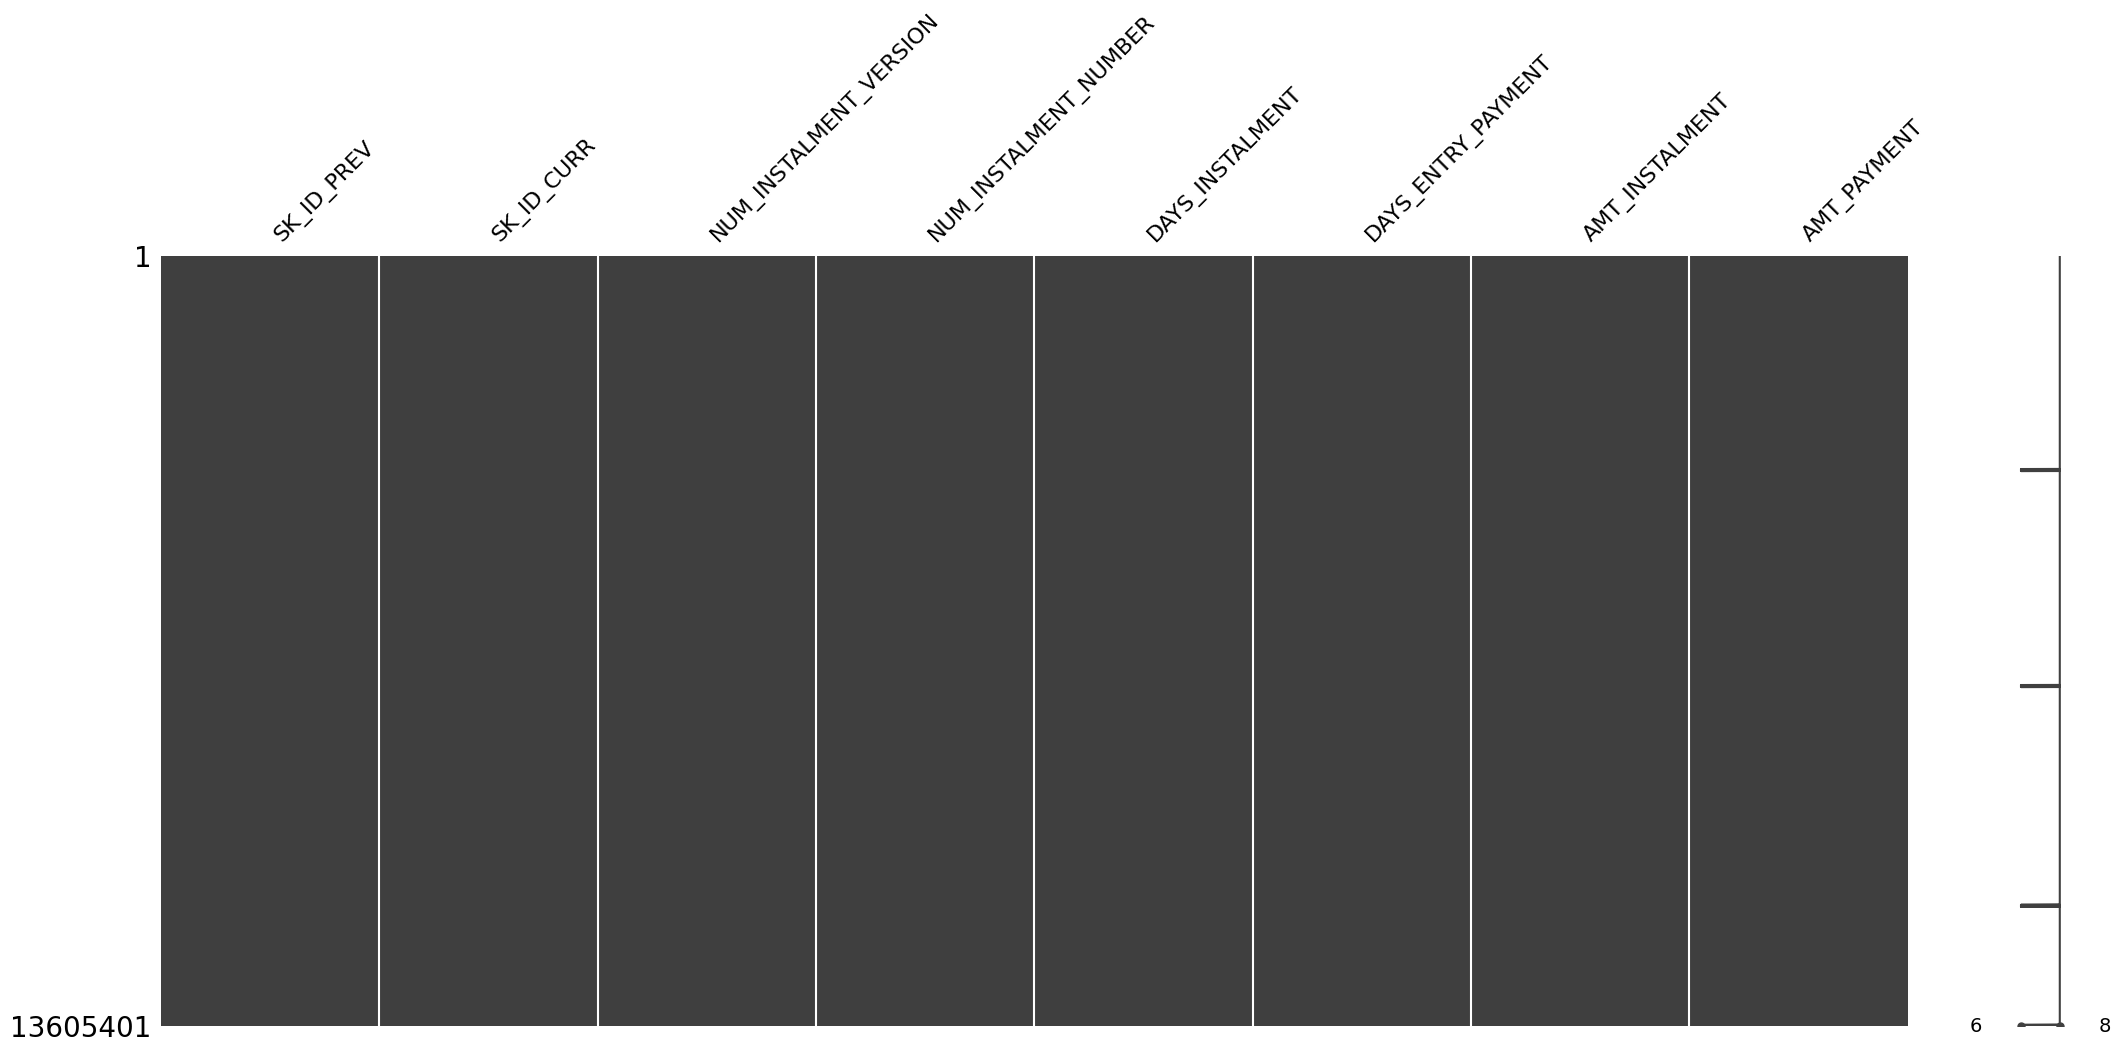

In [171]:
%matplotlib inline

msno.matrix(installments_payments);

The amount of missing payments is low, therefore they won't be investigated further. 

## Exploring Data

In [172]:
query = '''
SELECT * 
FROM HomeCredit_columns_description
WHERE "Table" = 'installments_payments.csv'
'''

info = db.sql(query).df()
info

,Table,Row,Description,Special
0,installments_payments.csv,SK_ID_PREV,ID of previous credit in Home credit related t...,hashed
1,installments_payments.csv,SK_ID_CURR,ID of loan in our sample,hashed
2,installments_payments.csv,NUM_INSTALMENT_VERSION,Version of installment calendar (0 is for cred...,None
3,installments_payments.csv,NUM_INSTALMENT_NUMBER,On which installment we observe payment,None
4,installments_payments.csv,DAYS_INSTALMENT,When the installment of previous credit was su...,time only relative to the application
5,installments_payments.csv,DAYS_ENTRY_PAYMENT,When was the installments of previous credit p...,time only relative to the application
6,installments_payments.csv,AMT_INSTALMENT,What was the prescribed installment amount of ...,None
7,installments_payments.csv,AMT_PAYMENT,What the client actually paid on previous cred...,None


In [173]:
installments_payments.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 13605401 entries, 0 to 13605400
Data columns (total 8 columns):
 #   Column                  Dtype  
---  ------                  -----  
 0   SK_ID_PREV              int64  
 1   SK_ID_CURR              int64  
 2   NUM_INSTALMENT_VERSION  float64
 3   NUM_INSTALMENT_NUMBER   int64  
 4   DAYS_INSTALMENT         float64
 5   DAYS_ENTRY_PAYMENT      float64
 6   AMT_INSTALMENT          float64
 7   AMT_PAYMENT             float64
dtypes: float64(5), int64(3)
memory usage: 830.4 MB


In [174]:
installments_payments_noid = installments_payments.iloc[:, 2:]
installments_payments_noid.describe()

,NUM_INSTALMENT_VERSION,NUM_INSTALMENT_NUMBER,DAYS_INSTALMENT,DAYS_ENTRY_PAYMENT,AMT_INSTALMENT,AMT_PAYMENT
count,1.360540e+07,1.360540e+07,1.360540e+07,1.360250e+07,1.360540e+07,1.360250e+07
mean,8.566373e-01,1.887090e+01,-1.042270e+03,-1.051114e+03,1.705091e+04,1.723822e+04
std,1.035216e+00,2.666407e+01,8.009463e+02,8.005859e+02,5.057025e+04,5.473578e+04
min,0.000000e+00,1.000000e+00,-2.922000e+03,-4.921000e+03,0.000000e+00,0.000000e+00
25%,0.000000e+00,4.000000e+00,-1.654000e+03,-1.662000e+03,4.226085e+03,3.398265e+03
50%,1.000000e+00,8.000000e+00,-8.180000e+02,-8.270000e+02,8.884080e+03,8.125515e+03
75%,1.000000e+00,1.900000e+01,-3.610000e+02,-3.700000e+02,1.671021e+04,1.610842e+04
max,1.780000e+02,2.770000e+02,-1.000000e+00,-1.000000e+00,3.771488e+06,3.771488e+06


In [175]:
installments_payments['DAYS_INST_PAY_DIFF'] = (
    installments_payments['DAYS_INSTALMENT'] - installments_payments['DAYS_ENTRY_PAYMENT']
)
installments_payments['AMT_INST_PAY_DIFF'] = (
    installments_payments['AMT_INSTALMENT'] - installments_payments['AMT_PAYMENT']
)
installments_payments['AMT_INST_PAY_RATIO'] = installments_payments.apply(
    lambda row: row['AMT_INSTALMENT'] / row['AMT_PAYMENT'] if row['AMT_PAYMENT'] != 0 else np.nan, axis=1
)
installments_payments['AMT_INST_PAY_RATIO'] = installments_payments['AMT_INST_PAY_RATIO'].clip(upper=10)

## Aggregatons

In [176]:
installments_payments.columns

Index(['SK_ID_PREV', 'SK_ID_CURR', 'NUM_INSTALMENT_VERSION',
       'NUM_INSTALMENT_NUMBER', 'DAYS_INSTALMENT', 'DAYS_ENTRY_PAYMENT',
       'AMT_INSTALMENT', 'AMT_PAYMENT', 'DAYS_INST_PAY_DIFF',
       'AMT_INST_PAY_DIFF', 'AMT_INST_PAY_RATIO'],
      dtype='object')

In [177]:
aggregations = {
    'NUM_INSTALMENT_VERSION': ['mean'],
    'NUM_INSTALMENT_NUMBER': ['min', 'max', 'mean'],
    'DAYS_INSTALMENT': ['mean'],
    'DAYS_ENTRY_PAYMENT': ['mean'],
    'DAYS_INST_PAY_DIFF': ['mean', 'min'],
    'AMT_INSTALMENT': ['mean'],
    'AMT_PAYMENT': ['mean'],
    'AMT_INST_PAY_DIFF': ['mean', 'max'],
    'AMT_INST_PAY_RATIO': ['mean'],
}

inst_pay_agg = installments_payments.groupby('SK_ID_CURR').agg(aggregations)
inst_pay_agg.columns = ['IP_' + '_'.join(col).upper() for col in inst_pay_agg.columns]
inst_pay_agg.reset_index(inplace=True)

query = '''
with t1 as (
    SELECT 
        SK_ID_CURR,
        COUNT(DISTINCT SK_ID_PREV) AS NUM_INSTALMENT_PAYMENTS,
        CASE WHEN COUNT(DISTINCT SK_ID_PREV) > 0 THEN 1 ELSE 0 END AS HAD_INSTALMENT_PAYMENTS
    FROM installments_payments
    GROUP BY SK_ID_CURR
    ) 

SELECT *
FROM inst_pay_agg ip
JOIN t1
ON ip.SK_ID_CURR = t1.SK_ID_CURR;
'''

inst_pay_agg = db.sql(query).df().drop(['SK_ID_CURR_1'], axis=1)
inst_pay_agg.describe()

,SK_ID_CURR,IP_NUM_INSTALMENT_VERSION_MEAN,IP_NUM_INSTALMENT_NUMBER_MIN,IP_NUM_INSTALMENT_NUMBER_MAX,IP_NUM_INSTALMENT_NUMBER_MEAN,IP_DAYS_INSTALMENT_MEAN,IP_DAYS_ENTRY_PAYMENT_MEAN,IP_DAYS_INST_PAY_DIFF_MEAN,IP_DAYS_INST_PAY_DIFF_MIN,IP_AMT_INSTALMENT_MEAN,IP_AMT_PAYMENT_MEAN,IP_AMT_INST_PAY_DIFF_MEAN,IP_AMT_INST_PAY_DIFF_MAX,IP_AMT_INST_PAY_RATIO_MEAN,NUM_INTALMENT_PAYMENTS,HAD_INSTALMENT_PAYMENTS
count,339587.000000,339587.000000,339587.000000,339587.000000,339587.000000,339587.000000,339578.000000,339578.000000,339578.000000,3.395870e+05,3.395780e+05,339578.000000,3.395780e+05,339578.000000,339587.000000,339587.0
mean,278154.892278,1.047498,1.043962,24.515553,9.830926,-910.742831,-922.095504,11.257628,-15.695113,1.861577e+04,1.900381e+04,-390.786264,6.767578e+03,101.827055,2.938134,1.0
std,102880.492598,0.620751,0.747974,30.162714,11.405171,598.571280,597.181989,12.976502,108.718146,2.346509e+04,2.523135e+04,5242.747778,1.523606e+04,1502.430646,2.051316,0.0
min,100001.000000,0.000000,1.000000,1.000000,1.000000,-2922.000000,-3071.000000,-1884.204545,-2884.000000,0.000000e+00,1.890000e-01,-337496.805000,-5.086116e+04,0.000000,1.000000,1.0
25%,189042.500000,1.000000,1.000000,10.000000,4.560000,-1302.113085,-1312.043107,5.888889,-9.000000,7.897470e+03,7.582365e+03,0.000000,0.000000e+00,1.000000,1.000000,1.0
50%,278238.000000,1.018519,1.000000,12.000000,6.045455,-794.967742,-806.576364,9.564103,-1.000000,1.272616e+04,1.240398e+04,0.000000,0.000000e+00,1.000000,2.000000,1.0
75%,367315.500000,1.111111,1.000000,24.000000,9.500000,-421.000000,-433.857143,14.846154,2.000000,2.164516e+04,2.164505e+04,435.855153,9.122062e+03,3.529587,4.000000,1.0
max,456255.000000,39.000000,67.000000,277.000000,144.208145,-3.000000,-3.000000,295.000000,156.000000,2.504590e+06,2.504590e+06,146145.900000,2.424726e+06,340648.544451,26.000000,1.0


### Charts of Aggregations

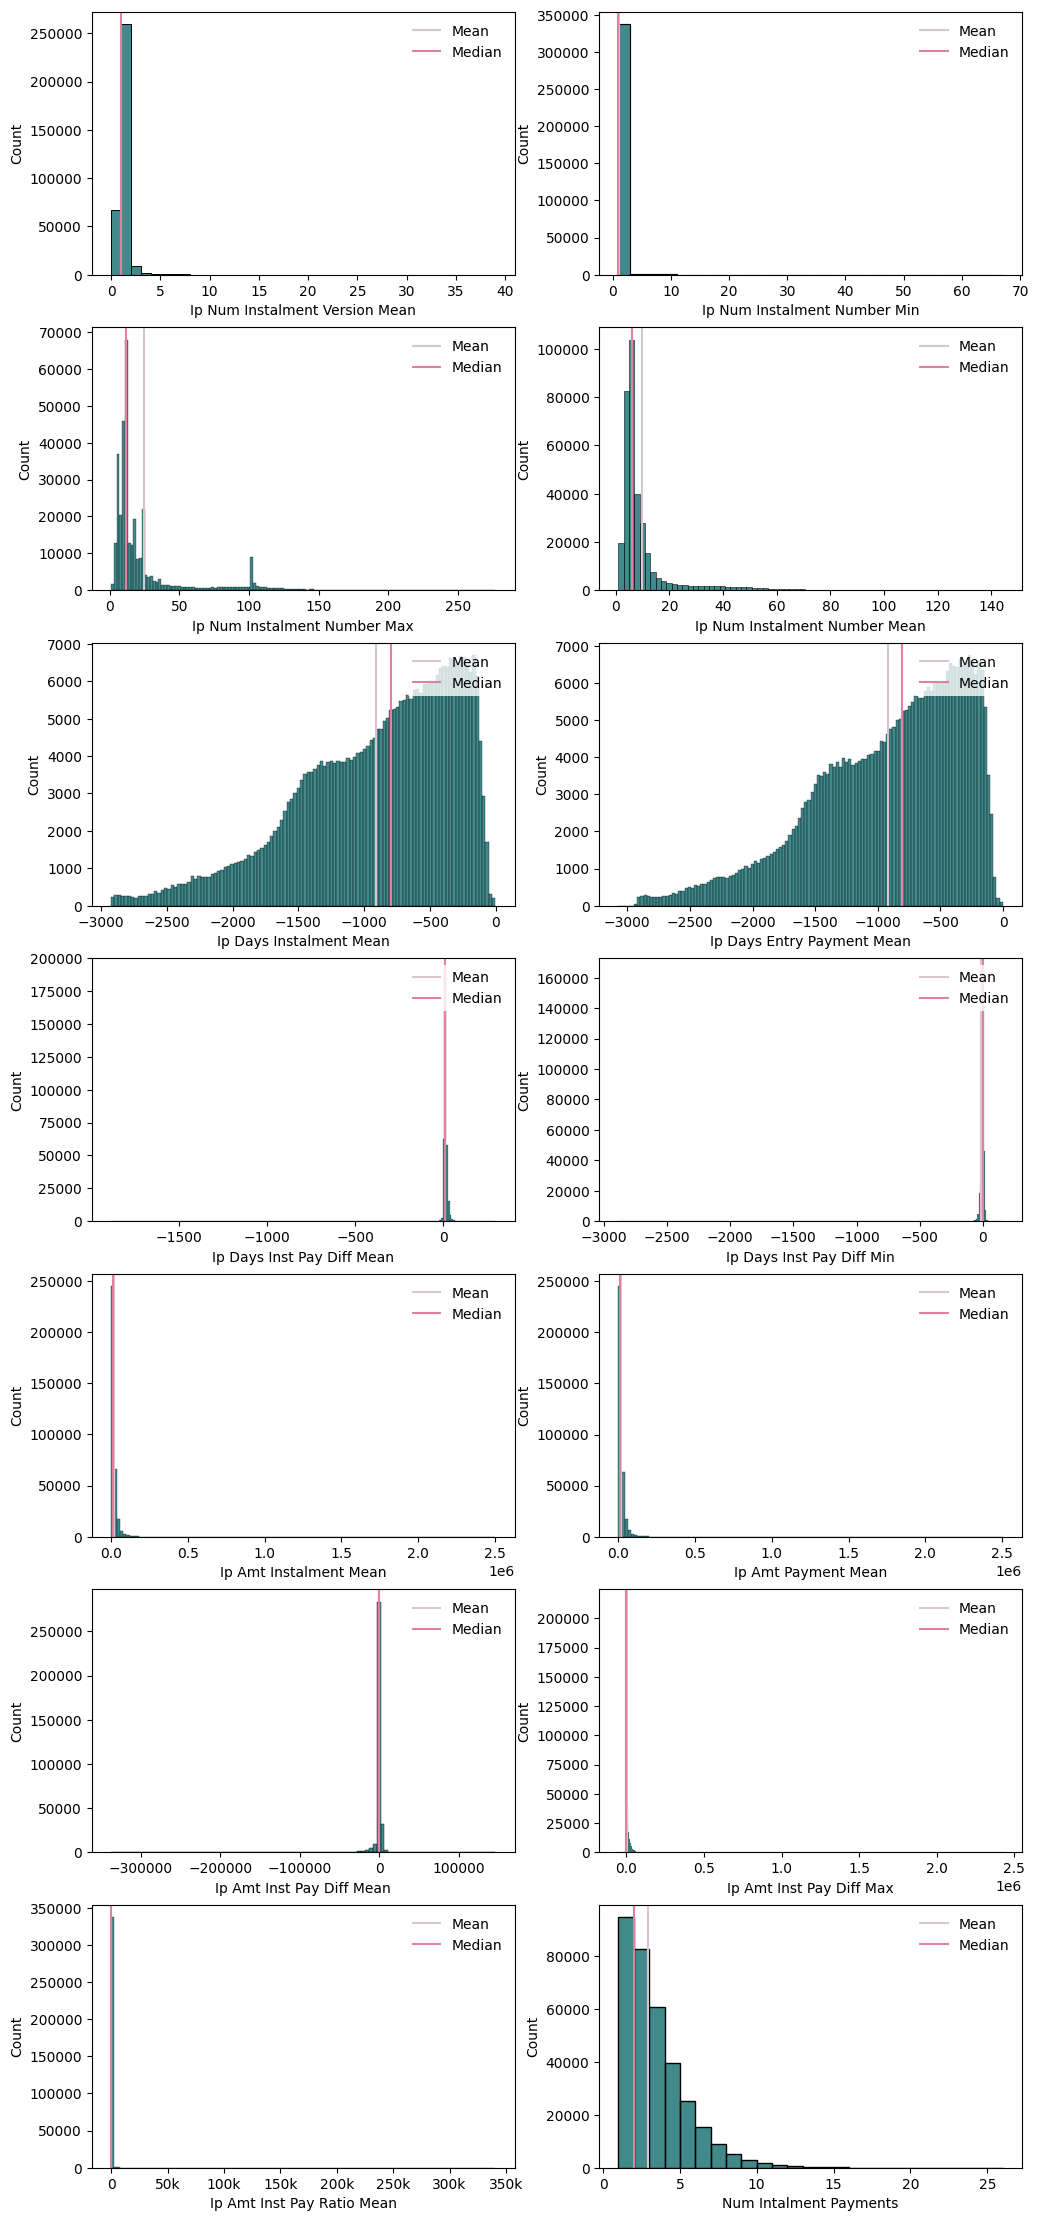

In [178]:
num_f = inst_pay_agg.columns[1:-1]
size = round(len(num_f) / 2)

fig, axs = plt.subplots(size, 2, figsize=(12, size * 4))

i = 0
j = 0
for item in num_f:
    if item in ['IP_NUM_INSTALMENT_VERSION_MEAN', 'NUM_INSTALMENT_PAYMENTS']:
        binw = 1
    elif item in ['IP_NUM_INSTALMENT_NUMBER_MIN', 'IP_NUM_INSTALMENT_NUMBER_MAX', 'IP_NUM_INSTALMENT_NUMBER_MEAN']:
        binw = 2
    elif item in ['IP_DAYS_INST_PAY_DIFF_MEAN', 'IP_DAYS_INST_PAY_DIFF_MIN']:
        binw = 10
    elif item in ['IP_AMT_INSTALMENT_MEAN', 'IP_AMT_PAYMENT_MEAN']:
        binw = 20000
    elif item in ['IP_AMT_INST_PAY_DIFF_MEAN', 'IP_AMT_INST_PAY_DIFF_MAX']:
        binw = 5000
    elif item in ['IP_AMT_INST_PAY_RATIO_MEAN']:
        binw = 2500
    else:
        binw = None

    title = item.replace("_", " ").title()
    if j == 0:
        ax0 = histplot_f(
            inst_pay_agg[item], color=ch, color_median=cmed, color_mean=cmean, xlabel=title, binwidth=binw, ax=axs[i, 0]
        )
        j += 1

    else:
        ax0 = histplot_f(
            inst_pay_agg[item], color=ch, color_median=cmed, color_mean=cmean, xlabel=title, binwidth=binw, ax=axs[i, 1]
        )
        j = 0
        i += 1

    if item in ['IP_AMT_INST_PAY_RATIO_MEAN']:
        ax0.xaxis.set_major_formatter(FuncFormatter(thousands_formatter));

Some of the values are highly skewed, making the charts uninformative, other han seeing tha majority of the values are centered at one place (for example, IP_AMT_INST_PAY_RATIO_MEAN).

## Outliers

In [179]:
selected = inst_pay_agg[num_f]
outliers = outlier_f(selected)
outliers.count()

IP_NUM_INSTALMENT_VERSION_MEAN    104491
IP_NUM_INSTALMENT_NUMBER_MIN        2154
IP_NUM_INSTALMENT_NUMBER_MAX       45198
IP_NUM_INSTALMENT_NUMBER_MEAN      38237
IP_DAYS_INSTALMENT_MEAN             3030
IP_DAYS_ENTRY_PAYMENT_MEAN          3005
IP_DAYS_INST_PAY_DIFF_MEAN         19894
IP_DAYS_INST_PAY_DIFF_MIN          37214
IP_AMT_INSTALMENT_MEAN             25775
IP_AMT_PAYMENT_MEAN                27962
IP_AMT_INST_PAY_DIFF_MEAN          83543
IP_AMT_INST_PAY_DIFF_MAX           29887
IP_AMT_INST_PAY_RATIO_MEAN         68114
NUM_INTALMENT_PAYMENTS              7166
dtype: int64

Removing outliers will be tested during modeling.

# End of Part 2 

In this part, supplementary data has been overviewed. The data has been aggregated according to the clients id. Majority of the features aren't distributed normaly and are highly skewed with a lot of outliers.

In part 3 of this project data of supplementary features and the main applicaton data will be connected. After that charts relating to the target, correlation and hypothesis testing will be done.